# Network Intrusion Detection EDA (CIC-IDS2017) - Colab version (revision 2: leakage-safe evaluation)

Run the first cell and select all 8 original CIC-IDS2017 CSV files from your computer.
Run the notebook top to bottom (Runtime > Run all). Stored outputs of every cell that changed were removed, because the numbers change.

## Revision 2 - what changed in this version (methodology review)

Cells marked `[REV2-CHANGED]` or `[REV2-ADDED]` are the edits of this revision. All other cells, and every model/result of the previous version, are kept.
Stored outputs of changed cells were removed; run top to bottom to regenerate them. Save the results of the previous notebook before you compare (this version writes `results_summary_revised.csv`).

| # | Review point | What was done | Where |
|---|---|---|---|
| 1 | Train/test split and feature selection | The stratified 80/20 split is now made **once, before any supervised feature analysis** (`train_idx` / `test_idx`). Variance / near-constant checks, effect size, mutual information, Random-Forest importance and the Pearson correlation analysis now use the training rows only (`df_fs`). Spearman + VIF already used training rows and now reuse the same split. | new split cell before the feature-selection block; feature-selection cells; Spearman/VIF split cell |
| 2 | Preprocessing inside cross-validation | `cv_oof_probs` now fits imputer, signed-log, scaler and one-hot encoder **on each training fold only** (cloned preprocessing, raw frames passed in). This covers the hyper-parameter search, the ensemble weight and the class thresholds. The class-weight validation of the logistic model already fitted its preprocessing on the fit part only, and the final models fit on the training pool and are applied to the test set, as before. | model-definition cell, setup cell, search cell, final-model cell |
| 3 | Session-grouped evaluation | New leave-one-session-out evaluation (one capture file held out at a time) next to the existing random stratified split, with a table of which classes exist in which sessions. | new section before the conclusion |
| 4 | Feature ranking and evaluation consistency | The combined ranking is split into a **binary** ranking (attack vs benign for effect size, mutual information and Random Forest) and a **multi-class** ranking (one-vs-rest effect size, multi-class mutual information, multi-class Random Forest). Ranks are only averaged within one target definition. The conclusion states which metric is which. | feature-ranking cells, conclusion |
| 5 | Validation and reproducibility | Dataset-integrity checks after cleaning, feature-leakage checks after the modelling split (identifier columns, single-feature AUC screen, exact train/test feature-vector overlap), library versions and seeds at the top, and a `run_config.json` with every setting and result summary at the end. | new cells |

Known limits, stated plainly: the 8 capture sessions are confounded with attack type (most attack classes occur in a single session), so a session-held-out score for a class that exists in only one session measures *detection of an unseen attack*, not classification; and Spearman/VIF feature selection was done on the random-split training rows, which include rows from every session.

---

## Change log (this version vs. the previous notebook)

Cells whose first line is marked `[CHANGED]` or `[ADDED]` are the only edits; everything else is as before.
Stored outputs from the TCP-indicator cell onward were removed because the fixes below change those numbers; run the notebook top to bottom to regenerate them.

| Item | What | Where |
|------|------|-------|
| 3a | `-1` sentinel bug: flags `forward_unknown` / `backward_unknown` are created once, before `-1` becomes NaN, and are no longer recomputed (they were two all-zero columns) | TCP-indicator cell, `Correct indicator names` cell (now a check only) |
| 1 | Models use exactly `df_train` / `df_test` (split stratified on the original `Label`) instead of a second, different split | Spearman/VIF split cell, `Splitting Training and test data` |
| 3b | Custom logistic weights chosen on a validation split inside the training data; the test set is scored once afterwards | new cells before `Custom-weighted Logistic Regression` |
| 2 | Port-group ablation: new setup G (port group, no raw port) and a 2-row table, headline model with vs without `Destination_Port_Group` | model cells, new cell after the A-vs-B port test |
| 1 | Progression table and chart: logistic baseline -> XGBoost / NN / ensemble on the same columns | new cell after the comparison table |
| 4 | joblib export of preprocessing + best model, and a demo function (verdict, family, confidence, top-3 SHAP features); no Streamlit | last cells |

The `(Section ??)` placeholders are in the PDF report, not in this notebook.

In [ ]:
# Upload all 8 original CIC-IDS2017 CSV files
# (select all 8 files together in the dialog that opens)
import os, shutil, glob
from google.colab import files

UPLOAD_DIR = "Network_Intrusion_Dataset"
if os.path.isdir(UPLOAD_DIR):
    shutil.rmtree(UPLOAD_DIR)          # helps start clean so no stale files get combined
os.makedirs(UPLOAD_DIR)

uploaded = files.upload()

for name in uploaded:
    shutil.move(name, os.path.join(UPLOAD_DIR, name))

found = sorted(os.listdir(UPLOAD_DIR))
print("\nFiles received (%d):" % len(found))
for f in found:
    print("  ", f)
assert len(found) == 8 and all(f.endswith(".csv") for f in found), \
    "Expected exactly 8 CSV files. Re-run this cell and select all 8 original CIC-IDS2017 CSVs."


Saving Wednesday-workingHours.pcap_ISCX.csv to Wednesday-workingHours.pcap_ISCX.csv
Saving Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv to Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Saving Tuesday-WorkingHours.pcap_ISCX.csv to Tuesday-WorkingHours.pcap_ISCX.csv
Saving Monday-WorkingHours.pcap_ISCX.csv to Monday-WorkingHours.pcap_ISCX.csv
Saving Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv to Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Saving Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv to Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Saving Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv to Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Saving Friday-WorkingHours-Morning.pcap_ISCX.csv to Friday-WorkingHours-Morning.pcap_ISCX.csv

Files received (8):
   Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
   Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
   Friday-WorkingHours-Morning.pcap_ISCX.csv
   Monday-Workin

In [ ]:
import pandas as pd
import glob
files = sorted(glob.glob("Network_Intrusion_Dataset/*.csv"))  # files uploaded in the previous cell, combined in filename order
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, silhouette_score

In [ ]:
# [REV2-ADDED] Reproducibility: seeds and library versions (printed once, saved to run_config.json at the end)
import sys, platform, random, importlib
SEED = 42
random.seed(SEED); np.random.seed(SEED)
ENV_VERSIONS = {"python": sys.version.split()[0], "platform": platform.platform()}
for _m in ["numpy", "pandas", "scipy", "sklearn", "xgboost", "statsmodels", "matplotlib", "seaborn", "joblib"]:
    try:
        ENV_VERSIONS[_m] = importlib.import_module(_m).__version__
    except Exception:
        ENV_VERSIONS[_m] = "not installed yet"
print("Global seed:", SEED)
for _k, _v in ENV_VERSIONS.items():
    print(f"  {_k:<12}{_v}")
print("(xgboost / statsmodels are imported later; their versions are re-recorded at the end.)")

Global seed: 42
  python      3.13.18
  platform    Linux-6.6.159+-x86_64-with-glibc2.39
  numpy       2.4.6
  pandas      2.2.3
  scipy       1.16.3
  sklearn     1.6.1
  xgboost     3.4.1
  statsmodels 0.15.0
  matplotlib  3.10.0
  seaborn     0.13.2
  joblib      1.6.0
(xgboost / statsmodels are imported later; their versions are re-recorded at the end.)


In [ ]:
pd.set_option ("display.max_columns",100)
pd.set_option ("display.max_rows",100)

In [ ]:
parts = []

for f in files:
    d = pd.read_csv(f,encoding="latin1",low_memory=False)
    d.columns = d.columns.str.strip()
    d["session"] = os.path.basename(f).replace(".pcap_ISCX.csv","")
    print(f"{d['session'].iloc[0]:<45}{d.shape}")
    parts.append(d)

df = pd.concat(parts,ignore_index=True)
del parts

df["Label"] = df["Label"].str.replace(r"[^\x00-\x7F]+", "-", regex=True).str.strip()
num_cols = df.select_dtypes("number").columns
df[num_cols] = df[num_cols].astype("float32")
print("Combined:",df.shape)

Friday-WorkingHours-Afternoon-DDos           (225745, 80)
Friday-WorkingHours-Afternoon-PortScan       (286467, 80)
Friday-WorkingHours-Morning                  (191033, 80)
Monday-WorkingHours                          (529918, 80)
Thursday-WorkingHours-Afternoon-Infilteration(288602, 80)
Thursday-WorkingHours-Morning-WebAttacks     (170366, 80)
Tuesday-WorkingHours                         (445909, 80)
Wednesday-workingHours                       (692703, 80)
Combined: (2830743, 80)


Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
Destination Port,,,,,,,,,,,,,,,
well-known,0.783,0.000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.157,1.0,1.0,1.0,1.0
registered,0.085,0.768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.788,0.0,0.0,0.0,0.0
dynamic,0.132,0.232,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.055,0.0,0.0,0.0,0.0


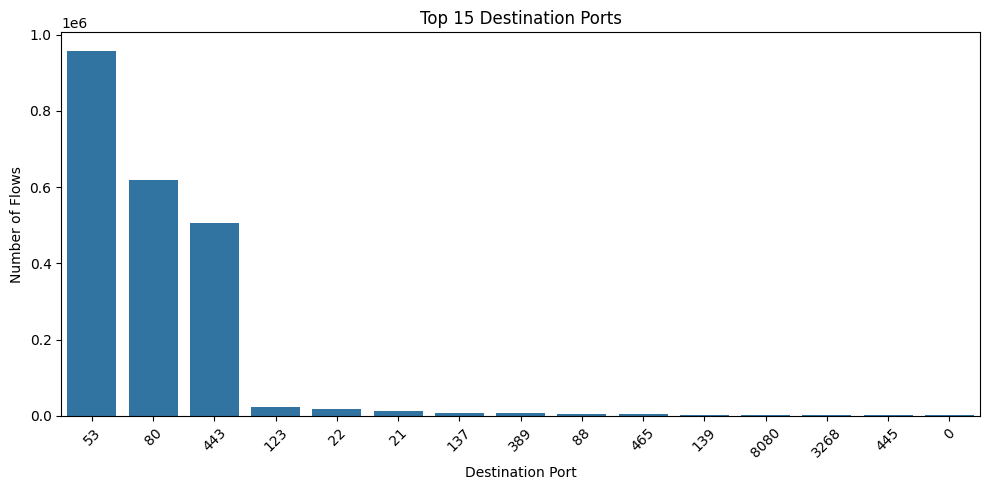

In [ ]:
# Protocol distribution by traffic class
if "Protocol" in df.columns:
    display(pd.crosstab(df["Protocol"], df["Label"]))

# Destination Port analysis
port = df["Destination Port"].astype(int)

port_group = pd.cut(
    port,
    [-1, 1023, 49151, 65535],
    labels=["well-known", "registered", "dynamic"]
)

display(pd.crosstab(port_group, df["Label"], normalize="columns").round(3))

# Most common destination ports
top_ports = port.value_counts().head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_ports.index.astype(str), y=top_ports.values)
plt.xlabel("Destination Port")
plt.ylabel("Number of Flows")
plt.title("Top 15 Destination Ports")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

                              count     pct
Label                                      
BENIGN                      2273097  80.300
DoS Hulk                     231073   8.163
PortScan                     158930   5.614
DDoS                         128027   4.523
DoS GoldenEye                 10293   0.364
FTP-Patator                    7938   0.280
SSH-Patator                    5897   0.208
DoS slowloris                  5796   0.205
DoS Slowhttptest               5499   0.194
Bot                            1966   0.069
Web Attack - Brute Force       1507   0.053
Web Attack - XSS                652   0.023
Infiltration                     36   0.001
Web Attack - Sql Injection       21   0.001
Heartbleed                       11   0.000


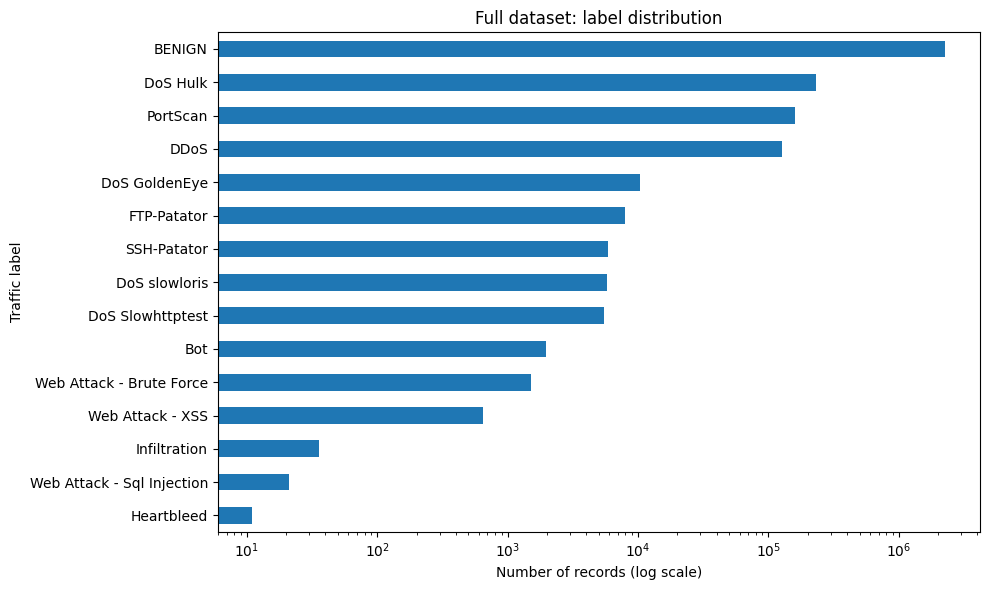

In [ ]:
# Row count: Combined shows about 2.83M
# Column count: 78 Features + Label + session
counts = df["Label"].value_counts()
pct = (counts / len(df) * 100).round(3)
print(pd.DataFrame({"count": counts, "pct": pct}))

plt.figure(figsize=(10, 6))
counts.sort_values().plot.barh(logx=True)
plt.xlabel("Number of records (log scale)")
plt.ylabel("Traffic label")
plt.title("Full dataset: label distribution")
plt.tight_layout(); plt.show()

In [ ]:
# Data Quality
# Types and memory
df.info(memory_usage="deep")

# Inf/NaN: Finding in which columns they are in
inf_counts = np.isinf(df[num_cols]).sum()
print("Inf values per column:\n",inf_counts[inf_counts>0],"\n")

df[num_cols] = df[num_cols].replace([np.inf,-np.inf],np.nan)
na =  df[num_cols].isna().sum()
print("NaN values per column (after converting inf):\n",na[na>0],"\n")

# Duplicate rows (ignoring the session column)
n_dup = df.drop(columns="session").duplicated().sum()
print(f"Duplicate rows: {n_dup:,},({n_dup/len(df):.2%})\n")

# Constant columns
nu = df[num_cols].nunique()
print("Constant columns:",nu[nu<=1].index.tolist(),"\n")

# Negative values
neg = (df[num_cols]<0).sum()
print("Columns with negative values:\n",neg[neg>0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 80 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             float32
 1   Flow Duration                float32
 2   Total Fwd Packets            float32
 3   Total Backward Packets       float32
 4   Total Length of Fwd Packets  float32
 5   Total Length of Bwd Packets  float32
 6   Fwd Packet Length Max        float32
 7   Fwd Packet Length Min        float32
 8   Fwd Packet Length Mean       float32
 9   Fwd Packet Length Std        float32
 10  Bwd Packet Length Max        float32
 11  Bwd Packet Length Min        float32
 12  Bwd Packet Length Mean       float32
 13  Bwd Packet Length Std        float32
 14  Flow Bytes/s                 float32
 15  Flow Packets/s               float32
 16  Flow IAT Mean                float32
 17  Flow IAT Std                 float32
 18  Flow IAT Max                 float32
 19  

In [ ]:
# Checking for duplicate column as the original files contain
# Fwd Header Length twice and pandas renames the second on to Fwd Header Length.1


print([c for c in df.columns if c.endswith(".1")])
print(df["Fwd Header Length"].equals(df["Fwd Header Length.1"]) if "Fwd Header Length.1" in df else "no duplicate column")

['Fwd Header Length.1']
True


In [ ]:
const_cols = nu[nu<=1].index.tolist()
df = df.drop(columns=const_cols + ["Fwd Header Length.1"])
num_cols = df.select_dtypes("number").columns

print("Shape:", df.shape)
print("NaN total:", df[num_cols].isna().sum().sum())
print("Inf total:", np.isinf(df[num_cols]).sum().sum())
print("Duplicates:", df.drop(columns="session").duplicated().sum())
print("Constant columns:", [c for c in num_cols if df[c].nunique() <= 1])

neg = (df[num_cols] < 0).sum()
print("Remaining negatives:\n", neg[neg > 0])

Shape: (2830743, 71)
NaN total: 5734
Inf total: 0
Duplicates: 331200
Constant columns: []
Remaining negatives:
 Flow Duration                  115
Flow Bytes/s                    85
Flow Packets/s                 115
Flow IAT Mean                  115
Flow IAT Max                   115
Flow IAT Min                  2891
Fwd IAT Min                     17
Fwd Header Length               35
Bwd Header Length               22
Init_Win_bytes_forward     1001189
Init_Win_bytes_backward    1441552
min_seg_size_forward            35
dtype: int64


In [ ]:
num_cols = df.select_dtypes("number").columns
print("Shape:", df.shape)
print("NaN total:", df[num_cols].isna().sum().sum())
print("Inf total:", np.isinf(df[num_cols]).sum().sum())
print("Duplicates:", df.drop(columns="session").duplicated().sum())
neg = (df[num_cols] < 0).sum()
print("Remaining negatives:\n", neg[neg > 0])

Shape: (2830743, 71)
NaN total: 5734
Inf total: 0
Duplicates: 331200
Remaining negatives:
 Flow Duration                  115
Flow Bytes/s                    85
Flow Packets/s                 115
Flow IAT Mean                  115
Flow IAT Max                   115
Flow IAT Min                  2891
Fwd IAT Min                     17
Fwd Header Length               35
Bwd Header Length               22
Init_Win_bytes_forward     1001189
Init_Win_bytes_backward    1441552
min_seg_size_forward            35
dtype: int64


In [ ]:
print(len(df),df.shape)

2830743 (2830743, 71)


In [ ]:
n0 = len(df)
print("Start:", n0, df.shape)

num_cols = df.select_dtypes("number").columns
nu = df[num_cols].nunique()
const_cols = nu[nu <= 1].index.tolist()
df = df.drop(columns=const_cols + ["Fwd Header Length.1"], errors="ignore")
num_cols = df.select_dtypes("number").columns
print("After column drop:", df.shape)

neg_cols = ["Flow Duration", "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean", "Flow IAT Max",
            "Flow IAT Min", "Fwd IAT Min", "Fwd Header Length", "Bwd Header Length",
            "min_seg_size_forward"]
nan_mask = df[["Flow Bytes/s", "Flow Packets/s"]].isna().any(axis=1)
neg_mask = (df[neg_cols] < 0).any(axis=1)
print("NaN rows:", nan_mask.sum(), "| negative rows:", neg_mask.sum(), "| union:", (nan_mask | neg_mask).sum())
df = df[~(nan_mask | neg_mask)]
print("After bad-row drop:", df.shape)

feature_cols = [c for c in df.columns if c != "session"]
df = df.drop_duplicates(subset=feature_cols).reset_index(drop=True)
print("After duplicate drop:", df.shape)

print(f"Rows: {n0:,} -> {len(df):,}  ({n0 - len(df):,} removed)")
print(df["Label"].value_counts())

Start: 2830743 (2830743, 71)
After column drop: (2830743, 71)
NaN rows: 2867 | negative rows: 2926 | union: 5792
After bad-row drop: (2824951, 71)
After duplicate drop: (2495065, 71)
Rows: 2,830,743 -> 2,495,065  (335,678 removed)
Label
BENIGN                        2069532
DoS Hulk                       172688
DDoS                           127995
PortScan                        90694
DoS GoldenEye                   10277
FTP-Patator                      5927
DoS slowloris                    5374
DoS Slowhttptest                 5228
SSH-Patator                      3217
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       35
Web Attack - Sql Injection         21
Heartbleed                          7
Name: count, dtype: int64


In [ ]:
num_cols = df.select_dtypes("number").columns
print("Shape:", df.shape)
print("NaN total:", df[num_cols].isna().sum().sum())
print("Inf total:", np.isinf(df[num_cols]).sum().sum())
print("Duplicates:", df.drop(columns="session").duplicated().sum())
neg = (df[num_cols] < 0).sum()
print("Remaining negatives:\n", neg[neg > 0])

Shape: (2495065, 71)
NaN total: 0
Inf total: 0
Duplicates: 0
Remaining negatives:
 Init_Win_bytes_forward      892898
Init_Win_bytes_backward    1194059
dtype: int64


In [ ]:
# [REV2-ADDED] Dataset-integrity checks on the cleaned data
integrity = []
def integrity_check(name, ok, detail="", hard=True):
    integrity.append({"check": name, "passed": bool(ok), "detail": detail, "hard": hard})
    if hard:
        assert ok, f"Integrity check failed: {name} {detail}"

num_c = df.select_dtypes("number").columns
integrity_check("8 capture sessions present", df["session"].nunique() == 8, str(df["session"].nunique()))
integrity_check("15 original labels present", df["Label"].nunique() == 15, str(df["Label"].nunique()))
integrity_check("no missing label", df["Label"].notna().all())
integrity_check("no NaN in numeric columns", int(df[num_c].isna().sum().sum()) == 0)
integrity_check("no +/-inf in numeric columns", int(np.isinf(df[num_c]).sum().sum()) == 0)
integrity_check("no exact duplicate rows (session column ignored)", int(df.drop(columns="session").duplicated().sum()) == 0)
integrity_check("no negative values in columns that cannot be negative",
                int((df[[c for c in ["Flow Duration", "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean", "Flow IAT Max", "Flow IAT Min",
                                      "Fwd IAT Min", "Fwd Header Length", "Bwd Header Length", "min_seg_size_forward"] if c in df.columns]] < 0).sum().sum()) == 0)
integrity_check("row index is unique and 0..n-1", df.index.is_unique and df.index.equals(pd.RangeIndex(len(df))))
integrity_check("every class has at least 2 rows (needed for a stratified split)", bool((df["Label"].value_counts() >= 2).all()),
                str(df["Label"].value_counts().min()))
print(pd.DataFrame(integrity)[["check", "passed", "detail"]].to_string(index=False))
print("\nRows:", f"{len(df):,}", "| smallest class:", df["Label"].value_counts().idxmin(), int(df["Label"].value_counts().min()))

                                                          check  passed detail
                                     8 capture sessions present    True      8
                                     15 original labels present    True     15
                                               no missing label    True       
                                      no NaN in numeric columns    True       
                                   no +/-inf in numeric columns    True       
               no exact duplicate rows (session column ignored)    True       
          no negative values in columns that cannot be negative    True       
                                 row index is unique and 0..n-1    True       
every class has at least 2 rows (needed for a stratified split)    True      7

Rows: 2,495,065 | smallest class: Heartbleed 7


In [ ]:
import pyarrow as pa
df.to_parquet("cic_ids2017_clean.parquet", index=False)
#Clean data

In [ ]:
after = df["Label"].value_counts()
pct = (after/len(df) *100).round(3)

print(pd.DataFrame({"count":after, "pct":pct}))
print("Imbalance Ratio:",after.max()/after.min())

                              count     pct
Label                                      
BENIGN                      2069532  82.945
DoS Hulk                     172688   6.921
DDoS                         127995   5.130
PortScan                      90694   3.635
DoS GoldenEye                 10277   0.412
FTP-Patator                    5927   0.238
DoS slowloris                  5374   0.215
DoS Slowhttptest               5228   0.210
SSH-Patator                    3217   0.129
Bot                            1948   0.078
Web Attack - Brute Force       1470   0.059
Web Attack - XSS                652   0.026
Infiltration                     35   0.001
Web Attack - Sql Injection       21   0.001
Heartbleed                        7   0.000
Imbalance Ratio: 295647.4285714286


In [ ]:
# Benign is 82.9% which is up from 80.3% because of the removal of deplicates and bad rows
# Three classes are too small to model on their own:
# imbalance Ratio: Benign vs the combined attacks about 4.9 to 1
# Loss incurred by Cleaning
loss = pd.DataFrame({"before": counts, "after": after}).fillna(0).astype(int)
loss["removed"] = loss["before"] - loss["after"]
loss["removed_%"] = (loss["removed"] / loss["before"] * 100).round(1)
print(loss.sort_values("removed_%", ascending=False))

                             before    after  removed  removed_%
Label                                                           
SSH-Patator                    5897     3217     2680       45.4
PortScan                     158930    90694    68236       42.9
Heartbleed                       11        7        4       36.4
FTP-Patator                    7938     5927     2011       25.3
DoS Hulk                     231073   172688    58385       25.3
BENIGN                      2273097  2069532   203565        9.0
DoS slowloris                  5796     5374      422        7.3
DoS Slowhttptest               5499     5228      271        4.9
Infiltration                     36       35        1        2.8
Web Attack - Brute Force       1507     1470       37        2.5
Bot                            1966     1948       18        0.9
DoS GoldenEye                 10293    10277       16        0.2
DDoS                         128027   127995       32        0.0
Web Attack - Sql Injectio

In [ ]:
# Univariate Analysis (Distributions)
num_cols = df.select_dtypes("number").columns

desc = df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
desc["cv"] = desc["std"] / desc["mean"].abs()

display(desc.sort_values("skew", ascending=False).head(15))
print("Features with |skew| > 1:", (desc["skew"].abs() > 1).sum(), "of", len(desc))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis,cv
Subflow Bwd Bytes,2495065.0,6047.994629,266746.187500,0.0,0.0,6.0,156.0,1086.0,77766.8,399368704.0,1350.062378,2.012878e+06,44.104898
Total Length of Bwd Packets,2495065.0,6047.895508,266527.968750,0.0,0.0,6.0,156.0,1086.0,77766.8,399000000.0,1349.653442,2.012032e+06,44.069539
act_data_pkt_fwd,2495065.0,3.168763,72.324768,0.0,0.0,0.0,1.0,3.0,28.0,108273.0,1347.985962,2.009183e+06,22.824293
Subflow Bwd Packets,2495065.0,6.176064,109.475189,0.0,0.0,1.0,2.0,5.0,60.0,157388.0,1199.960205,1.709315e+06,17.725720
Total Backward Packets,2495065.0,6.176064,109.475189,0.0,0.0,1.0,2.0,5.0,60.0,157388.0,1199.960205,1.709315e+06,17.725720
Subflow Fwd Packets,2495065.0,6.247790,79.030426,1.0,1.0,2.0,2.0,6.0,50.0,112141.0,1157.982910,1.620998e+06,12.649340
Total Fwd Packets,2495065.0,6.247790,79.030426,1.0,1.0,2.0,2.0,6.0,50.0,112141.0,1157.982910,1.620998e+06,12.649340
Bwd Header Length,2495065.0,163.483109,2250.614502,0.0,0.0,20.0,40.0,132.0,1608.0,3147772.0,1105.686890,1.528884e+06,13.766649
Fwd Header Length,2495065.0,164.501923,1708.458862,0.0,20.0,40.0,64.0,144.0,1352.0,2289684.0,989.785767,1.292074e+06,10.385647
Total Length of Fwd Packets,2495065.0,592.029480,9691.378906,0.0,0.0,12.0,66.0,335.0,11601.0,12900000.0,974.823181,1.259086e+06,16.369757


Features with |skew| > 1: 66 of 69


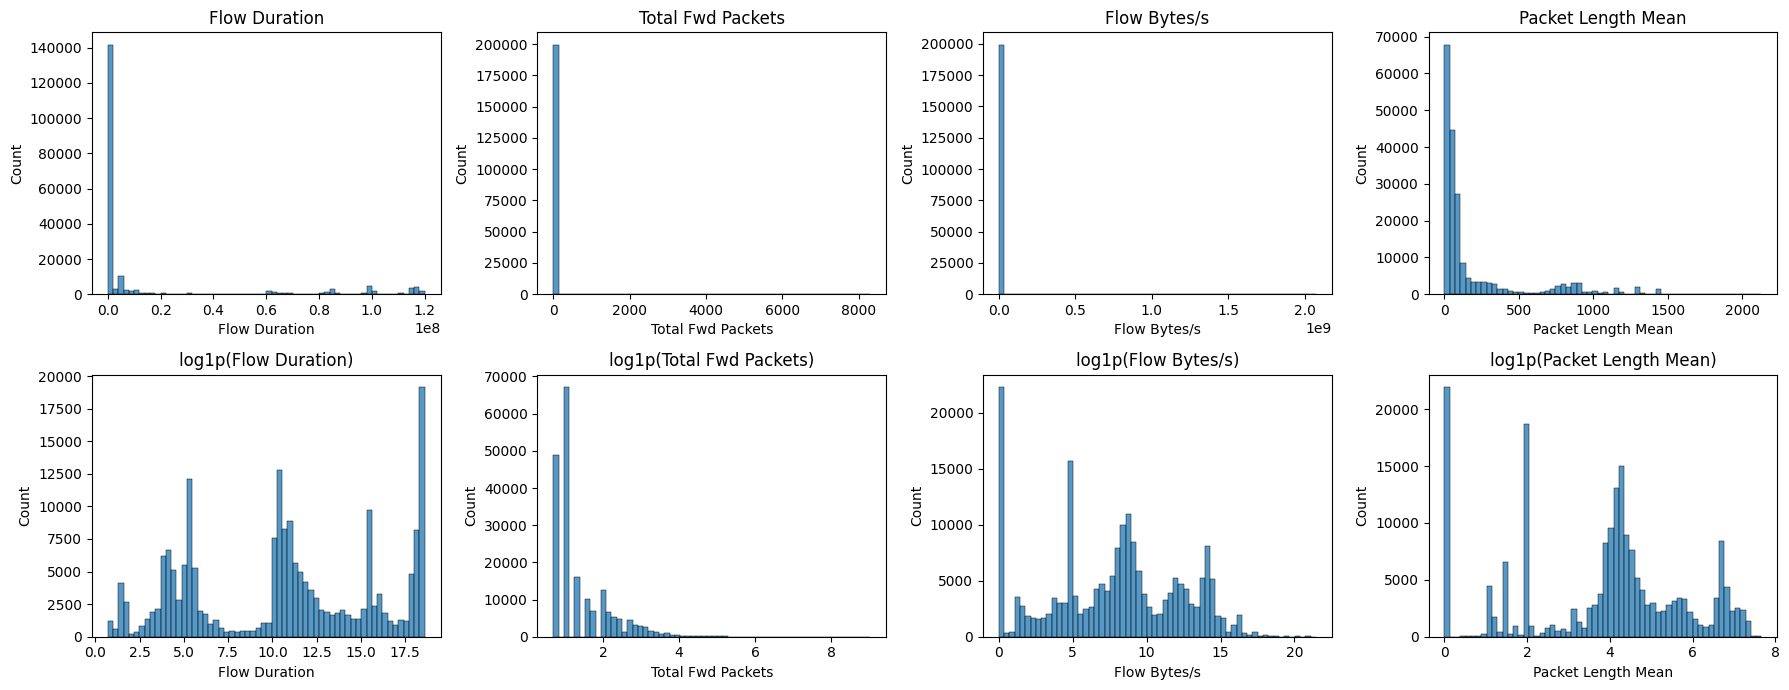

In [ ]:
key = ["Flow Duration", "Total Fwd Packets", "Flow Bytes/s", "Packet Length Mean"]
fig, ax = plt.subplots(2, len(key), figsize=(18, 7))
for i, c in enumerate(key):
    s = df[c].sample(200_000, random_state=1)
    sns.histplot(s, bins=60, ax=ax[0, i]).set_title(c)
    sns.histplot(np.log1p(s.clip(lower=0)), bins=60, ax=ax[1, i]).set_title(f"log1p({c})")
plt.tight_layout(); plt.show()

In [ ]:
# Outlier Detection
num_cols = df.select_dtypes("number").columns
cont_cols = [c for c in num_cols if df[c].nunique() > 2]

q = df[cont_cols].quantile([.25, .75])
iqr = q.loc[.75] - q.loc[.25]
lo, hi = q.loc[.25] - 1.5 * iqr, q.loc[.75] + 1.5 * iqr

zero_iqr = iqr[iqr == 0].index.tolist()
usable = iqr[iqr > 0].index.tolist()
print("Skipped (IQR = 0):", zero_iqr)

out = (df[usable] < lo[usable]) | (df[usable] > hi[usable])
rate = out.mean().sort_values(ascending=False)
print((rate * 100).round(1).head(15))
print("Median outlier rate across features: {:.1f}%".format(rate.median() * 100))

Skipped (IQR = 0): ['Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']
Bwd Packets/s                  23.4
Fwd IAT Std                    23.4
Total Length of Bwd Packets    22.8
Subflow Bwd Bytes              22.8
Destination Port               21.9
Bwd IAT Total                  21.0
Bwd IAT Mean                   20.7
Fwd IAT Min                    20.5
Bwd IAT Max                    20.3
Fwd IAT Mean                   20.2
Flow IAT Mean                  20.0
Bwd IAT Std                    19.7
Packet Length Variance         19.1
Flow IAT Min                   19.1
Flow Bytes/s                   19.0
dtype: float64
Median outlier rate across features: 13.0%


In [ ]:
# Repeating the same for log-scale
slog = lambda s: np.sign(s) * np.log1p(s.abs())
rate_log = {}
for c in usable:
    t = slog(df[c])
    a, b = t.quantile([.25, .75]); r = b - a
    rate_log[c] = ((t < a - 1.5*r) | (t > b + 1.5*r)).mean() if r > 0 else np.nan
cmp = pd.DataFrame({"raw": rate, "log": pd.Series(rate_log)}).sort_values("raw", ascending=False)
print((cmp * 100).round(1).head(15))

                              raw   log
Bwd Packets/s                23.4   0.0
Fwd IAT Std                  23.4   0.0
Subflow Bwd Bytes            22.8   0.0
Total Length of Bwd Packets  22.8   0.0
Destination Port             21.9  16.9
Bwd IAT Total                21.0   0.0
Bwd IAT Mean                 20.7   0.0
Fwd IAT Min                  20.5   7.6
Bwd IAT Max                  20.3   0.0
Fwd IAT Mean                 20.2   0.0
Flow IAT Mean                20.0   0.0
Bwd IAT Std                  19.7   0.0
Packet Length Variance       19.1   0.0
Flow IAT Min                 19.1  15.1
Flow Bytes/s                 19.0   0.0


In [ ]:
# 4 groups
# 1.IQR=0 for Active* and Idle*
# 2.Destination Port
# 3.Flow IAT Min and Fwd IAT Min

# 1.
ai = ["Active Mean", "Active Std", "Active Max", "Active Min",
      "Idle Mean", "Idle Std", "Idle Max", "Idle Min"]
lab = df["Label_grouped"] if "Label_grouped" in df else df["Label"]

print("Share of rows that are 0:\n", (df[ai] == 0).mean().round(3), "\n")
print("Share non-zero, by class:")
display((df[ai] > 0).groupby(lab).mean().round(3))

#2.
port = df["Destination Port"].astype(int)
port_group = pd.cut(port, [-1, 1023, 49151, 65535],
                    labels=["well-known", "registered", "dynamic"])
display(pd.crosstab(port_group, lab, normalize="columns").round(3))

for l in ["BENIGN", "DoS Hulk", "DDoS", "PortScan", "SSH-Patator", "FTP-Patator"]:
    print(l, port[lab == l].value_counts().head(5).to_dict())

# 3.
for c in ["Flow IAT Min", "Fwd IAT Min"]:
    print(f"\n{c}: below lower fence {(df[c] < lo[c]).mean():.1%} | above upper fence {(df[c] > hi[c]).mean():.1%}")
display(out[["Flow IAT Min", "Fwd IAT Min"]].groupby(lab).mean().round(3))

Share of rows that are 0:
 Active Mean    0.777
Active Std     0.918
Active Max     0.777
Active Min     0.777
Idle Mean      0.773
Idle Std       0.909
Idle Max       0.773
Idle Min       0.773
dtype: float64 

Share non-zero, by class:


,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
Label,,,,,,,,
BENIGN,0.172,0.098,0.172,0.172,0.173,0.100,0.173,0.173
Bot,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
DDoS,0.398,0.000,0.398,0.398,0.399,0.094,0.399,0.399
DoS GoldenEye,0.557,0.006,0.557,0.557,0.818,0.008,0.818,0.818
DoS Hulk,0.794,0.000,0.794,0.794,0.820,0.019,0.820,0.820
DoS Slowhttptest,0.766,0.045,0.766,0.766,0.768,0.578,0.768,0.768
DoS slowloris,0.573,0.333,0.573,0.573,0.573,0.340,0.573,0.573
FTP-Patator,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Heartbleed,0.143,0.000,0.143,0.143,0.143,0.000,0.143,0.143


Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
Destination Port,,,,,,,,,,,,,,,
well-known,0.774,0.000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.164,1.0,1.0,1.0,1.0
registered,0.083,0.766,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.782,0.0,0.0,0.0,0.0
dynamic,0.144,0.234,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.054,0.0,0.0,0.0,0.0


BENIGN {53: 859542, 443: 466007, 80: 215685, 123: 20590, 22: 6606}
DoS Hulk {80: 172688}
DDoS {80: 127992, 64869: 1, 64873: 1, 27636: 1}
PortScan {80: 372, 21: 243, 22: 243, 139: 196, 445: 179}
SSH-Patator {22: 3217}
FTP-Patator {21: 5926, 80: 1}

Flow IAT Min: below lower fence 0.0% | above upper fence 19.1%

Fwd IAT Min: below lower fence 0.0% | above upper fence 20.5%


,Flow IAT Min,Fwd IAT Min
Label,,
BENIGN,0.219,0.200
Bot,0.253,0.270
DDoS,0.098,0.310
DoS GoldenEye,0.250,0.593
DoS Hulk,0.017,0.189
DoS Slowhttptest,0.605,0.894
DoS slowloris,0.306,0.884
FTP-Patator,0.002,0.558
Heartbleed,0.000,0.000


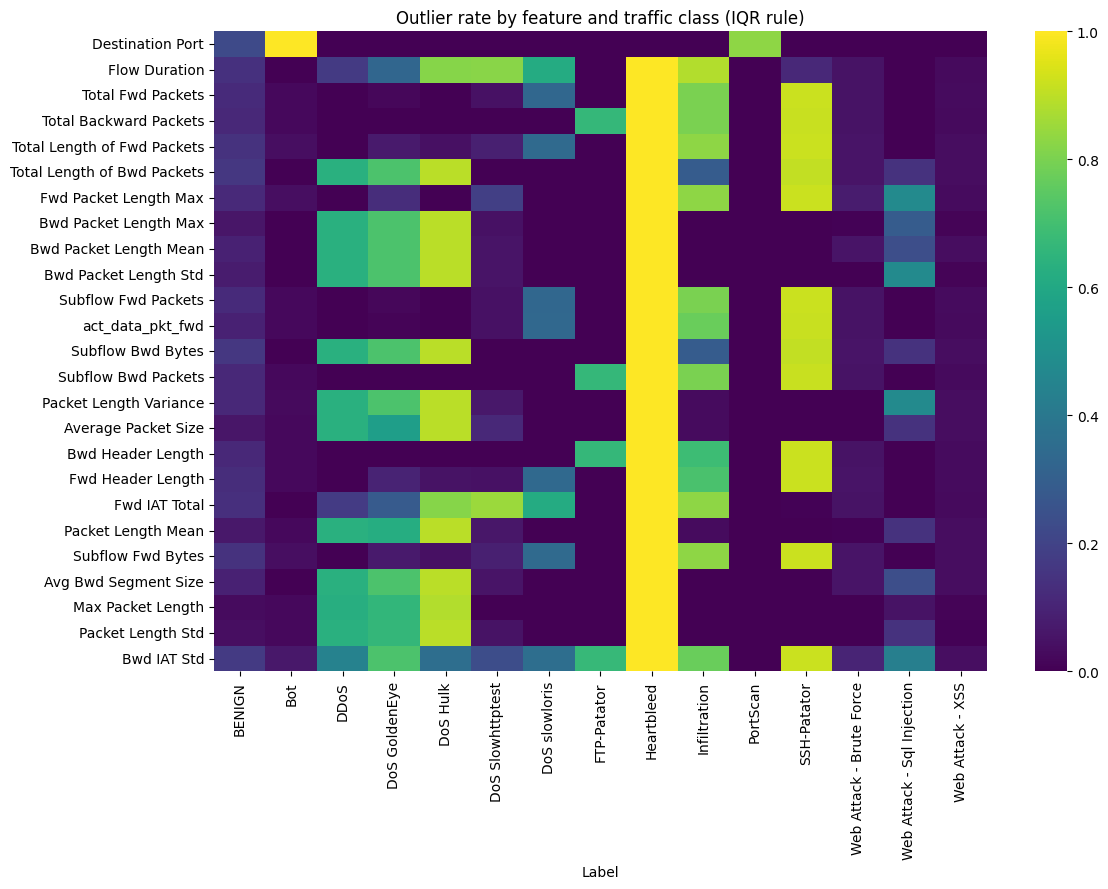

In [ ]:
# Do the outliers concentrate in particular classes?

lab = df["Label_grouped"] if "Label_grouped" in df else df["Label"]
y = (df["Label"] != "BENIGN")

rate_by_class = out.groupby(lab).mean().T

# Show the 25 features whose outlier rate differs most across classes
# Creating a Heatmap for Visual
spread = (rate_by_class.max(axis=1) - rate_by_class.min(axis=1)).sort_values(ascending=False)
plt.figure(figsize=(12, 9))
sns.heatmap(rate_by_class.loc[spread.index[:25]], cmap="viridis", annot=False)
plt.title("Outlier rate by feature and traffic class (IQR rule)")
plt.tight_layout(); plt.show()

In [ ]:
# Informative outliers

base = y.mean()
tbl = pd.DataFrame({
    "outlier_rate_%": (out.mean() * 100).round(1),
    "attack_share_among_outliers_%": out.apply(lambda s: y[s].mean() * 100).round(1),
    "rate_in_attacks_%": (out[y].mean() * 100).round(1),
    "rate_in_benign_%": (out[~y].mean() * 100).round(1),
})
tbl["lift"] = (tbl["rate_in_attacks_%"] / tbl["rate_in_benign_%"]).round(2)
print(f"Baseline attack share: {base:.1%}")
display(tbl.sort_values("lift", ascending=False).head(15))
display(tbl.sort_values("lift").head(10))

Baseline attack share: 17.1%


,outlier_rate_%,attack_share_among_outliers_%,rate_in_attacks_%,rate_in_benign_%,lift
Max Packet Length,12.2,79.0,56.5,3.1,18.23
Packet Length Std,13.0,75.2,57.2,3.9,14.67
Bwd Packet Length Max,14.6,67.1,57.3,5.8,9.88
Average Packet Size,14.5,67.0,57.0,5.8,9.83
Packet Length Mean,15.1,64.7,57.1,6.4,8.92
Bwd Packet Length Std,16.0,61.2,57.3,7.5,7.64
Fwd IAT Max,11.9,59.8,41.7,5.8,7.19
Flow IAT Max,11.8,59.1,41.0,5.8,7.07
Bwd Packet Length Mean,17.3,56.6,57.3,9.0,6.37
Avg Bwd Segment Size,17.3,56.6,57.3,9.0,6.37


,outlier_rate_%,attack_share_among_outliers_%,rate_in_attacks_%,rate_in_benign_%,lift
Bwd Packet Length Min,2.6,0.1,0.0,3.2,0.00
min_seg_size_forward,0.1,0.3,0.0,0.1,0.00
Init_Win_bytes_backward,11.4,1.3,0.9,13.5,0.07
Total Fwd Packets,10.1,2.2,1.3,11.9,0.11
Subflow Fwd Packets,10.1,2.2,1.3,11.9,0.11
Fwd Packet Length Max,9.6,2.3,1.3,11.3,0.12
act_data_pkt_fwd,7.7,2.8,1.3,9.0,0.14
Total Backward Packets,9.5,3.0,1.7,11.1,0.15
Bwd Header Length,9.6,3.0,1.7,11.3,0.15
Subflow Bwd Packets,9.5,3.0,1.7,11.1,0.15


In [ ]:
# Where are the most extreme values from

for c in ["Subflow Bwd Bytes", "Flow Bytes/s", "Flow Duration", "Total Fwd Packets", "Fwd Header Length"]:
    top = df.nlargest(500, c)
    print(f"\n{c}: top 500 rows by label")
    print(top["Label"].value_counts().head(5).to_dict())
    print(f"  max / 99th percentile = {df[c].max() / df[c].quantile(.99):,.0f}")


Subflow Bwd Bytes: top 500 rows by label
{'BENIGN': 494, 'Heartbleed': 6}
  max / 99th percentile = 5,135

Flow Bytes/s: top 500 rows by label
{'BENIGN': 499, 'DoS Slowhttptest': 1}
  max / 99th percentile = 168

Flow Duration: top 500 rows by label
{'BENIGN': 498, 'Infiltration': 2}
  max / 99th percentile = 1

Total Fwd Packets: top 500 rows by label
{'BENIGN': 485, 'Infiltration': 9, 'Heartbleed': 6}
  max / 99th percentile = 2,243

Fwd Header Length: top 500 rows by label
{'BENIGN': 485, 'Infiltration': 9, 'Heartbleed': 6}
  max / 99th percentile = 1,694


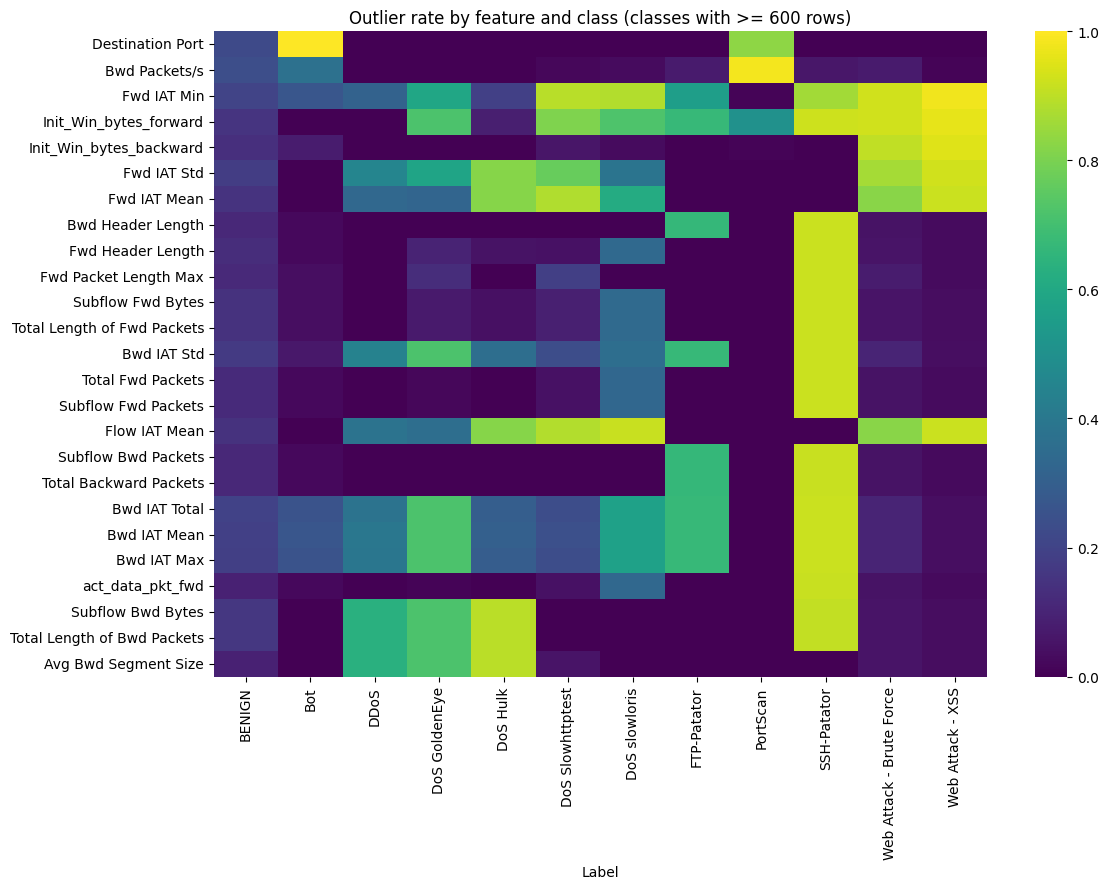

In [ ]:
rare = ["Heartbleed", "Infiltration", "Web Attack - Sql Injection"]
keep = ~lab.isin(rare)
rbc = out[keep].groupby(lab[keep]).mean().T
spread = (rbc.max(axis=1) - rbc.min(axis=1)).sort_values(ascending=False)

plt.figure(figsize=(12, 9))
sns.heatmap(rbc.loc[spread.index[:25]], cmap="viridis", vmin=0, vmax=1)
plt.title("Outlier rate by feature and class (classes with >= 600 rows)")
plt.tight_layout(); plt.show()

## [REV2-ADDED] Train/test split made once, before any supervised feature analysis

Everything above this point is descriptive EDA on the full cleaned data (distributions, outlier rates, class balance, PCA, box plots); none of it is used to choose features or models.
The cleaning steps (constant columns, invalid rows, exact duplicates) are label-free or row-wise rules.

From here on, all **supervised** feature analysis (variance and near-constant checks, effect size, mutual information, Random-Forest importance, correlation analysis, Spearman, VIF) uses the **training rows only**.
The split is stratified on the original 15-class `Label`, so every class, including the very small ones, appears in both parts. The test rows are used only for the final evaluation.

In [ ]:
# [REV2-ADDED] The one and only train/test split (the same rows are used by feature selection AND by every model)
assert df.index.is_unique
train_idx, test_idx = train_test_split(
    df.index.to_numpy(), test_size=0.20, random_state=SEED, stratify=df["Label"])
assert len(np.intersect1d(train_idx, test_idx)) == 0 and len(train_idx) + len(test_idx) == len(df)
df_fs = df.loc[train_idx]          # training rows only: used by the feature-analysis cells below
print("Training rows:", f"{len(train_idx):,}", "| test rows (untouched until final evaluation):", f"{len(test_idx):,}")
print("Min class count in train / test:", int(df_fs["Label"].value_counts().min()), "/", int(df.loc[test_idx, "Label"].value_counts().min()))

Training rows: 1,996,052 | test rows (untouched until final evaluation): 499,013
Min class count in train / test: 6 / 1


In [ ]:
# [REV2-CHANGED] uses the training rows only (df_fs)
# Features
from scipy.stats import mannwhitneyu
from sklearn.feature_selection import mutual_info_classif

num_cols = df_fs.select_dtypes("number").columns
feats = [c for c in num_cols if df_fs[c].nunique() > 1 and c != "is_attack"]

# Balanced sample: equal benign and attack rows
y_all = (df_fs["Label"] != "BENIGN")
samp = pd.concat([df_fs[~y_all].sample(30_000, random_state=42),
                  df_fs[y_all].sample(30_000, random_state=42)])
ys = (samp["Label"] != "BENIGN").astype(int)

rows = []
for c in feats:
    a, b = samp.loc[ys == 1, c], samp.loc[ys == 0, c]
    U = mannwhitneyu(a, b)[0]
    auc = U / (len(a) * len(b))
    rows.append((c, auc, abs(2 * auc - 1)))
eff = pd.DataFrame(rows, columns=["feature", "auc", "effect"]).set_index("feature")
eff["mi"] = mutual_info_classif(samp[feats], ys, random_state=42)
eff = eff.sort_values("effect", ascending=False)
display(eff.head(15)); display(eff.tail(10))

,auc,effect,mi
feature,,,
Fwd IAT Std,0.742587,0.485174,0.240852
Bwd Packet Length Std,0.740353,0.480707,0.315122
Min Packet Length,0.270919,0.458161,0.193443
Fwd Packet Length Min,0.272679,0.454643,0.191535
Bwd Packet Length Min,0.290124,0.419753,0.190366
Flow IAT Std,0.704771,0.409542,0.235908
Fwd IAT Max,0.698090,0.396180,0.346452
Fwd IAT Mean,0.692563,0.385125,0.314445
Flow IAT Max,0.686169,0.372338,0.322608


,auc,effect,mi
feature,,,
Down/Up Ratio,0.469347,0.061305,0.027844
Idle Std,0.475043,0.049913,0.044976
SYN Flag Count,0.475717,0.048567,0.009358
Fwd PSH Flags,0.475717,0.048567,0.009522
Destination Port,0.523156,0.046312,0.474309
min_seg_size_forward,0.504945,0.009889,0.047846
ECE Flag Count,0.499783,0.000433,0.000000
RST Flag Count,0.499783,0.000433,0.000000
Fwd URG Flags,0.500000,0.000000,0.002246


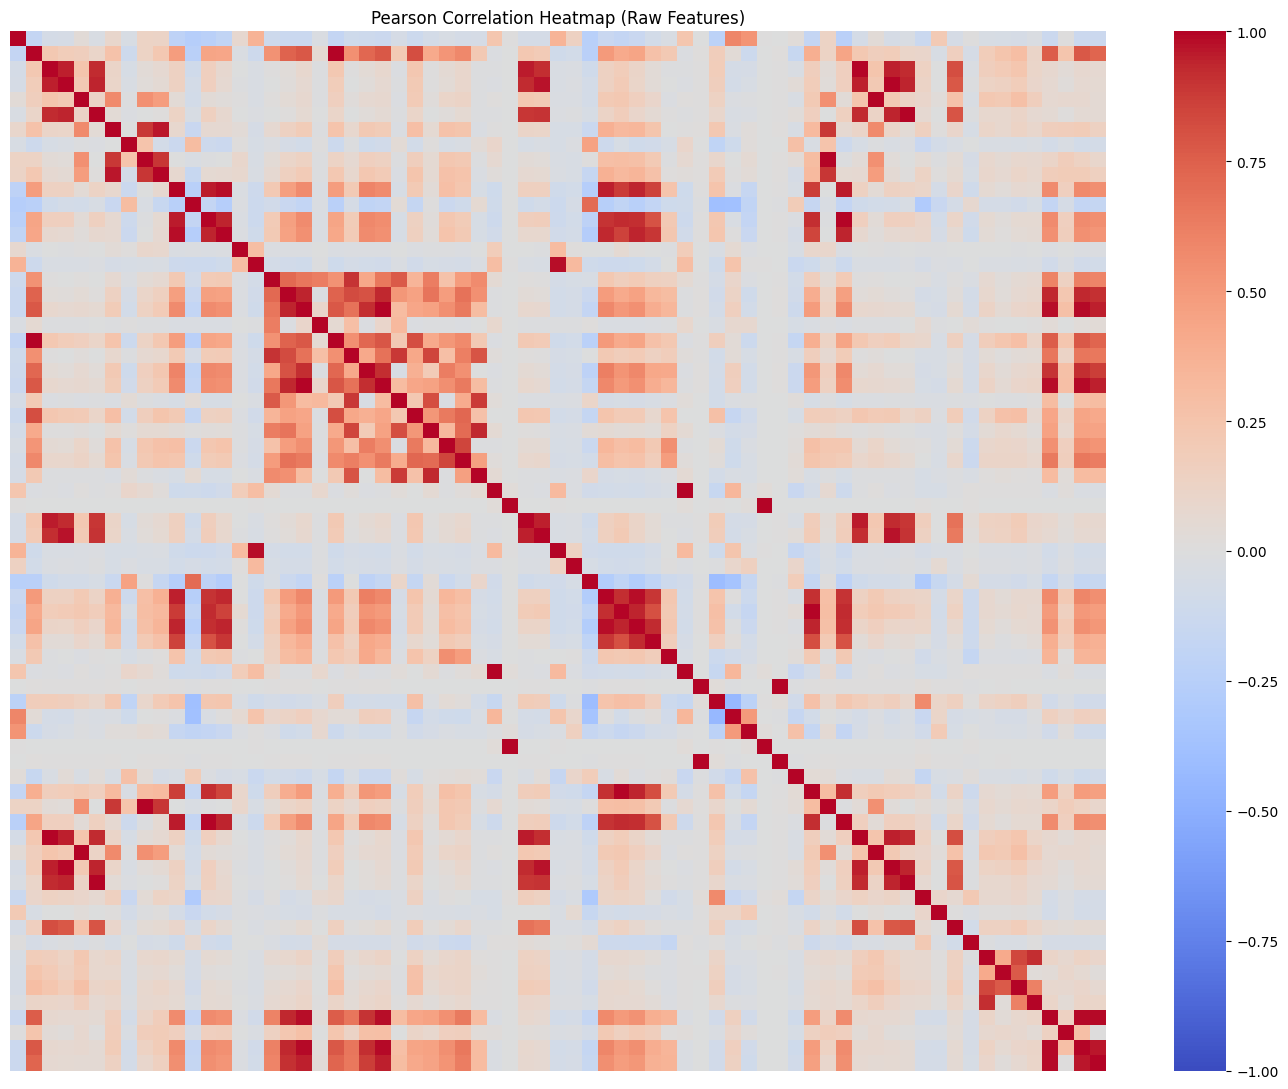

,Feature 1,Feature 2,Correlation,Absolute Correlation
252,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
185,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
789,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
2025,RST Flag Count,ECE Flag Count,1.000000,1.000000
315,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
558,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
1616,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
1658,Fwd URG Flags,CWE Flag Count,1.000000,1.000000
380,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
86,Flow Duration,Fwd IAT Total,0.998538,0.998538


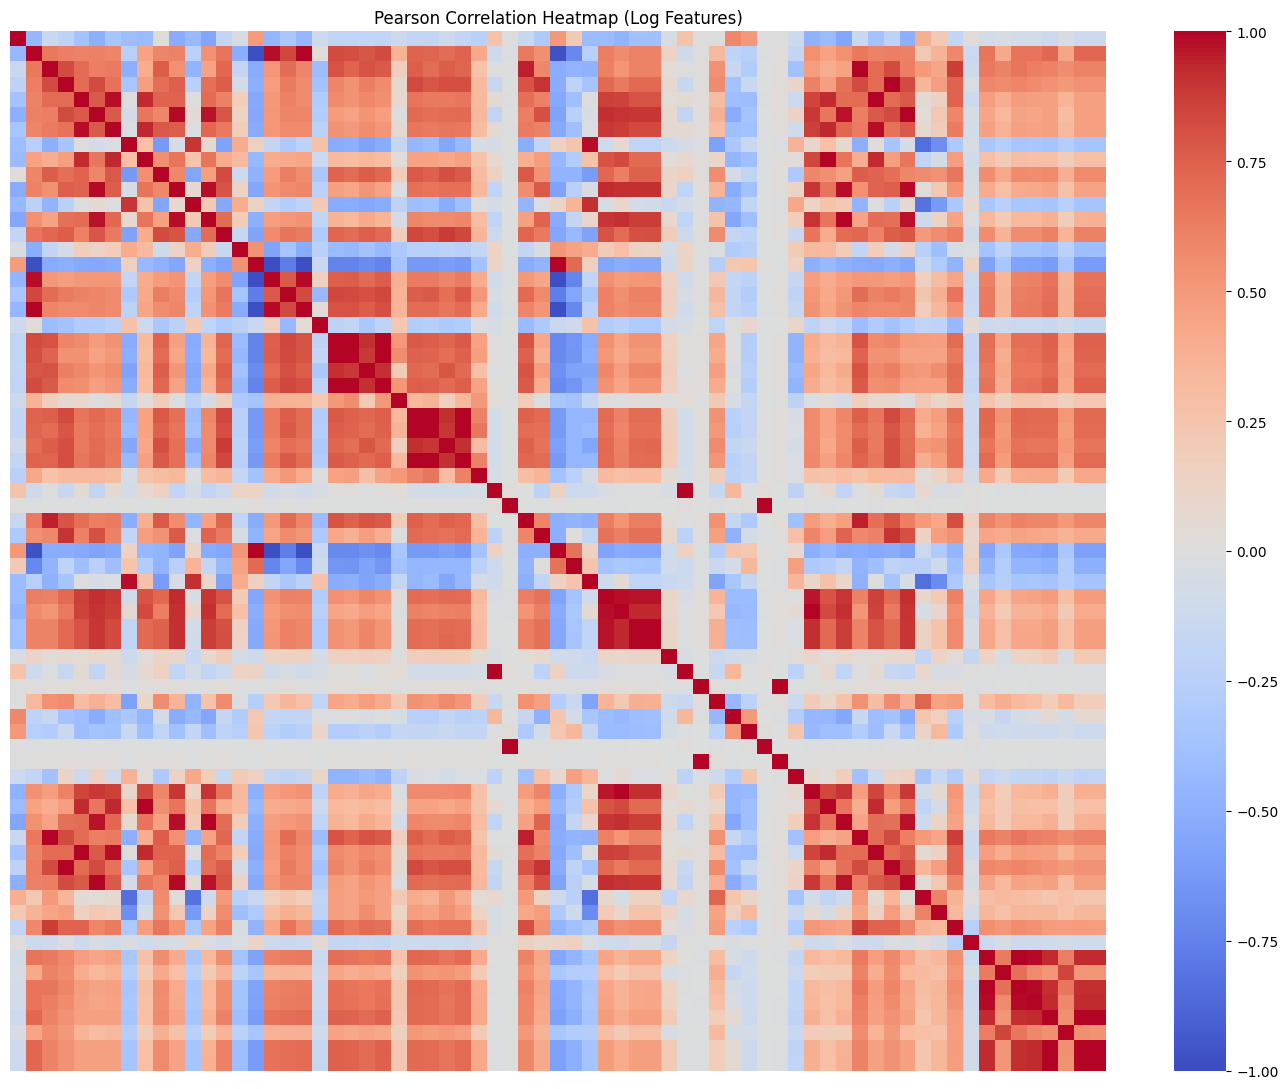

,Feature 1,Feature 2,Correlation,Absolute Correlation
252,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
315,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
185,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
558,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
1616,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
1658,Fwd URG Flags,CWE Flag Count,1.000000,1.000000
2025,RST Flag Count,ECE Flag Count,1.000000,1.000000
789,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
380,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
2341,Idle Mean,Idle Max,0.999951,0.999951


In [ ]:
# [REV2-CHANGED] uses the training rows only (df_fs)
# Correlation analysis using a sample
SEED = 42
CORR_SAMPLE = 200_000
CORR_THRESHOLD = 0.95

feats = [c for c in num_cols if df_fs[c].nunique() > 1]

samp_corr = df_fs[feats].sample(
    min(CORR_SAMPLE, len(df_fs)),
    random_state=SEED
)

slog = lambda s: np.sign(s) * np.log1p(np.abs(s))

# Raw and log-transformed correlation
for name, X in [
    ("Raw", samp_corr),
    ("Log", slog(samp_corr))
]:
    C = X.corr(method="pearson")

    plt.figure(figsize=(14, 11))
    sns.heatmap(
        C,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        xticklabels=False,
        yticklabels=False
    )
    plt.title(f"Pearson Correlation Heatmap ({name} Features)")
    plt.tight_layout()
    plt.show()

    U = C.where(np.triu(np.ones(C.shape, dtype=bool), 1))

    pairs = (
        U.stack()
        .rename("correlation")
        .reset_index()
    )

    pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

    high = pairs[
        pairs["Correlation"].abs() > CORR_THRESHOLD
    ].copy()

    high["Absolute Correlation"] = high["Correlation"].abs()

    display(
        high.sort_values(
            "Absolute Correlation",
            ascending=False
        ).head(20)
    )

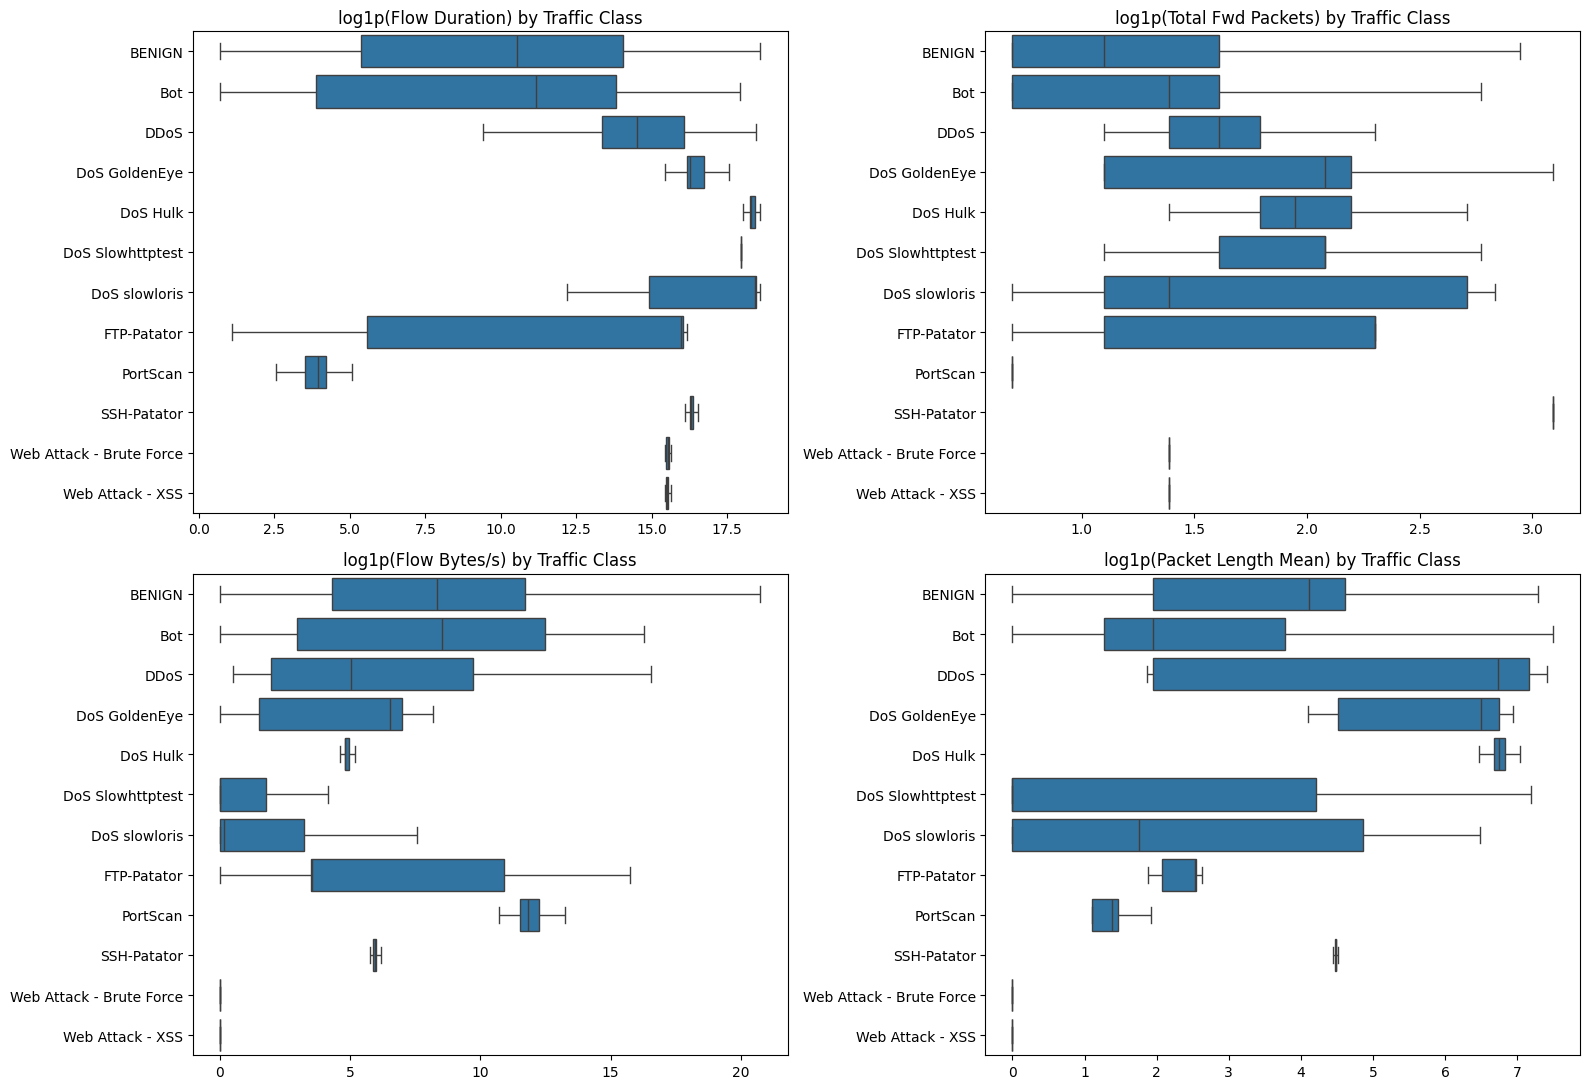

,Flow Duration,Total Fwd Packets,Flow Bytes/s,Packet Length Mean
Label,,,,
BENIGN,4.610600e+04,2.0,4145.680176,61.599998
Bot,7.103550e+04,3.0,5013.129883,6.000000
DDoS,1.879086e+06,4.0,160.100006,833.500000
DoS GoldenEye,1.158732e+07,7.0,650.669983,461.329987
DoS Hulk,8.640240e+07,6.0,123.849998,852.570007
DoS Slowhttptest,6.312044e+07,7.0,0.000000,0.000000
DoS slowloris,9.999941e+07,3.0,0.160000,4.800000
FTP-Patator,8.686554e+06,9.0,33.910000,11.600000
Heartbleed,1.192611e+08,2782.0,66172.437500,1620.050049


In [ ]:
# Feature-wise comparison across traffic classes

lab = df["Label"]

MIN_CLASS_ROWS = 600

keep_classes = lab.value_counts()[
    lab.value_counts() >= MIN_CLASS_ROWS
].index

sub = df[lab.isin(keep_classes)].copy()

sub = pd.concat([
    group.sample(min(len(group), 3000), random_state=42)
    for _, group in sub.groupby("Label")
])

key_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Flow Bytes/s",
    "Packet Length Mean"
]

key_features = [c for c in key_features if c in df.columns]

fig, ax = plt.subplots(2, 2, figsize=(16, 11))

for a, c in zip(ax.ravel(), key_features):
    sns.boxplot(
        data=sub.assign(
            transformed=np.log1p(sub[c].clip(lower=0))
        ),
        x="transformed",
        y="Label",
        showfliers=False,
        ax=a
    )

    a.set_title(f"log1p({c}) by Traffic Class")
    a.set_xlabel("")
    a.set_ylabel("")

plt.tight_layout()
plt.show()

# Class-wise median values
class_medians = df.groupby("Label")[key_features].median().round(2)

display(class_medians)

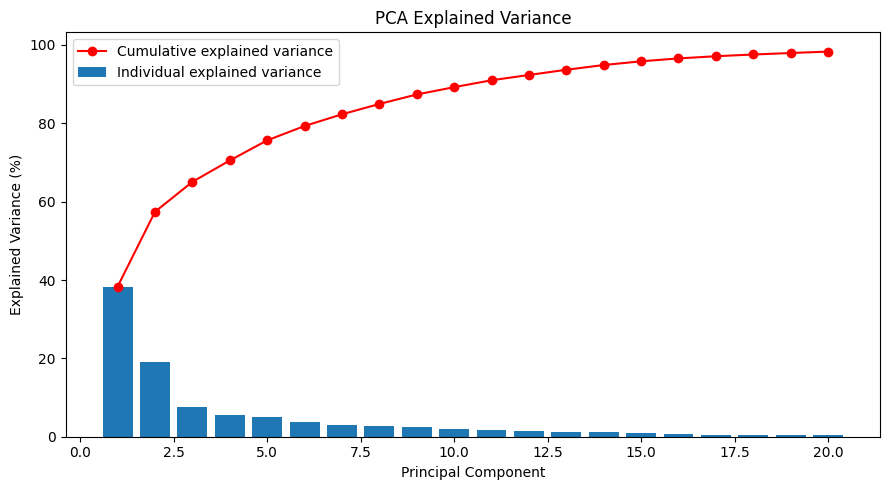

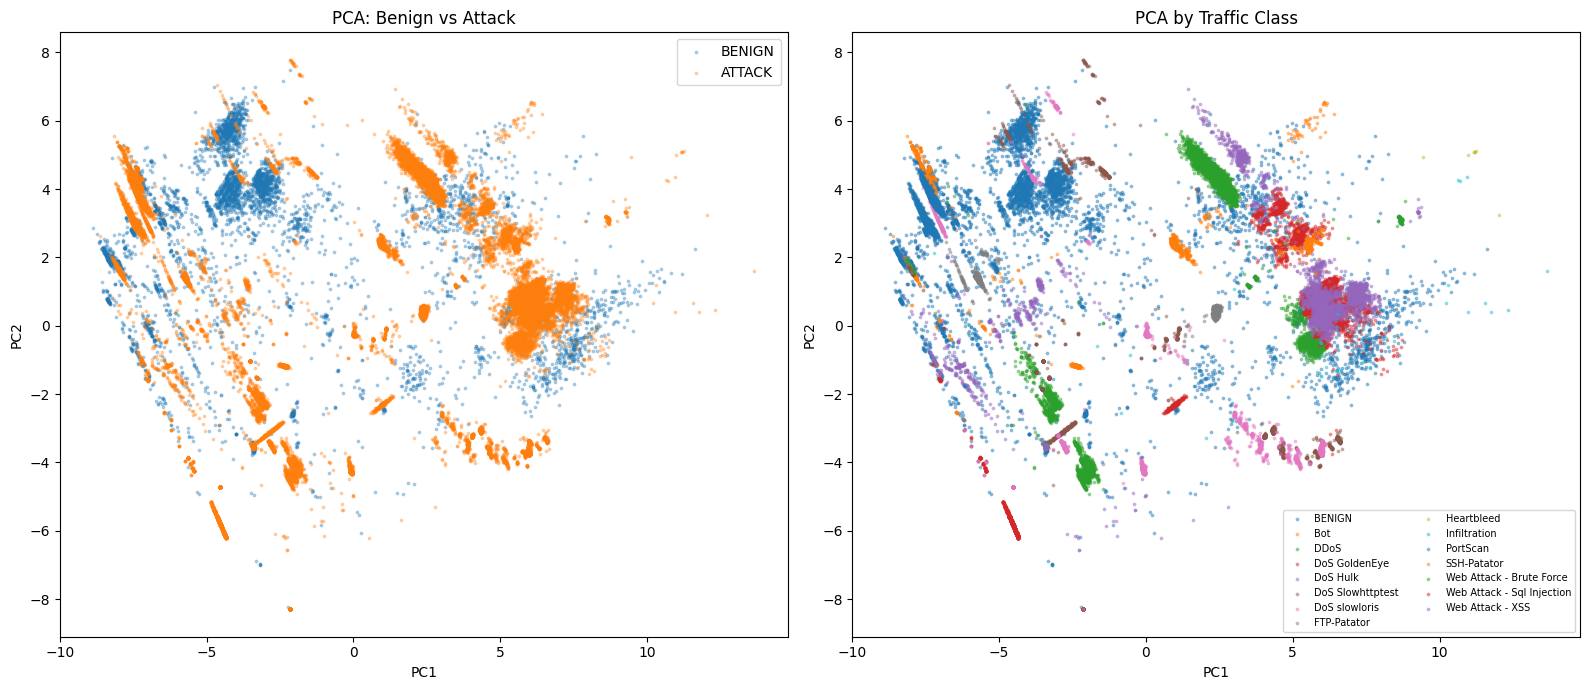

PC1 variance: 38.33 %
PC2 variance: 19.09 %
Cumulative variance (first 10 PCs): 89.22 %


In [ ]:
# Stratified sampling for PCA
PCA_PER_CLASS = 5000

samp_pca = pd.concat([
    group.sample(min(len(group), PCA_PER_CLASS), random_state=42)
    for _, group in df.groupby("Label")
])

pca_features = [
    c for c in num_cols
    if c in samp_pca.columns and samp_pca[c].nunique() > 1
]

X = slog(samp_pca[pca_features])

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA(
    n_components=min(20, len(pca_features)),
    random_state=42
)

Z = pca.fit_transform(X_scaled)

# Explained variance
ev = pca.explained_variance_ratio_
cum_ev = np.cumsum(ev)

plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(ev) + 1),
    ev * 100,
    label="Individual explained variance"
)

plt.plot(
    range(1, len(ev) + 1),
    cum_ev * 100,
    "ro-",
    label="Cumulative explained variance"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

# PCA scatter plots
yb = (samp_pca["Label"] != "BENIGN").values

fig, ax = plt.subplots(1, 2, figsize=(16, 7))

ax[0].scatter(
    Z[~yb, 0], Z[~yb, 1],
    s=3, alpha=0.3, label="BENIGN"
)

ax[0].scatter(
    Z[yb, 0], Z[yb, 1],
    s=3, alpha=0.3, label="ATTACK"
)

ax[0].set_title("PCA: Benign vs Attack")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[0].legend()

for label in sorted(samp_pca["Label"].unique()):
    mask = (samp_pca["Label"] == label).values

    ax[1].scatter(
        Z[mask, 0],
        Z[mask, 1],
        s=3,
        alpha=0.4,
        label=label
    )

ax[1].set_title("PCA by Traffic Class")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")
ax[1].legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.show()

print("PC1 variance:", round(ev[0] * 100, 2), "%")
print("PC2 variance:", round(ev[1] * 100, 2), "%")
print("Cumulative variance (first 10 PCs):",
      round(cum_ev[min(9, len(cum_ev)-1)] * 100, 2), "%")

In [ ]:
# [REV2-CHANGED] uses the training rows only (df_fs)
# Feature selection
feats = [
    c for c in num_cols
    if df_fs[c].nunique() > 1 and c != "is_attack"
]

yb = (df_fs["Label"] != "BENIGN")

# Variance analysis
vt_sample = df_fs[feats].sample(
    min(300_000, len(df_fs)),
    random_state=42
)

vt = VarianceThreshold(threshold=0.0)
vt.fit(vt_sample)

zero_var = [
    f for f, keep in zip(feats, vt.get_support())
    if not keep
]

# Near-constant features
near_const = []

for c in feats:
    dominant_share = df_fs[c].value_counts(normalize=True).iloc[0]

    if dominant_share > 0.999:
        near_const.append(c)

print("Zero variance features:", zero_var)
print("Near-constant features:", near_const)

# Balanced sample: equal benign and attack observations
BAL_N = min(30_000, int(yb.sum()), int((~yb).sum()))

bal = pd.concat([
    df_fs[~yb].sample(BAL_N, random_state=42),
    df_fs[yb].sample(BAL_N, random_state=42)
])

yy = (bal["Label"] != "BENIGN").astype(int)

# Mann-Whitney U test and effect size
from scipy.stats import mannwhitneyu

rows = []

for c in feats:
    a = bal.loc[yy == 1, c]
    b = bal.loc[yy == 0, c]

    U = mannwhitneyu(a, b, alternative="two-sided").statistic

    auc = U / (len(a) * len(b))

    effect = abs(2 * auc - 1)

    rows.append((c, auc, effect))

eff = pd.DataFrame(
    rows,
    columns=["feature", "auc", "effect"]
).set_index("feature")

# Mutual Information
eff["mutual_info"] = mutual_info_classif(
    bal[feats],
    yy,
    random_state=42
)

display(eff.sort_values("effect", ascending=False).head(20))

Zero variance features: []
Near-constant features: ['Fwd URG Flags', 'RST Flag Count', 'CWE Flag Count', 'ECE Flag Count']


,auc,effect,mutual_info
feature,,,
Fwd IAT Std,0.742587,0.485174,0.240852
Bwd Packet Length Std,0.740353,0.480707,0.315122
Min Packet Length,0.270919,0.458161,0.193443
Fwd Packet Length Min,0.272679,0.454643,0.191535
Bwd Packet Length Min,0.290124,0.419753,0.190366
Flow IAT Std,0.704771,0.409542,0.235908
Fwd IAT Max,0.698090,0.396180,0.346452
Fwd IAT Mean,0.692563,0.385125,0.314445
Flow IAT Max,0.686169,0.372338,0.322608


In [ ]:
# [REV2-CHANGED] Feature ranking with CONSISTENT target definitions, training rows only (df_fs)
# Previously one table averaged ranks of metrics with different targets:
#   effect size and mutual information used BINARY attack-vs-benign, Random-Forest importance used the MULTI-CLASS label.
# Now there are two rankings, and ranks are only averaged inside one of them:
#   BINARY      : effect size (|2*AUC-1|), mutual information, RF importance - all on attack (1) vs benign (0), balanced sample `bal`
#   MULTI-CLASS : max one-vs-rest effect size, multi-class mutual information, RF importance - all on the 15-class Label, class-capped sample
from scipy.stats import rankdata

RF_PER_CLASS = 10_000

# ---- multi-class sample (classes capped, very rare classes removed), training rows only
rf_sample = pd.concat([
    group.sample(min(len(group), RF_PER_CLASS), random_state=42)
    for _, group in df_fs.groupby("Label")
])
class_counts = rf_sample["Label"].value_counts()
rf_sample = rf_sample[rf_sample["Label"].isin(class_counts[class_counts >= 10].index)]
X_rf, y_rf = rf_sample[feats], rf_sample["Label"]

# inner hold-out INSIDE the training rows, only to report how good this ranking model is (names do not clash with X_train/X_test used later)
X_rf_tr, X_rf_ho, y_rf_tr, y_rf_ho = train_test_split(
    X_rf, y_rf, test_size=0.30, stratify=y_rf, random_state=42)

rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42, class_weight="balanced_subsample")
rf.fit(X_rf_tr, y_rf_tr)
pred = rf.predict(X_rf_ho)
print("Multi-class RF (ranking model), inner hold-out of the training rows:")
print(classification_report(y_rf_ho, pred, zero_division=0))
print("Accuracy:", round((pred == y_rf_ho).mean(), 4), "| Macro F1:", round(f1_score(y_rf_ho, pred, average="macro"), 4))
eff["rf_importance_multiclass"] = pd.Series(rf.feature_importances_, index=feats)

# ---- multi-class mutual information and one-vs-rest effect size (same sample, same target)
eff["mi_multiclass"] = pd.Series(mutual_info_classif(X_rf, y_rf, random_state=42), index=feats)

def ovr_effect(frame, labels):
    # max over classes of |2*AUC-1| for "this class vs all others"
    ranks = frame.apply(lambda col: pd.Series(rankdata(col.to_numpy()), index=col.index))
    best = pd.Series(0.0, index=frame.columns)
    for cls_ in labels.unique():
        pos = (labels == cls_).to_numpy()
        n1, n0 = int(pos.sum()), int((~pos).sum())
        auc = (ranks[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
        best = np.maximum(best, (2 * auc - 1).abs())
    return best
eff["effect_ovr_max"] = ovr_effect(X_rf, y_rf)

# ---- binary RF on the balanced attack-vs-benign sample from the previous cell (`bal`, `yy`)
rf_bin = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42, class_weight="balanced_subsample")
rf_bin.fit(bal[feats], yy)
eff["rf_importance_binary"] = pd.Series(rf_bin.feature_importances_, index=feats)

# ---- two rankings; ranks are averaged only within one target definition
eff["rank_effect_bin"] = eff["effect"].rank(ascending=False)
eff["rank_mi_bin"] = eff["mutual_info"].rank(ascending=False)
eff["rank_rf_bin"] = eff["rf_importance_binary"].rank(ascending=False)
eff["mean_rank_binary"] = eff[["rank_effect_bin", "rank_mi_bin", "rank_rf_bin"]].mean(axis=1)

eff["rank_effect_multi"] = eff["effect_ovr_max"].rank(ascending=False)
eff["rank_mi_multi"] = eff["mi_multiclass"].rank(ascending=False)
eff["rank_rf_multi"] = eff["rf_importance_multiclass"].rank(ascending=False)
eff["mean_rank_multiclass"] = eff[["rank_effect_multi", "rank_mi_multi", "rank_rf_multi"]].mean(axis=1)

eff["near_constant"] = eff.index.isin(near_const + zero_var)
eff = eff.sort_values("mean_rank_binary")

print("\nBINARY ranking (attack vs benign) - top 25")
display(eff[["effect", "mutual_info", "rf_importance_binary", "mean_rank_binary", "near_constant"]].head(25))
print("MULTI-CLASS ranking (15-class Label) - top 25")
display(eff.sort_values("mean_rank_multiclass")[["effect_ovr_max", "mi_multiclass", "rf_importance_multiclass", "mean_rank_multiclass", "near_constant"]].head(25))
top_b = set(eff.sort_values("mean_rank_binary").index[:20]); top_m = set(eff.sort_values("mean_rank_multiclass").index[:20])
print("Overlap of the two top-20 lists:", len(top_b & top_m), "of 20. Features only in the binary list:", sorted(top_b - top_m))


Multi-class RF (ranking model), inner hold-out of the training rows:
                            precision    recall  f1-score   support

                    BENIGN       0.99      0.99      0.99      3000
                       Bot       0.98      1.00      0.99       467
                      DDoS       1.00      1.00      1.00      3000
             DoS GoldenEye       1.00      1.00      1.00      2467
                  DoS Hulk       1.00      1.00      1.00      3000
          DoS Slowhttptest       1.00      0.99      0.99      1255
             DoS slowloris       0.99      0.99      0.99      1290
               FTP-Patator       1.00      1.00      1.00      1422
              Infiltration       1.00      0.88      0.93         8
                  PortScan       1.00      1.00      1.00      3000
               SSH-Patator       1.00      0.99      1.00       772
  Web Attack - Brute Force       0.74      0.83      0.78       353
Web Attack - Sql Injection       0.00      0.0

,effect,mutual_info,rf_importance_binary,mean_rank_binary,near_constant
feature,,,,,
Packet Length Variance,0.337739,0.508360,0.074064,6.666667,False
Bwd Packet Length Std,0.480707,0.315122,0.064839,8.333333,False
Packet Length Std,0.337739,0.507179,0.056178,8.333333,False
Average Packet Size,0.277554,0.532199,0.058903,11.333333,False
Packet Length Mean,0.281011,0.488577,0.056084,12.000000,False
Avg Bwd Segment Size,0.323170,0.450783,0.056051,12.166667,False
Max Packet Length,0.313198,0.453962,0.042104,13.000000,False
Bwd Packet Length Mean,0.323170,0.453129,0.031879,13.500000,False
Subflow Bwd Bytes,0.280038,0.467397,0.032299,15.166667,False


MULTI-CLASS ranking (15-class Label) - top 25


,effect_ovr_max,mi_multiclass,rf_importance_multiclass,mean_rank_multiclass,near_constant
feature,,,,,
Flow Duration,0.938967,1.605379,0.022163,7.333333,False
Flow IAT Max,0.935904,1.639376,0.022049,7.666667,False
Flow Packets/s,0.931340,1.576644,0.024180,8.000000,False
Bwd Packets/s,0.950940,1.499904,0.032619,8.333333,False
Fwd IAT Max,0.923031,1.626055,0.023412,9.000000,False
Fwd IAT Mean,0.921583,1.557097,0.025870,10.000000,False
Flow IAT Mean,0.920557,1.571626,0.024420,10.333333,False
Destination Port,0.996181,1.163928,0.074972,11.333333,False
Init_Win_bytes_backward,0.936742,1.274691,0.048286,12.000000,False


Overlap of the two top-20 lists: 9 of 20. Features only in the binary list: ['Avg Bwd Segment Size', 'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Fwd IAT Std', 'Init_Win_bytes_forward', 'Max Packet Length', 'Min Packet Length', 'Packet Length Std', 'Subflow Bwd Bytes', 'Total Length of Bwd Packets']


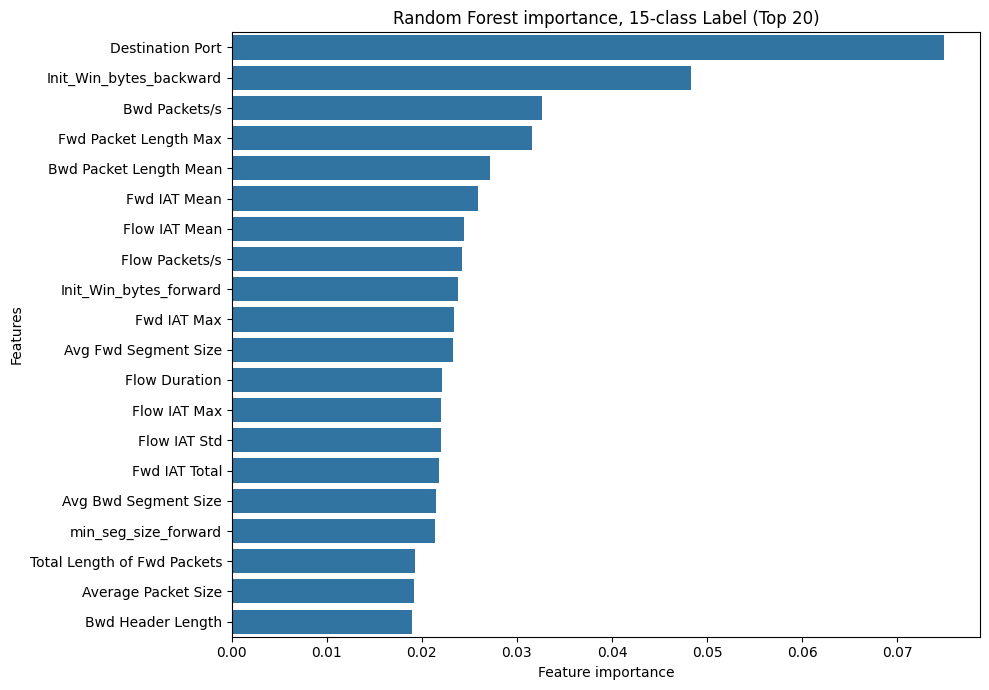

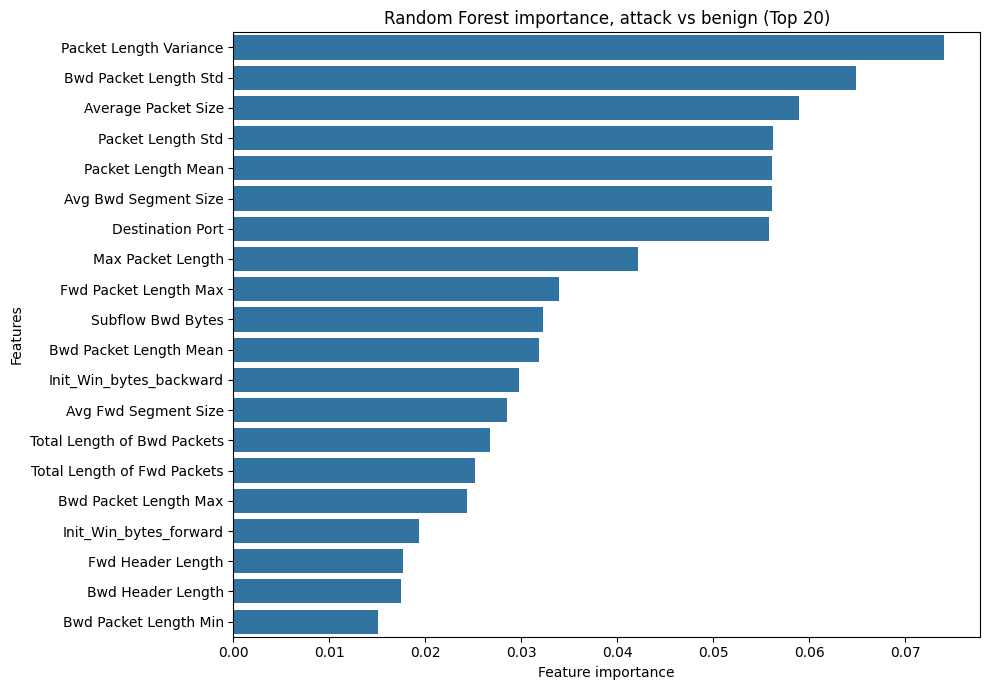

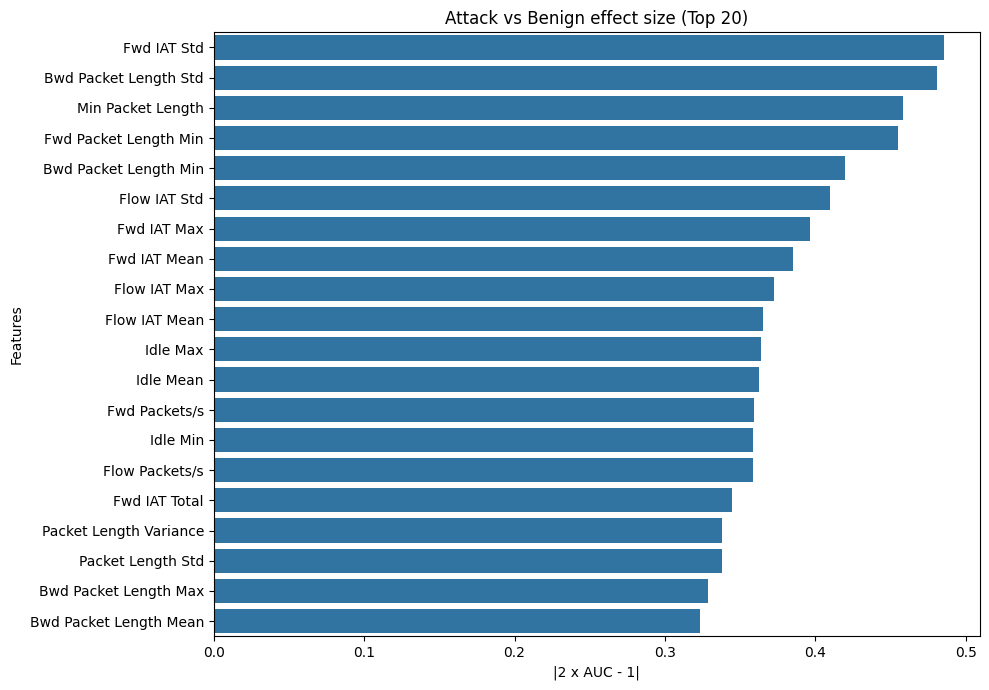

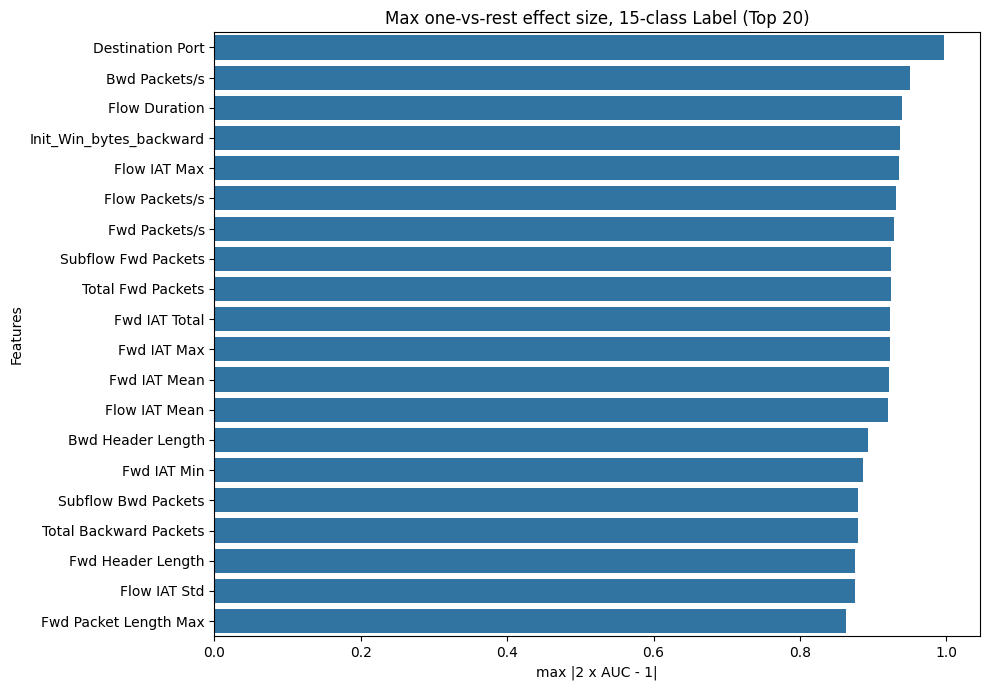

Recommended (binary ranking):


,mean_rank_binary
feature,
Packet Length Variance,6.666667
Bwd Packet Length Std,8.333333
Packet Length Std,8.333333
Average Packet Size,11.333333
Packet Length Mean,12.000000
Avg Bwd Segment Size,12.166667
Max Packet Length,13.000000
Bwd Packet Length Mean,13.500000
Subflow Bwd Bytes,15.166667


Recommended (multi-class ranking):


,mean_rank_multiclass
feature,
Flow Duration,7.333333
Flow IAT Max,7.666667
Flow Packets/s,8.000000
Bwd Packets/s,8.333333
Fwd IAT Max,9.000000
Fwd IAT Mean,10.000000
Flow IAT Mean,10.333333
Destination Port,11.333333
Init_Win_bytes_backward,12.000000


Note: the model features actually used below come from the Spearman + VIF reduction (training rows), not from these rankings; the rankings are descriptive.


In [ ]:
# [REV2-CHANGED] Importance plots for both target definitions (training rows only)
for col_, title_, xl_ in [
        ("rf_importance_multiclass", "Random Forest importance, 15-class Label (Top 20)", "Feature importance"),
        ("rf_importance_binary", "Random Forest importance, attack vs benign (Top 20)", "Feature importance"),
        ("effect", "Attack vs Benign effect size (Top 20)", "|2 x AUC - 1|"),
        ("effect_ovr_max", "Max one-vs-rest effect size, 15-class Label (Top 20)", "max |2 x AUC - 1|")]:
    top_ = eff.sort_values(col_, ascending=False).head(20)
    plt.figure(figsize=(10, 7))
    sns.barplot(x=top_[col_], y=top_.index)
    plt.title(title_); plt.xlabel(xl_); plt.ylabel("Features")
    plt.tight_layout(); plt.show()

# Recommended features after excluding near-constant features (one list per target definition)
recommended_binary = eff[~eff["near_constant"]].sort_values("mean_rank_binary")
recommended_multiclass = eff[~eff["near_constant"]].sort_values("mean_rank_multiclass")
print("Recommended (binary ranking):"); display(recommended_binary[["mean_rank_binary"]].head(25))
print("Recommended (multi-class ranking):"); display(recommended_multiclass[["mean_rank_multiclass"]].head(25))
print("Note: the model features actually used below come from the Spearman + VIF reduction (training rows), not from these rankings; the rankings are descriptive.")


In [ ]:
# (Export cell) The original ran nbconvert on a saved local notebook file.
# This only works if that file exists in the Colab session, so it is skipped otherwise.
import os, subprocess
NB = "Network_Intrusion_Detection_EDA.ipynb"
if os.path.exists(NB):
    subprocess.run("jupyter nbconvert Network_Intrusion_Detection_EDA.ipynb --to pdf --output EDA_Report.pdf", shell=True)
else:
    print("Skipped export: " + NB + " is not in this Colab session (not needed to run the analysis).")


Skipped export: Network_Intrusion_Detection_EDA.ipynb is not in this Colab session (not needed to run the analysis).


In [ ]:
# Data Validation and features

# imports and dataset validation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isna().sum().sum())

print("\nInfinite values:")
num_cols = df.select_dtypes(include=np.number).columns
print(np.isinf(df[num_cols]).sum().sum())

print("\nDuplicate observations:")
print(df.drop(columns="session").duplicated().sum())

print("\nClass distribution:")
display(df["Label"].value_counts().to_frame("Count"))

assert "Label" in df.columns
assert "session" in df.columns

Dataset shape: (2495065, 71)

Missing values:
0

Infinite values:
0

Duplicate observations:
0

Class distribution:


,Count
Label,
BENIGN,2069532
DoS Hulk,172688
DDoS,127995
PortScan,90694
DoS GoldenEye,10277
FTP-Patator,5927
DoS slowloris,5374
DoS Slowhttptest,5228
SSH-Patator,3217


In [ ]:
# TCP sentinel values
tcp_cols = [
    "Init_Win_bytes_forward",
    "Init_Win_bytes_backward"
]

for col in tcp_cols:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))
    print("Number of -1 values:", (df[col] == -1).sum())


Init_Win_bytes_forward
Init_Win_bytes_forward
-1.0        892898
 8192.0     321746
 29200.0    281808
 256.0       88830
 1024.0      83793
 0.0         80318
 65535.0     70592
 251.0       60117
 274.0       43337
 229.0       35653
Name: count, dtype: int64
Number of -1 values: 892898

Init_Win_bytes_backward
Init_Win_bytes_backward
-1.0        1194059
 0.0         201603
 235.0       176865
 229.0       103701
 256.0        42514
 31.0         18636
 33304.0      18309
 60.0         17671
 29200.0      16012
 65535.0      15000
Name: count, dtype: int64
Number of -1 values: 1194059


In [ ]:
# [CHANGED] Creating binary indicators for unknown TCP window values
# The flags are created ONCE, here, BEFORE -1 is replaced by NaN, and are named forward_unknown / backward_unknown
# (previously this cell produced "_forward_unknown" / "_backward_unknown" and a later cell recomputed
#  forward_unknown / backward_unknown AFTER the replacement, which gave two all-zero columns).
for col in tcp_cols:

    indicator = col.replace("Init_Win_bytes_", "").lower()      # "forward" / "backward"
    flag_name = f"{indicator}_unknown"

    if flag_name not in df.columns:                             # guard: re-running this cell must not overwrite the flag with zeros
        df[flag_name] = (df[col] == -1).astype("int8")

    df[col] = df[col].replace(-1, np.nan)

print({c: int(df[c].sum()) for c in ["forward_unknown", "backward_unknown"]})


{'forward_unknown': 892898, 'backward_unknown': 1194059}


In [ ]:
# Creating Active/ idle zero indicators

active_idle_cols = [
    "Active Mean",
    "Active Std",
    "Active Max",
    "Active Min",
    "Idle Mean",
    "Idle Std",
    "Idle Max",
    "Idle Min"
]

for col in active_idle_cols:

    if col in df.columns:

        indicator = (
            col.lower()
            .replace(" ", "_")
        )

        df[f"{indicator}_present"] = (
            df[col] > 0
        ).astype("int8")

In [ ]:
# Creating Destination Port service categories

def classify_port(port):

    if pd.isna(port):
        return "Unknown"

    port = int(port)

    common_ports = {
        20: "FTP",
        21: "FTP",
        22: "SSH",
        23: "Telnet",
        25: "SMTP",
        53: "DNS",
        67: "DHCP",
        68: "DHCP",
        80: "HTTP",
        110: "POP3",
        123: "NTP",
        143: "IMAP",
        443: "HTTPS",
        445: "SMB",
        993: "IMAPS",
        995: "POP3S"
    }

    if port in common_ports:
        return common_ports[port]

    elif 0 <= port <= 1023:
        return "Other_Well_Known"

    elif 1024 <= port <= 49151:
        return "Registered"

    elif 49152 <= port <= 65535:
        return "Dynamic"

    else:
        return "Unknown"


df["Destination_Port_Group"] = (
    df["Destination Port"].apply(classify_port)
)

display(
    df["Destination_Port_Group"]
    .value_counts()
    .to_frame("Count")
)

,Count
Destination_Port_Group,
DNS,859643
HTTP,539760
HTTPS,466153
Dynamic,302474
Registered,243584
Other_Well_Known,40231
NTP,20591
SSH,10066
FTP,9614


In [ ]:
# Examining these features
engineered_cols = [
    "forward_unknown",
    "backward_unknown",
    "active_mean_present",
    "active_std_present",
    "idle_mean_present",
    "idle_std_present",
    "Destination_Port_Group"
]

engineered_cols = [
    c for c in engineered_cols
    if c in df.columns
]

display(df[engineered_cols].head())

print("\nDataset shape after feature engineering:")
print(df.shape)

,forward_unknown,backward_unknown,active_mean_present,active_std_present,idle_mean_present,idle_std_present,Destination_Port_Group
0,0,1,0,0,0,0,Dynamic
1,0,0,0,0,0,0,Dynamic
2,0,0,0,0,0,0,Dynamic
3,0,0,0,0,0,0,Registered
4,0,1,0,0,0,0,Dynamic



Dataset shape after feature engineering:
(2495065, 82)


In [ ]:
df.to_parquet(
    "cic_ids2017_engineered.parquet",
    index=False
)

print("Engineered dataset saved successfully.")

Engineered dataset saved successfully.


In [ ]:
# [REV2-CHANGED] Spearman correlation and VIF-based feature reduction
# The train/test split was already made (train_idx / test_idx) before any supervised feature analysis.
# Spearman correlation and VIF below use the training rows only.

# Free the temporary training-only frame used by the ranking cells
globals().pop("df_fs", None)
import gc; gc.collect()

# Creating binary label (the engineered columns now exist in df, so the split frames are built here from the stored indices)
df["is_attack"] = (
    df["Label"] != "BENIGN"
).astype("int8")

df_train = df.loc[train_idx]
df_test = df.loc[test_idx]
assert df_train.index.intersection(df_test.index).empty

print("Training shape:", df_train.shape)
print("Testing shape:", df_test.shape)


Training shape: (1996052, 83)
Testing shape: (499013, 83)


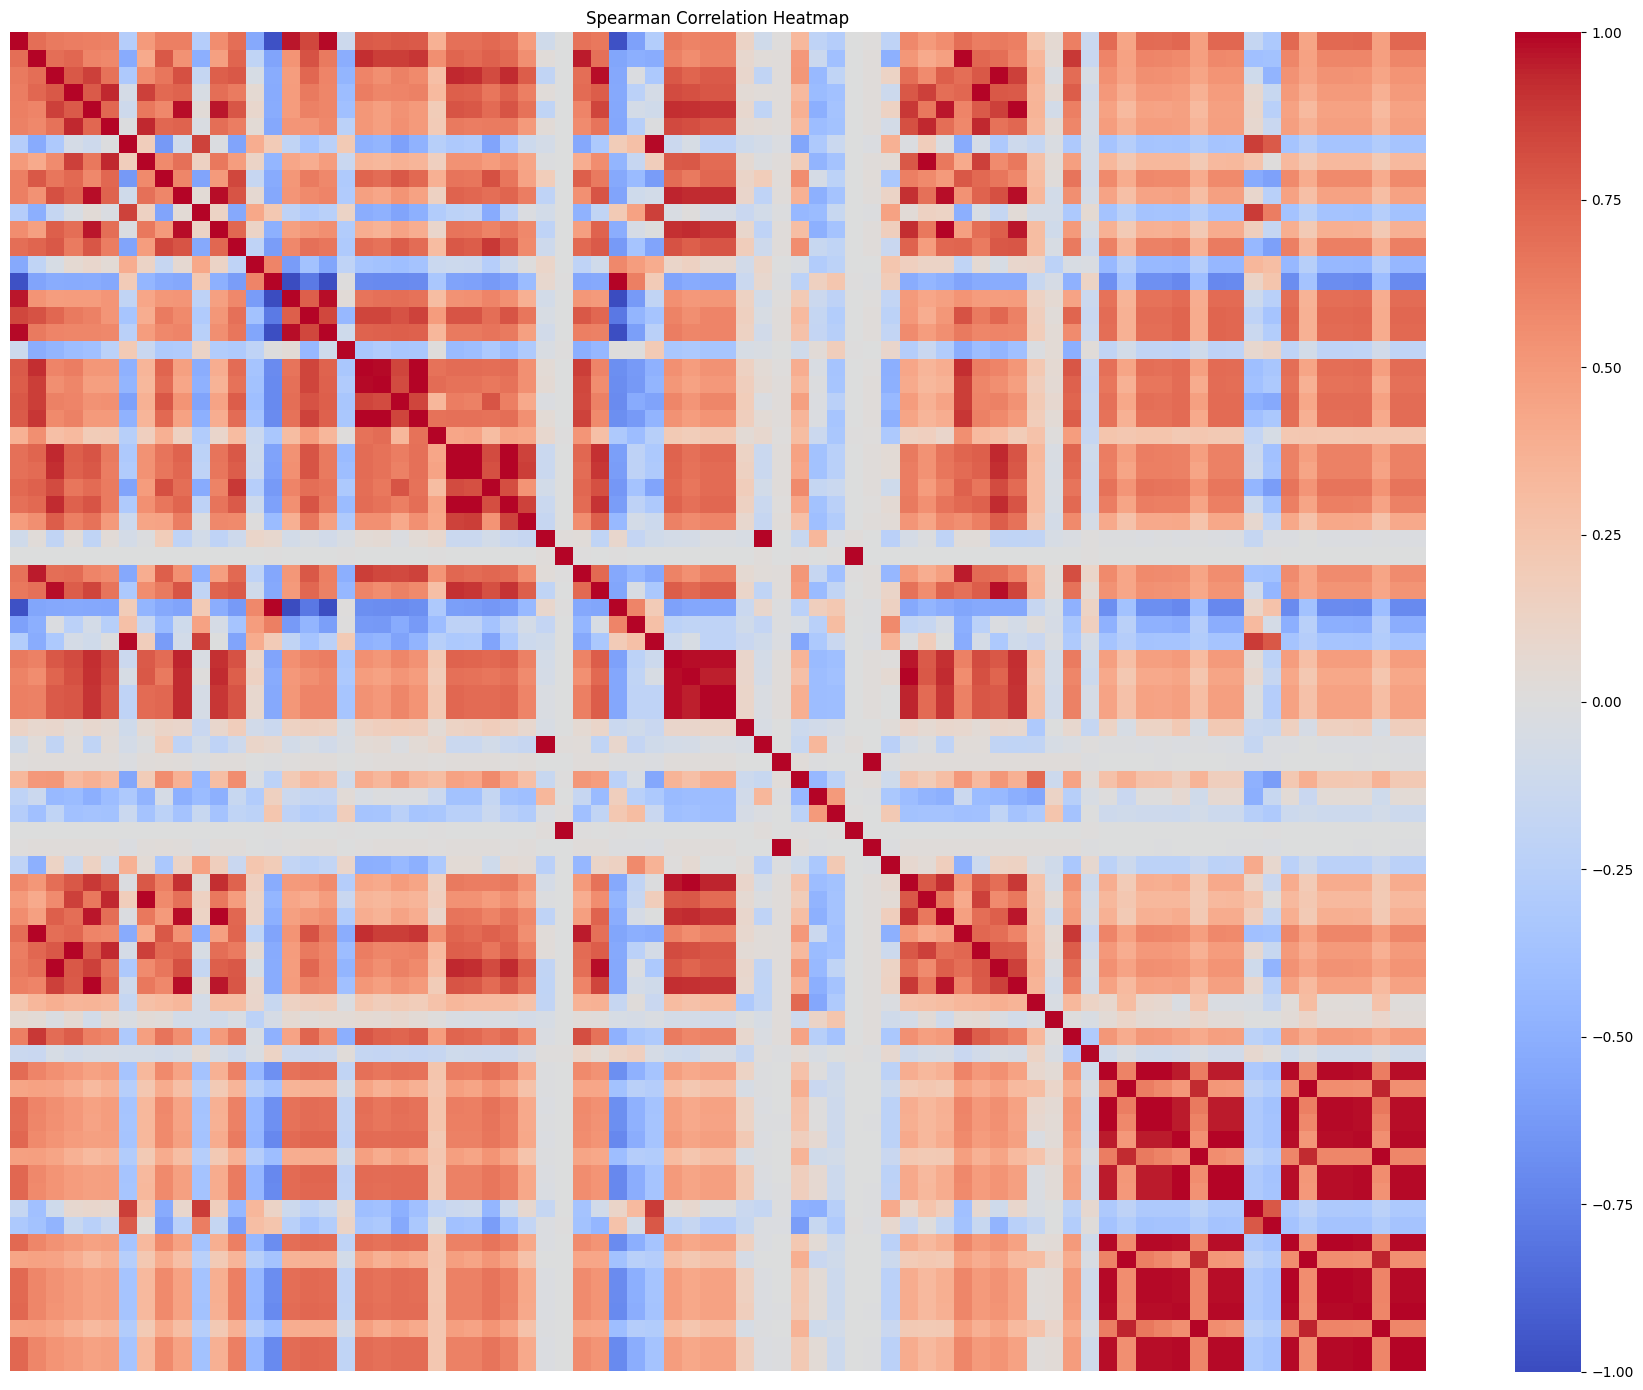

In [ ]:
# Calculating Spearman correlation
corr_features = [
    c for c in df_train.select_dtypes(include=np.number).columns
    if c not in [
        "Destination Port",
        "is_attack"
    ]
    and df_train[c].nunique(dropna=True) > 1
]

# Use a sample to reduce computational cost
corr_sample = df_train[corr_features].sample(
    n=min(100_000, len(df_train)),
    random_state=42
)

# Median imputation for correlation calculation
corr_sample = corr_sample.fillna(
    corr_sample.median()
)

# Spearman correlation
spearman_corr = corr_sample.corr(
    method="spearman"
)

plt.figure(figsize=(18, 14))

sns.heatmap(
    spearman_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
# Identifying Highly correlated feature pairs
upper = spearman_corr.where(
    np.triu(
        np.ones(spearman_corr.shape),
        k=1
    ).astype(bool)
)

correlated_pairs = (
    upper.stack()
    .reset_index()
)

correlated_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Spearman Correlation"
]

high_corr_pairs = correlated_pairs[
    correlated_pairs["Spearman Correlation"].abs() > 0.95
].copy()

high_corr_pairs["Absolute Correlation"] = (
    high_corr_pairs["Spearman Correlation"].abs()
)

high_corr_pairs = high_corr_pairs.sort_values(
    "Absolute Correlation",
    ascending=False
)

display(high_corr_pairs.head(50))

print(
    "Number of highly correlated pairs:",
    len(high_corr_pairs)
)

,Feature 1,Feature 2,Spearman Correlation,Absolute Correlation
204,Total Backward Packets,Subflow Bwd Packets,1.000000,1.000000
127,Total Fwd Packets,Subflow Fwd Packets,1.000000,1.000000
560,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
352,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
277,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
831,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
2377,RST Flag Count,ECE Flag Count,1.000000,1.000000
1890,Fwd URG Flags,CWE Flag Count,1.000000,1.000000
1838,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
3002,idle_max_present,idle_min_present,1.000000,1.000000


Number of highly correlated pairs: 114


In [ ]:
# Removing Rebundant features
corr_threshold = 0.95

abs_corr = spearman_corr.abs()

remaining_features = list(abs_corr.columns)
removed_corr_features = []

while True:

    current_corr = abs_corr.loc[
        remaining_features,
        remaining_features
    ]

    upper = current_corr.where(
        np.triu(
            np.ones(current_corr.shape),
            k=1
        ).astype(bool)
    )

    pairs = upper.stack()

    if pairs.empty or pairs.max() <= corr_threshold:
        break

    # Find the most highly correlated pair
    feature_1, feature_2 = pairs.idxmax()

    # Average correlation with all other features
    mean_corr = current_corr.mean()

    # Remove the feature with higher average redundancy
    if mean_corr[feature_1] >= mean_corr[feature_2]:
        drop_feature = feature_1
    else:
        drop_feature = feature_2

    remaining_features.remove(drop_feature)
    removed_corr_features.append(drop_feature)


print("Original feature count:", len(corr_features))
print("Remaining feature count:", len(remaining_features))

print("\nRemoved features:")
print(removed_corr_features)

Original feature count: 78
Remaining feature count: 40

Removed features:
['Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'Fwd PSH Flags', 'Fwd URG Flags', 'RST Flag Count', 'active_mean_present', 'active_max_present', 'idle_mean_present', 'idle_max_present', 'Packet Length Variance', 'Idle Max', 'Active Max', 'Idle Mean', 'Active Std', 'idle_std_present', 'Bwd IAT Max', 'Active Mean', 'Flow Packets/s', 'Bwd IAT Total', 'Fwd IAT Max', 'Packet Length Mean', 'Fwd Packets/s', 'idle_min_present', 'Fwd IAT Total', 'active_min_present', 'Flow Duration', 'Min Packet Length', 'Max Packet Length', 'Subflow Bwd Bytes', 'Bwd Packet Length Max', 'Flow IAT Max', 'Subflow Bwd Packets', 'Idle Min', 'Subflow Fwd Packets']


In [ ]:
# Calculating VIF factors
!pip install statsmodels

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

# Sample training observations
vif_sample = df_train[remaining_features].sample(
    n=min(20_000, len(df_train)),
    random_state=42
)

# Impute missing values
vif_sample = vif_sample.fillna(
    vif_sample.median()
)

# Remove any remaining constant columns
vif_features = [
    c for c in vif_sample.columns
    if vif_sample[c].nunique() > 1
]

vif_sample = vif_sample[vif_features]

# Standardise for numerical stability
scaler_vif = StandardScaler()

X_vif = scaler_vif.fit_transform(vif_sample)

# Iteratively remove features with VIF > 10
while True:

    vif_values = pd.Series(
        [
            variance_inflation_factor(X_vif, i)
            for i in range(X_vif.shape[1])
        ],
        index=vif_features
    )

    max_vif = vif_values.max()

    if max_vif <= 10:
        break

    feature_to_remove = vif_values.idxmax()

    print(
        "Removing:",
        feature_to_remove,
        "| VIF:",
        round(max_vif, 2)
    )

    vif_features.remove(feature_to_remove)

    X_vif = scaler_vif.fit_transform(
        vif_sample[vif_features]
    )


vif_final = pd.DataFrame({
    "Feature": vif_features,
    "VIF": [
        variance_inflation_factor(X_vif, i)
        for i in range(X_vif.shape[1])
    ]
})

display(
    vif_final.sort_values(
        "VIF",
        ascending=False
    )
)

print("Features remaining after VIF:", len(vif_features))

Removing: Fwd IAT Min | VIF: 593.26
Removing: Packet Length Std | VIF: 172.62
Removing: Flow IAT Std | VIF: 163.36
Removing: forward_unknown | VIF: 99.19
Removing: Bwd IAT Mean | VIF: 95.98
Removing: Flow IAT Mean | VIF: 57.02
Removing: Fwd Packet Length Std | VIF: 52.85
Removing: Avg Bwd Segment Size | VIF: 46.62
Removing: Fwd IAT Mean | VIF: 10.58


,Feature,VIF
20,Avg Fwd Segment Size,9.861725
9,Fwd Header Length,8.988486
10,Bwd Header Length,8.642386
14,PSH Flag Count,8.595486
0,Fwd Packet Length Max,7.811655
19,Average Packet Size,7.592886
3,Bwd Packet Length Std,7.233075
28,backward_unknown,6.231904
15,ACK Flag Count,4.499875
6,Fwd IAT Std,3.804616


Features remaining after VIF: 30


In [ ]:
# Saving reduced feature list
selected_features = vif_features.copy()

print("Final selected numerical features:")
for feature in selected_features:
    print(feature)

print("\nTotal selected features:", len(selected_features))

pd.Series(
    selected_features,
    name="Selected_Features"
).to_csv(
    "selected_features.csv",
    index=False
)

Final selected numerical features:
Fwd Packet Length Max
Fwd Packet Length Min
Bwd Packet Length Min
Bwd Packet Length Std
Flow Bytes/s
Flow IAT Min
Fwd IAT Std
Bwd IAT Std
Bwd IAT Min
Fwd Header Length
Bwd Header Length
Bwd Packets/s
FIN Flag Count
SYN Flag Count
PSH Flag Count
ACK Flag Count
URG Flag Count
ECE Flag Count
Down/Up Ratio
Average Packet Size
Avg Fwd Segment Size
Subflow Fwd Bytes
Init_Win_bytes_forward
Init_Win_bytes_backward
act_data_pkt_fwd
min_seg_size_forward
Active Min
Idle Std
backward_unknown
active_std_present

Total selected features: 30


In [ ]:
# Grouping Rare Attack classes

# Defining Attack taxonomy
attack_mapping = {

    # Normal traffic
    "BENIGN": "BENIGN",

    # Denial of Service family
    "DDoS": "DoS_DDoS",
    "DoS Hulk": "DoS_DDoS",
    "DoS GoldenEye": "DoS_DDoS",
    "DoS slowloris": "DoS_DDoS",
    "DoS Slowhttptest": "DoS_DDoS",

    # Reconnaissance
    "PortScan": "Reconnaissance",

    # Brute-force attacks
    "FTP-Patator": "Brute_Force",
    "SSH-Patator": "Brute_Force",
    "Web Attack - Brute Force": "Brute_Force",

    # Web attacks
    "Web Attack - XSS": "Web_Attack",
    "Web Attack - Sql Injection": "Web_Attack",

    # Bot activity
    "Bot": "Bot",

    # Extremely rare classes
    "Heartbleed": "Other_Rare",
    "Infiltration": "Other_Rare"
}

df["Label_grouped"] = df["Label"].map(
    attack_mapping
)

# Check for labels that were not mapped
unmapped = df.loc[
    df["Label_grouped"].isna(),
    "Label"
].unique()

print("Unmapped labels:", unmapped)

assert df["Label_grouped"].notna().all()

Unmapped labels: []


In [ ]:
# Comparing original and grouped class distributions
original_counts = df["Label"].value_counts()

grouped_counts = df["Label_grouped"].value_counts()

print("Original class distribution:")
display(original_counts.to_frame("Count"))

print("\nGrouped class distribution:")
display(grouped_counts.to_frame("Count"))

Original class distribution:


,Count
Label,
BENIGN,2069532
DoS Hulk,172688
DDoS,127995
PortScan,90694
DoS GoldenEye,10277
FTP-Patator,5927
DoS slowloris,5374
DoS Slowhttptest,5228
SSH-Patator,3217



Grouped class distribution:


,Count
Label_grouped,
BENIGN,2069532
DoS_DDoS,321562
Reconnaissance,90694
Brute_Force,10614
Bot,1948
Web_Attack,673
Other_Rare,42


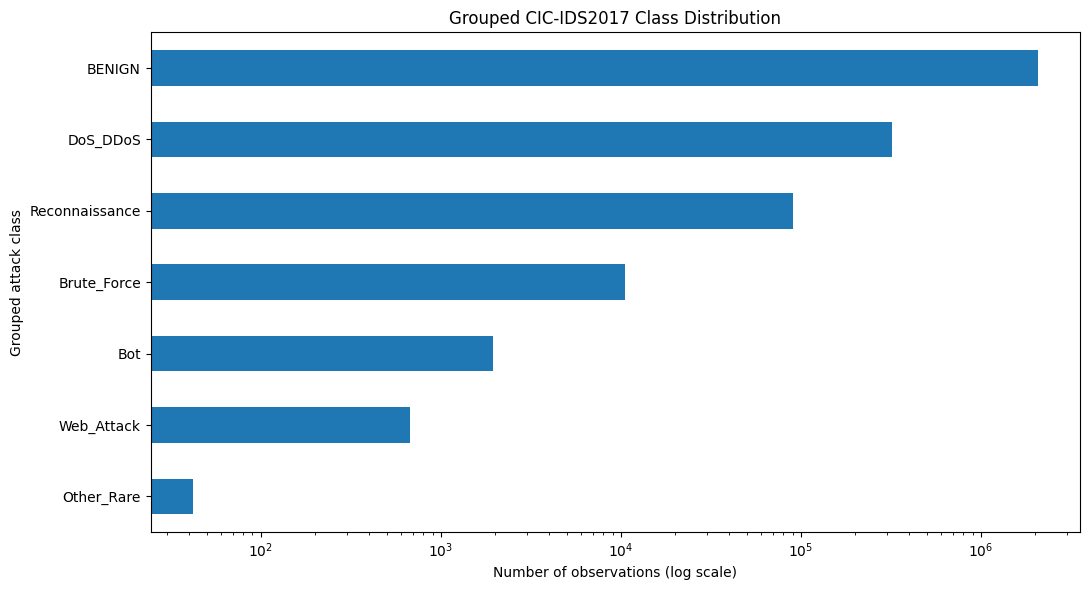

In [ ]:
# Visualise the grouped class distribution
plt.figure(figsize=(11, 6))

grouped_counts.sort_values().plot(
    kind="barh",
    logx=True
)

plt.xlabel("Number of observations (log scale)")
plt.ylabel("Grouped attack class")
plt.title("Grouped CIC-IDS2017 Class Distribution")

plt.tight_layout()
plt.show()

In [ ]:
# Comparing original and grouped labels
comparison = pd.crosstab(
    df["Label"],
    df["Label_grouped"]
)

display(comparison)

Label_grouped,BENIGN,Bot,Brute_Force,DoS_DDoS,Other_Rare,Reconnaissance,Web_Attack
Label,,,,,,,
BENIGN,2069532,0,0,0,0,0,0
Bot,0,1948,0,0,0,0,0
DDoS,0,0,0,127995,0,0,0
DoS GoldenEye,0,0,0,10277,0,0,0
DoS Hulk,0,0,0,172688,0,0,0
DoS Slowhttptest,0,0,0,5228,0,0,0
DoS slowloris,0,0,0,5374,0,0,0
FTP-Patator,0,0,5927,0,0,0,0
Heartbleed,0,0,0,0,7,0,0


In [ ]:
# Create binary and multiclass targets
# Binary classification target
df["Binary_Label"] = (
    df["Label"] != "BENIGN"
).astype("int8")

# Multiclass classification target
df["Multiclass_Label"] = df["Label_grouped"]

print("Binary classification:")
display(df["Binary_Label"].value_counts())

print("\nGrouped multiclass classification:")
display(df["Multiclass_Label"].value_counts())

Binary classification:


,count
Binary_Label,
0,2069532
1,425533



Grouped multiclass classification:


,count
Multiclass_Label,
BENIGN,2069532
DoS_DDoS,321562
Reconnaissance,90694
Brute_Force,10614
Bot,1948
Web_Attack,673
Other_Rare,42


In [ ]:
# [CHANGED] Sentinel flags: verification only (nothing is recomputed here any more)
# forward_unknown / backward_unknown were created in the TCP-indicator cell while the -1 values were still present.
# Recomputing them here, after -1 had become NaN, is what produced two all-zero columns.
for flag_name, source_col in [("forward_unknown", "Init_Win_bytes_forward"),
                              ("backward_unknown", "Init_Win_bytes_backward")]:
    assert flag_name in df.columns, f"{flag_name} is missing - run the engineering cell above first"
    n_flag = int(df[flag_name].sum())
    assert n_flag > 0, f"{flag_name} is all zero - the sentinel flag was lost"
    assert bool(df.loc[df[flag_name] == 1, source_col].isna().all()), f"{source_col} still holds -1 where {flag_name} == 1"
    print(f"{flag_name}: {n_flag:,} flows flagged; {source_col} NaN count: {int(df[source_col].isna().sum()):,}")


forward_unknown: 892,898 flows flagged; Init_Win_bytes_forward NaN count: 892,898
backward_unknown: 1,194,059 flows flagged; Init_Win_bytes_backward NaN count: 1,194,059


In [ ]:
# Preparing Modelling dataset
from sklearn.model_selection import train_test_split

# Use grouped multiclass classification
target = "Label_grouped"

# Numerical features selected through Spearman and VIF
numeric_features = selected_features.copy()

# Add engineered binary indicators
engineered_numeric = [
    "forward_unknown",
    "backward_unknown",
    "active_mean_present",
    "active_std_present",
    "active_max_present",
    "active_min_present",
    "idle_mean_present",
    "idle_std_present",
    "idle_max_present",
    "idle_min_present"
]

for col in engineered_numeric:

    if col in df.columns and col not in numeric_features:
        numeric_features.append(col)

# Remove any unavailable columns
numeric_features = [
    c for c in numeric_features
    if c in df.columns
]

# Categorical features
categorical_features = [
    "Destination_Port_Group"
]

# Protocol is a categorical variable, not a continuous measurement
if "Protocol" in df.columns:

    df["Protocol"] = (
        df["Protocol"]
        .astype("string")
    )

    categorical_features.append("Protocol")

# Do not include the raw Destination Port
numeric_features = [
    c for c in numeric_features
    if c != "Destination Port"
]

feature_columns = (
    numeric_features + categorical_features
)

X = df[feature_columns].copy()
y = df[target].copy()

# [ADDED] the two sentinel flags must now carry information (they were all-zero before the fix)
for flag_name in ["forward_unknown", "backward_unknown"]:
    assert flag_name in numeric_features and df[flag_name].nunique() > 1, f"{flag_name} is missing or constant"
print("Constant numeric columns:", [c for c in numeric_features if df[c].nunique() <= 1])

print("Numerical features:", len(numeric_features))
print("Categorical features:", categorical_features)

print("X shape:", X.shape)
print("y shape:", y.shape)

Constant numeric columns: []
Numerical features: 38
Categorical features: ['Destination_Port_Group']
X shape: (2495065, 39)
y shape: (2495065,)


In [ ]:
# [CHANGED] Training and test data = exactly the df_train / df_test split made earlier
# (the same rows that Spearman + VIF feature selection was done on), so the test rows
# were never seen by the feature selection. That split is stratified on the original Label.
assert df.index.is_unique
X_train, X_test = X.loc[df_train.index], X.loc[df_test.index]
y_train, y_test = y.loc[df_train.index], y.loc[df_test.index]
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) == len(df_train) and len(X_test) == len(df_test)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

print("\nTraining class distribution:")
display(y_train.value_counts())

print("\nTesting class distribution:")
display(y_test.value_counts())


Training observations: 1996052
Testing observations: 499013

Training class distribution:


,count
Label_grouped,
BENIGN,1655625
DoS_DDoS,257249
Reconnaissance,72555
Brute_Force,8492
Bot,1558
Web_Attack,539
Other_Rare,34



Testing class distribution:


,count
Label_grouped,
BENIGN,413907
DoS_DDoS,64313
Reconnaissance,18139
Brute_Force,2122
Bot,390
Web_Attack,134
Other_Rare,8


In [ ]:
# [REV2-ADDED] Feature-leakage checks (training rows only, except the explicit train/test overlap check)
from scipy.stats import rankdata

# 1) no identifier / time / label-derived column among the model inputs
FORBIDDEN = {"flow id", "source ip", "destination ip", "src ip", "dst ip", "timestamp", "source port", "session",
             "label", "label_grouped", "binary_label", "multiclass_label", "is_attack"}
bad_cols = [c for c in feature_columns if c.strip().lower() in FORBIDDEN]
assert not bad_cols, f"identifier / label-derived columns used as features: {bad_cols}"
print("1) No identifier, session or label-derived column among the", len(feature_columns), "model inputs.")

# 2) single-feature screen: a lone feature that almost perfectly separates attack from benign deserves a look
yb_tr = (y_train != "BENIGN").to_numpy()
scr_ix = np.random.default_rng(SEED).choice(len(X_train), size=min(200_000, len(X_train)), replace=False)
scr = X_train[numeric_features].iloc[scr_ix]
scr = scr.fillna(scr.median())
yb_s = yb_tr[scr_ix]
n1, n0 = int(yb_s.sum()), int((~yb_s).sum())
auc_single = {}
for c_ in numeric_features:
    r_ = rankdata(scr[c_].to_numpy())
    auc_single[c_] = (r_[yb_s].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
auc_single = pd.Series(auc_single)
strength = np.maximum(auc_single, 1 - auc_single).sort_values(ascending=False)
print("2) Strongest single features, attack vs benign (AUC, direction ignored; training rows):")
display(strength.head(8).round(4).to_frame("AUC"))
suspicious = strength[strength > 0.99]
print("   Features with AUC > 0.99:", list(suspicious.index) if len(suspicious) else "none")
print("   (A high value is not automatically a leak - e.g. PortScan flows have tiny packet counts - but it must be explainable.)")

# 3) exact feature-vector overlap between training and test rows (near-duplicates inflate random-split scores)
h_tr = pd.util.hash_pandas_object(X_train, index=False).to_numpy()
h_te = pd.util.hash_pandas_object(X_test, index=False).to_numpy()
overlap = np.isin(h_te, h_tr)
lab_map = pd.DataFrame({"h": h_tr, "y": y_train.to_numpy()}).drop_duplicates()
te_df = pd.DataFrame({"h": h_te[overlap], "y": y_test.to_numpy()[overlap]})
same_label = te_df.merge(lab_map, on=["h", "y"], how="inner")["h"].nunique()
print(f"3) Test rows whose exact model-feature vector also occurs in training: {int(overlap.sum()):,} of {len(h_te):,} ({overlap.mean():.2%})")
overlap_by_class = pd.Series(overlap, index=y_test.index).groupby(y_test).mean().round(3)
display(overlap_by_class.to_frame("share of test rows also in train"))
print("   Read the random-split scores with this share in mind; the session-grouped evaluation below is the stricter check.")

# 4) stratification check: class shares in train and test agree
share_tr, share_te = y_train.value_counts(normalize=True), y_test.value_counts(normalize=True)
max_gap = float((share_tr - share_te.reindex(share_tr.index)).abs().max())
assert max_gap < 0.002, max_gap
print(f"4) Largest class-share gap between train and test: {max_gap:.5f}")

# 5) sessions present on both sides (expected for a random split; this is exactly what the session-grouped evaluation changes)
print("5) Sessions in train:", df.loc[X_train.index, "session"].nunique(), "| in test:", df.loc[X_test.index, "session"].nunique(), "(random split: every session appears on both sides)")
leakage_check_summary = {"model_inputs": len(feature_columns), "features_auc_gt_0.99": list(suspicious.index),
                         "test_rows_with_exact_vector_in_train_share": float(overlap.mean()),
                         "max_class_share_gap_train_test": max_gap}

1) No identifier, session or label-derived column among the 39 model inputs.
2) Strongest single features, attack vs benign (AUC, direction ignored; training rows):


,AUC
Fwd IAT Std,0.7461
Bwd Packet Length Std,0.7409
Fwd Packet Length Min,0.7273
forward_unknown,0.7161
Bwd Packet Length Min,0.7119
backward_unknown,0.6974
Init_Win_bytes_backward,0.6850
idle_min_present,0.6587


   Features with AUC > 0.99: none
   (A high value is not automatically a leak - e.g. PortScan flows have tiny packet counts - but it must be explainable.)
3) Test rows whose exact model-feature vector also occurs in training: 68,683 of 499,013 (13.76%)


,share of test rows also in train
Label_grouped,
BENIGN,0.122
Bot,0.344
Brute_Force,0.000
DoS_DDoS,0.007
Other_Rare,0.000
Reconnaissance,0.972
Web_Attack,0.000


   Read the random-split scores with this share in mind; the session-grouped evaluation below is the stricter check.
4) Largest class-share gap between train and test: 0.00000
5) Sessions in train: 8 | in test: 8 (random split: every session appears on both sides)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    FunctionTransformer,
    RobustScaler,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer

def signed_log1p(X):

    return np.sign(X) * np.log1p(np.abs(X))


numeric_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "log_transform",
            FunctionTransformer(
                signed_log1p,
                validate=False
            )
        ),

        (
            "scaler",
            RobustScaler()
        )

    ]
)

In [ ]:
# Categorical preprocessing pipeline
categorical_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),

        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )

    ]
)

In [ ]:
# Combining the preprocessing steps

preprocessor = ColumnTransformer(

    transformers=[

        (
            "numerical",
            numeric_pipeline,
            numeric_features
        ),

        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )

    ],

    remainder="drop",

    sparse_threshold=1.0
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

logistic_model = Pipeline(

    steps=[

        (
            "preprocessing",
            preprocessor
        ),

        (
            "classifier",
            LogisticRegression(
                C=1.0,
                solver="saga",
                l1_ratio=0.0,
                max_iter=300,
                tol=1e-3,
                class_weight="balanced",
                random_state=42
            )
        )

    ]
)

In [ ]:
from sklearn.model_selection import train_test_split

# Take a stratified sample from training data only
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=300_000,
    random_state=42,
    stratify=y_train
)

print("Original training size:", X_train.shape)
print("Sampled training size:", X_train_sample.shape)
print("Testing size:", X_test.shape)

print("\nSampled class distribution:")
display(y_train_sample.value_counts())

Original training size: (1996052, 39)
Sampled training size: (300000, 39)
Testing size: (499013, 39)

Sampled class distribution:


,count
Label_grouped,
BENIGN,248835
DoS_DDoS,38664
Reconnaissance,10905
Brute_Force,1276
Bot,234
Web_Attack,81
Other_Rare,5


In [ ]:
# Train the revised Logistic Regression model
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),

        ("classifier", LogisticRegression(
            C=1.0,
            solver="saga",
            l1_ratio=0.0,
            max_iter=300,
            tol=1e-3,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

logistic_model.fit(
    X_train_sample,
    y_train_sample
)

print("Model training completed.")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


Model training completed.


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:
# Evaluate using the original test set
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

y_pred = logistic_model.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Macro F1:",
      f1_score(y_test, y_pred, average="macro"))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Accuracy: 0.9050686054271131
Macro F1: 0.4896655016137519

Classification Report:
                precision    recall  f1-score   support

        BENIGN       1.00      0.89      0.94    413907
           Bot       0.02      0.98      0.04       390
   Brute_Force       0.47      0.87      0.61      2122
      DoS_DDoS       0.92      0.98      0.95     64313
    Other_Rare       0.00      0.75      0.00         8
Reconnaissance       0.76      0.99      0.86     18139
    Web_Attack       0.01      0.99      0.03       134

      accuracy                           0.91    499013
     macro avg       0.45      0.92      0.49    499013
  weighted avg       0.98      0.91      0.94    499013



In [ ]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training data shape: (1996052, 39)
Testing data shape: (499013, 39)

Training labels:
Label_grouped
BENIGN            1655625
DoS_DDoS           257249
Reconnaissance      72555
Brute_Force          8492
Bot                  1558
Web_Attack            539
Other_Rare             34
Name: count, dtype: int64

Testing labels:
Label_grouped
BENIGN            413907
DoS_DDoS           64313
Reconnaissance     18139
Brute_Force         2122
Bot                  390
Web_Attack           134
Other_Rare             8
Name: count, dtype: int64


In [ ]:
%pip install psutil
import psutil

print("Total RAM:",
      round(psutil.virtual_memory().total / (1024**3), 2), "GB")

print("Available RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2), "GB")

Total RAM: 12.67 GB
Available RAM: 7.0 GB


In [ ]:
import psutil
import os

process = psutil.Process(os.getpid())

print("RAM currently used by Python:",
      round(process.memory_info().rss / (1024**3), 2), "GB")

print("Total system RAM:",
      round(psutil.virtual_memory().total / (1024**3), 2), "GB")

print("Available system RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2), "GB")

RAM currently used by Python: 4.84 GB
Total system RAM: 12.67 GB
Available system RAM: 7.0 GB


In [ ]:
print("Feature data types:")
print(X_train.dtypes.value_counts())

print("\nCategorical columns:")
print(X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist())

print("\nNumerical columns:")
print(X_train.select_dtypes(
    include="number"
).columns.tolist())

Feature data types:
float32    28
int8       10
object      1
Name: count, dtype: int64

Categorical columns:
['Destination_Port_Group']

Numerical columns:
['Fwd Packet Length Max', 'Fwd Packet Length Min', 'Bwd Packet Length Min', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow IAT Min', 'Fwd IAT Std', 'Bwd IAT Std', 'Bwd IAT Min', 'Fwd Header Length', 'Bwd Header Length', 'Bwd Packets/s', 'FIN Flag Count', 'SYN Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Avg Fwd Segment Size', 'Subflow Fwd Bytes', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Active Min', 'Idle Std', 'backward_unknown', 'active_std_present', 'forward_unknown', 'active_mean_present', 'active_max_present', 'active_min_present', 'idle_mean_present', 'idle_std_present', 'idle_max_present', 'idle_min_present']


In [ ]:
import numpy as np
from scipy import sparse

X_sample = X_train.sample(
    n=50_000,
    random_state=42
)

X_sample_transformed = preprocessor.fit_transform(X_sample)

if sparse.issparse(X_sample_transformed):
    memory_gb = (
        X_sample_transformed.data.nbytes
        + X_sample_transformed.indices.nbytes
        + X_sample_transformed.indptr.nbytes
    ) / (1024**3)
else:
    memory_gb = X_sample_transformed.nbytes / (1024**3)

print("Transformed shape:", X_sample_transformed.shape)
print("Sparse matrix:", sparse.issparse(X_sample_transformed))
print("Memory required:", round(memory_gb, 3), "GB")

Transformed shape: (50000, 53)
Sparse matrix: True
Memory required: 0.011 GB


In [ ]:
import psutil

print("Available RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2),
      "GB")

Available RAM: 6.98 GB


In [ ]:
log_reg = LogisticRegression(
    C=1.0,
    solver="saga",
    l1_ratio=0.0,
    max_iter=500,
    tol=1e-3,
    class_weight="balanced",
    random_state=42
)

In [ ]:
# Configure the model
import time
import psutil
import os

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    C=1.0,
    solver="saga",
    l1_ratio=0.0,
    max_iter=100,
    tol=1e-3,
    class_weight="balanced",
    random_state=42
)

log_reg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", log_reg)
])

In [ ]:
#Training on the complete training dataset
process = psutil.Process(os.getpid())

start_time = time.time()

print("Full training started...")

log_reg_pipeline.fit(X_train, y_train)

end_time = time.time()

print("\nTraining completed.")

print("Time taken:",
      round((end_time - start_time) / 60, 2), "minutes")

print("Python memory usage:",
      round(process.memory_info().rss / (1024**3), 2), "GB")

print("Available system RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2), "GB")

print("Iterations:",
      log_reg_pipeline.named_steps["classifier"].n_iter_)

Full training started...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(



Training completed.
Time taken: 4.63 minutes
Python memory usage: 4.85 GB
Available system RAM: 6.97 GB
Iterations: [100]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict on the untouched test set
y_pred = log_reg_pipeline.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Macro F1-score:",
      f1_score(y_test, y_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.909060485398176
Macro F1-score: 0.4791699579912563

Classification Report:
                precision    recall  f1-score   support

        BENIGN       1.00      0.90      0.94    413907
           Bot       0.02      0.98      0.05       390
   Brute_Force       0.30      0.99      0.47      2122
      DoS_DDoS       0.91      0.97      0.94     64313
    Other_Rare       0.00      0.88      0.00         8
Reconnaissance       0.91      0.99      0.95     18139
    Web_Attack       0.00      0.04      0.01       134

      accuracy                           0.91    499013
     macro avg       0.45      0.82      0.48    499013
  weighted avg       0.98      0.91      0.94    499013


Confusion Matrix:
[[370700  16104   4288   6123  13902   1664   1126]
 [     4    382      0      0      4      0      0]
 [     4      0   2109      0      0      5      4]
 [   988      0    378  62467    386      2     92]
 [     0      0      0      0      7      1      0]
 [   112      0

In [ ]:
log_reg_unbalanced = LogisticRegression(
    C=1.0,
    solver="saga",
    l1_ratio=0.0,
    max_iter=100,
    tol=1e-3,
    class_weight=None,
    random_state=42
)

log_reg_pipeline_unbalanced = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", log_reg_unbalanced)
])

log_reg_pipeline_unbalanced.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(sparse_threshold=1.0,
                                   transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(func=<function signed_log1p at 0x7fad6c06ce00>)),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['Fwd Packet Length Max',
                                                   'Fwd Packet Length Min',
                                                   'Bwd Packet Length Min',
                                                   'Bwd Packet Length...
                                                   'act_data_pkt_fwd',
                                                   'min_seg_size_forward',
                                                   'Active Min', 'Idle Std',
                                                   'backward_unknown',
                                                   'active_std_present', ...]),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Destination_Port_Group'])])),
                ('classifier',
                 LogisticRegression(l1_ratio=0.0, random_state=42,
                                    solver='saga', tol=0.001))])

In [ ]:
# Evaluate
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predictions on the same untouched test set
y_pred_unbalanced = log_reg_pipeline_unbalanced.predict(X_test)

# Evaluation
print("Accuracy:",
      accuracy_score(y_test, y_pred_unbalanced))

print("Macro F1-score:",
      f1_score(y_test, y_pred_unbalanced, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_unbalanced,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_unbalanced))

Accuracy: 0.9950261816826416
Macro F1-score: 0.6770709794020612

Classification Report:
                precision    recall  f1-score   support

        BENIGN       1.00      1.00      1.00    413907
           Bot       0.80      0.40      0.53       390
   Brute_Force       0.96      0.84      0.89      2122
      DoS_DDoS       0.99      0.99      0.99     64313
    Other_Rare       0.50      0.25      0.33         8
Reconnaissance       0.99      1.00      0.99     18139
    Web_Attack       0.00      0.00      0.00       134

      accuracy                           1.00    499013
     macro avg       0.75      0.64      0.68    499013
  weighted avg       0.99      1.00      0.99    499013


Confusion Matrix:
[[412886     39     73    680      2    227      0]
 [   234    156      0      0      0      0      0]
 [   344      0   1775      3      0      0      0]
 [   691      0      0  63622      0      0      0]
 [     6      0      0      0      2      0      0]
 [    30      

## [ADDED] Validating the custom class weights inside the training data

The weights `1, 1, 1, 3, 10, 10, 10` were first picked after looking at the test set. Here they are chosen on a
validation split taken **inside** `X_train` (80 / 20, stratified); the test set is not touched.
Large classes are capped for speed and given sample weights that restore the natural class mix, so the validation score reflects the real class balance.
The winning weights replace the hand-picked ones in the next code cell, and the test set is evaluated once, afterwards.
With only a handful of `Other_Rare` rows in the validation part, that class is noisy; candidates are ranked by Macro-F1 over all 7 classes.

In [ ]:
# [ADDED] Validation split inside X_train to choose the class weights (test set stays held out)
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train)

# cap big classes, restore their natural weight with sample weights
FIT_CAP = 100_000
rng_val = np.random.default_rng(42)
keep_pos, sw_parts = [], []
for cls_name in sorted(y_fit.unique()):
    pos_cls = np.where((y_fit == cls_name).to_numpy())[0]
    take_cls = pos_cls if len(pos_cls) <= FIT_CAP else rng_val.choice(pos_cls, FIT_CAP, replace=False)
    keep_pos.append(take_cls)
    sw_parts.append(np.full(len(take_cls), len(pos_cls) / len(take_cls)))
keep_pos, sw_fit = np.concatenate(keep_pos), np.concatenate(sw_parts)
X_fit_s, y_fit_s = X_fit.iloc[keep_pos], y_fit.iloc[keep_pos]

pre_val = clone(preprocessor).fit(X_fit_s)          # clone: the shared `preprocessor` object is left untouched
M_fit, M_val = pre_val.transform(X_fit_s), pre_val.transform(X_val)

def make_weights(bot, brute, other, web):
    return {"BENIGN": 1, "Bot": bot, "Brute_Force": brute, "DoS_DDoS": 1,
            "Other_Rare": other, "Reconnaissance": 1, "Web_Attack": web}

weight_candidates = {
    "uniform":                     make_weights(1, 1, 1, 1),
    "mild (x3)":                   make_weights(3, 2, 3, 3),
    "ORIGINAL (10/3/10/10)":       make_weights(10, 3, 10, 10),
    "original, Brute_Force=1":     make_weights(10, 1, 10, 10),
    "original, Brute_Force=10":    make_weights(10, 10, 10, 10),
    "strong (x30)":                make_weights(30, 10, 30, 30),
}

val_rows = []
for cand_name, cand_w in weight_candidates.items():
    lr_val = LogisticRegression(C=1.0, solver="saga", max_iter=100, tol=1e-3, class_weight=cand_w, random_state=42)
    lr_val.fit(M_fit, y_fit_s, sample_weight=sw_fit)
    pred_val = lr_val.predict(M_val)
    f1_each = f1_score(y_val, pred_val, labels=lr_val.classes_, average=None, zero_division=0)
    val_rows.append({"weights": cand_name, "validation Macro-F1": f1_score(y_val, pred_val, labels=lr_val.classes_, average="macro", zero_division=0),
                     **{f"F1 {k}": v for k, v in zip(lr_val.classes_, f1_each)}})
    print(f"{cand_name:<28} validation Macro-F1 = {val_rows[-1]['validation Macro-F1']:.4f}")

val_table = pd.DataFrame(val_rows).set_index("weights")
display(val_table.round(4))
best_weight_name = val_table["validation Macro-F1"].idxmax()
best_weights = dict(weight_candidates[best_weight_name])
print("\nChosen on the validation split:", best_weight_name, best_weights)
print("Validation rows per class:", y_val.value_counts().to_dict())

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


uniform                      validation Macro-F1 = 0.7255


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


mild (x3)                    validation Macro-F1 = 0.7107


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


ORIGINAL (10/3/10/10)        validation Macro-F1 = 0.7173


... (4 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


strong (x30)                 validation Macro-F1 = 0.6999


,validation Macro-F1,F1 BENIGN,F1 Bot,F1 Brute_Force,F1 DoS_DDoS,F1 Other_Rare,F1 Reconnaissance,F1 Web_Attack
weights,,,,,,,,
uniform,0.7255,0.9969,0.5424,0.8923,0.9882,0.6667,0.9917,0.0000
mild (x3),0.7107,0.9968,0.5645,0.8980,0.9879,0.5000,0.9915,0.0364
ORIGINAL (10/3/10/10),0.7173,0.9967,0.5504,0.8945,0.9882,0.5455,0.9913,0.0544
"original, Brute_Force=1",0.7068,0.9967,0.5545,0.8925,0.9881,0.4706,0.9911,0.0541
"original, Brute_Force=10",0.6920,0.9955,0.5571,0.7129,0.9878,0.6000,0.9909,0.0000
strong (x30),0.6999,0.9943,0.4542,0.8732,0.9879,0.5000,0.9908,0.0991



Chosen on the validation split: uniform {'BENIGN': 1, 'Bot': 1, 'Brute_Force': 1, 'DoS_DDoS': 1, 'Other_Rare': 1, 'Reconnaissance': 1, 'Web_Attack': 1}
Validation rows per class: {'BENIGN': 331125, 'DoS_DDoS': 51450, 'Reconnaissance': 14511, 'Brute_Force': 1698, 'Bot': 312, 'Web_Attack': 108, 'Other_Rare': 7}


In [ ]:
# [CHANGED] Custom-weighted Logistic Regression
# The weights now come from the validation split above (X_train only), not from looking at the test set.
custom_weights = dict(best_weights)
print("custom_weights:", custom_weights)

log_reg_custom = LogisticRegression(
    C=1.0,
    solver="saga",
    l1_ratio=0.0,
    max_iter=100,
    tol=1e-3,
    class_weight=custom_weights,
    random_state=42
)


custom_weights: {'BENIGN': 1, 'Bot': 1, 'Brute_Force': 1, 'DoS_DDoS': 1, 'Other_Rare': 1, 'Reconnaissance': 1, 'Web_Attack': 1}


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Custom-weighted Logistic Regression
log_reg_custom = LogisticRegression(
    C=1.0,
    solver="saga",
    l1_ratio=0.0,
    max_iter=100,
    tol=1e-3,
    class_weight=custom_weights,
    random_state=42
)

# Complete pipeline
log_reg_pipeline_custom = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", log_reg_custom)
])

# Train on the full training dataset
log_reg_pipeline_custom.fit(X_train, y_train)

print("Custom-weighted training completed.")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


Custom-weighted training completed.


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:
# Evaluate on the test dataset

y_pred_custom = log_reg_pipeline_custom.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred_custom))

print("Macro F1-score:",
      f1_score(y_test, y_pred_custom, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_custom,
    zero_division=0
))

Accuracy: 0.9950261816826416
Macro F1-score: 0.6770709794020612

Classification Report:
                precision    recall  f1-score   support

        BENIGN       1.00      1.00      1.00    413907
           Bot       0.80      0.40      0.53       390
   Brute_Force       0.96      0.84      0.89      2122
      DoS_DDoS       0.99      0.99      0.99     64313
    Other_Rare       0.50      0.25      0.33         8
Reconnaissance       0.99      1.00      0.99     18139
    Web_Attack       0.00      0.00      0.00       134

      accuracy                           1.00    499013
     macro avg       0.75      0.64      0.68    499013
  weighted avg       0.99      1.00      0.99    499013



In [ ]:
# Evaluating the custom-weighted model
y_pred_custom = log_reg_pipeline_custom.predict(X_test)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_custom), 4))

print("Macro F1:",
      round(f1_score(
          y_test,
          y_pred_custom,
          average="macro"
      ), 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_custom,
        zero_division=0
    )
)

Accuracy: 0.995
Macro F1: 0.6771

Classification Report:

                precision    recall  f1-score   support

        BENIGN       1.00      1.00      1.00    413907
           Bot       0.80      0.40      0.53       390
   Brute_Force       0.96      0.84      0.89      2122
      DoS_DDoS       0.99      0.99      0.99     64313
    Other_Rare       0.50      0.25      0.33         8
Reconnaissance       0.99      1.00      0.99     18139
    Web_Attack       0.00      0.00      0.00       134

      accuracy                           1.00    499013
     macro avg       0.75      0.64      0.68    499013
  weighted avg       0.99      1.00      0.99    499013



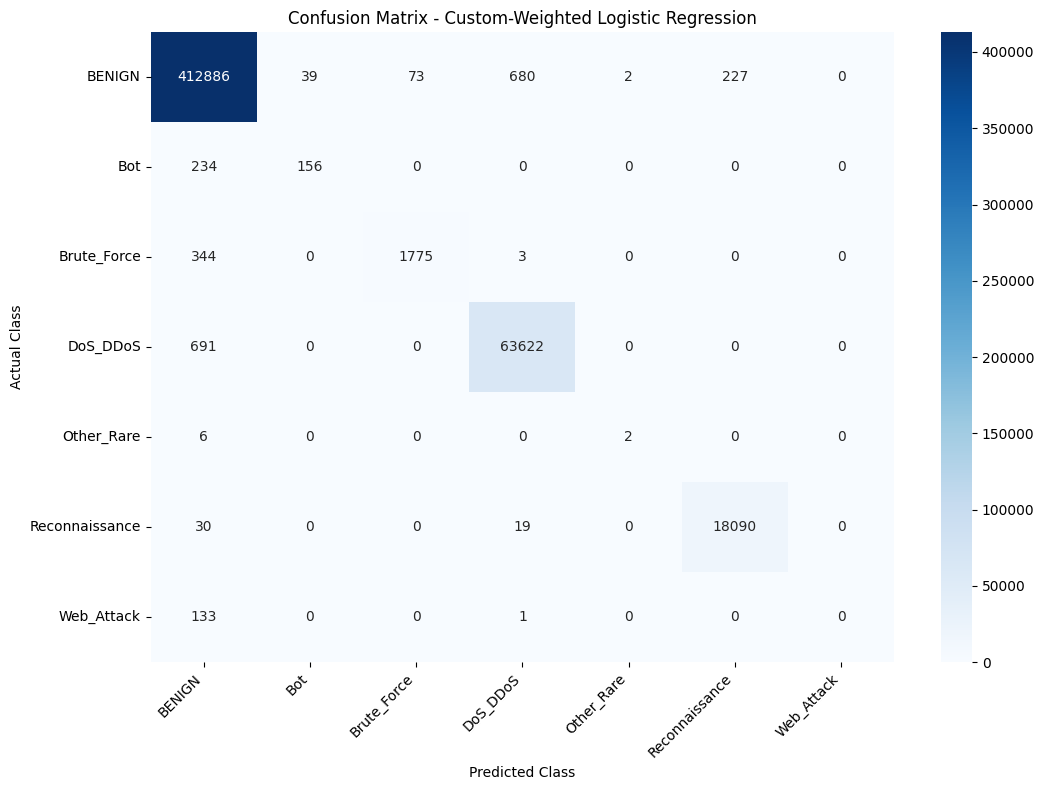

In [ ]:
# Plotting the confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred_custom,
    labels=log_reg_pipeline_custom.classes_
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=log_reg_pipeline_custom.classes_,
    yticklabels=log_reg_pipeline_custom.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "Confusion Matrix - Custom-Weighted Logistic Regression"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

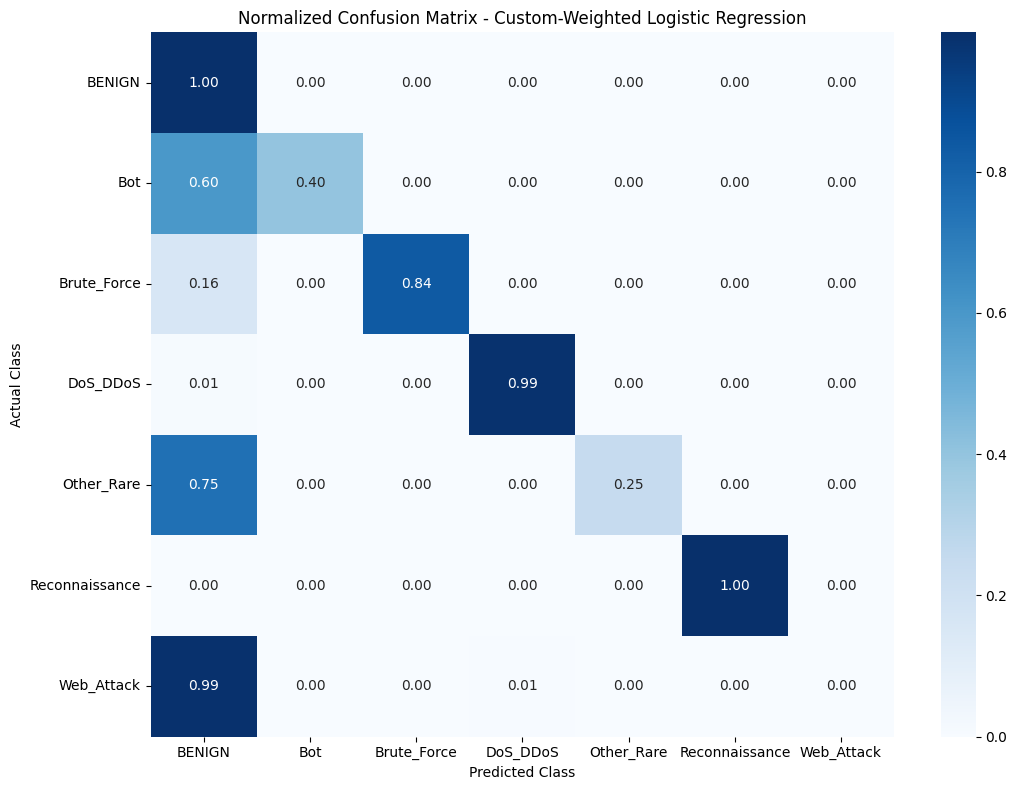

In [ ]:
# Normalised error matrix
cm_normalized = confusion_matrix(
    y_test,
    y_pred_custom,
    labels=log_reg_pipeline_custom.classes_,
    normalize="true"
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=log_reg_pipeline_custom.classes_,
    yticklabels=log_reg_pipeline_custom.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "Normalized Confusion Matrix - Custom-Weighted Logistic Regression"
)

plt.tight_layout()
plt.show()

# Port-shortcut test, tuned XGBoost / neural net / ensemble, anomaly detector

Added by Rajanya Maity after the existing work.

**Design :**
- Target : `Label_grouped`; the existing stratified 80/20 split (`X_train`, `X_test`, `y_train`, `y_test`, `random_state=42`) has been used. All tuning and all choices (for class-weight power, XGBoost/NN settings, ensemble weight, per-class thresholds, which variant is the headline) use out-of-fold (OOF) predictions on the training split, never the test set.
- OOF scores have been re-weighted to the natural class mixto prevent a capped training sample from distorting them.
- Setup A = with port (`Destination Port` + `Destination_Port_Group`). Setup B = no port information. Hyperparameters have been tuned once on B and then reused unchanged for A. So the only difference between A and B lies in the port columns.
- Setup G = `Destination_Port_Group` only, no raw port: exactly the columns used by the logistic baseline. The port-group ablation compares G with B.
- [REV2] Preprocessing (imputer, signed-log, scaler, one-hot encoder) is fitted **inside every CV fold on the training fold only**, in the hyper-parameter search, the ensemble-weight search and the threshold search. The final refits use the whole training pool and are applied to the untouched test set.
- Models have ranked on Macro-F1 and per-class precision/recall. Accuracy is shown for reference only.
- The final models have been refit on the whole training pool, with several seeds and the spread over seeds is reported.


In [ ]:
# new imports and shared settings (defined once, never reassigned below)
import xgboost as xgb
from sklearn.base import clone
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, average_precision_score

SEED = 42
USE_SAMPLING = True
TRAIN_CAP_PER_CLASS = 100_000
TUNE_CAP_PER_CLASS = 30_000
CV_FOLDS = 5
TUNE_FOLDS = 3
N_SEEDS = 3
XGB_WPOW_GRID = [0.25, 0.4, 0.5]
XGB_PARAM_GRID = [(6, 1), (10, 1), (8, 5), (10, 5)]  # (max_depth, min_child_weight)
NN_WPOW_GRID = [0.0, 0.1, 0.2, 0.3]                     # class weight = (n_max / n_class) ** power
NN_ARCH_GRID = [((256, 128), 0.3), ((512, 256, 128), 0.2)]   # (hidden layers, dropout)
ENS_W_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]            # share of XGBoost in the ensemble
THR_GRID = [0.25, 0.35, 0.5, 0.7, 1.0, 1.4, 2.0, 2.8, 4.0]   # per-class probability multipliers
MIN_OOF_GAIN = 0.003             # tuned thresholds are used only if they lift OOF Macro-F1 by at least this
ANOM_FPR_TARGET = 0.05           # share of held-out BENIGN flows the anomaly detector may flag
ANOM_FIT_ROWS = 100_000          # max BENIGN rows used to fit the anomaly detector
COLLAPSE_DROP = 0.10             # a Macro-F1 drop (B - A) larger than 0.10, here, is called a collapse
ADD_VALUE_MIN_CATCH = 0.25       # detector "adds value" if it flags this share of attacks the headline model calls BENIGN
RARE_CLASSES_MODEL = ["Other_Rare", "Web_Attack", "Bot"]
SETUP_A = "A_with_port"
SETUP_B = "B_no_port"
SETUP_G = "G_port_group_only"   # same columns as the logistic baseline: port group, no raw port
ALL_SETUPS = (SETUP_A, SETUP_B, SETUP_G)
SETUP_REF = "ref_port_group_only"   # existing logistic regression (port group, no raw port)
XGB_BASE_PARAMS = dict(objective="multi:softprob", tree_method="hist", eval_metric="mlogloss",
                       subsample=0.8, colsample_bytree=0.8, n_jobs=-1)

## The two feature setups

In [ ]:
# class order and read-only checks on the existing split
class_names_all = sorted(y_train.unique())
n_classes_all = len(class_names_all)
class_to_code = {name_cls: code_cls for code_cls, name_cls in enumerate(class_names_all)}
class_array_all = np.array(class_names_all)
assert sorted(y_test.unique()) == class_names_all
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.index.intersection(X_test.index).empty

# training pool: per-class capped sample of the existing training split (rare classes stay whole)
rng_sampling = np.random.default_rng(SEED)
idx_parts_model = []
for name_cls in class_names_all:
    idx_class_all = y_train.index[(y_train == name_cls).to_numpy()].to_numpy()
    n_take_cls = len(idx_class_all) if not USE_SAMPLING else min(len(idx_class_all), TRAIN_CAP_PER_CLASS)
    idx_parts_model.append(rng_sampling.choice(idx_class_all, size=n_take_cls, replace=False))
idx_pool = rng_sampling.permutation(np.concatenate(idx_parts_model))
y_pool_codes = y_train.loc[idx_pool].map(class_to_code).to_numpy(dtype=np.int64)

# smaller sub-pool for the hyperparameter search (positions inside the pool)
pos_tune = []
for code_cls in range(n_classes_all):
    pos_cls = np.where(y_pool_codes == code_cls)[0]
    pos_tune.append(rng_sampling.choice(pos_cls, size=min(len(pos_cls), TUNE_CAP_PER_CLASS), replace=False))
pos_tune = rng_sampling.permutation(np.concatenate(pos_tune))
y_tune_codes = y_pool_codes[pos_tune]

# weights that turn pool / tune-pool metrics back into natural-class-mix metrics
natural_counts_vec = y_train.value_counts().reindex(class_names_all).to_numpy(dtype=np.float64)
def natural_mix_weights(y_codes):
    return (natural_counts_vec / np.bincount(y_codes, minlength=n_classes_all))[y_codes]
eval_w_pool = natural_mix_weights(y_pool_codes)
eval_w_tune = natural_mix_weights(y_tune_codes)

# feature lists for the two setups
PORT_COL = "Destination Port"
assert PORT_COL not in numeric_features and "Destination_Port_Group" in categorical_features
num_cols_port = list(numeric_features) + [PORT_COL]                                     # A: raw port ...
cat_cols_port = list(categorical_features)                                              # A: ... + port group (+ Protocol)
num_cols_noport = list(numeric_features)                                                # B: no raw port
cat_cols_noport = [c_ for c_ in categorical_features if c_ != "Destination_Port_Group"]  # B: no port group
assert not [c_ for c_ in num_cols_noport + cat_cols_noport if "port" in c_.lower()]

def frame_for_setup(source_frame, with_port):
    # the existing X_* frames carry the port group but not the raw port; add it back from df by row id
    if with_port:
        return source_frame.assign(**{PORT_COL: df.loc[source_frame.index, PORT_COL]})
    return source_frame[num_cols_noport + cat_cols_noport]

def build_preproc_setup(num_cols_setup, cat_cols_setup):
    # same steps as the existing pipelines (cloned), dense output for XGBoost / NN
    return ColumnTransformer(
        transformers=[("numerical", clone(numeric_pipeline), num_cols_setup),
                      ("categorical", clone(categorical_pipeline), cat_cols_setup)],
        remainder="drop", sparse_threshold=0.0)

# preprocessing for the FINAL refits and the test set: fitted on the whole training pool only (no labels used), then applied to the test set.
# [REV2] The cross-validation does NOT use these matrices; it re-fits cloned preprocessing on every training fold (see cv_oof_probs).
frame_pool_src = X_train.loc[idx_pool]
preproc_port = build_preproc_setup(num_cols_port, cat_cols_port)
mat_pool_port = np.asarray(preproc_port.fit_transform(frame_for_setup(frame_pool_src, True)), dtype=np.float32)
mat_test_port = np.asarray(preproc_port.transform(frame_for_setup(X_test, True)), dtype=np.float32)
preproc_noport = build_preproc_setup(num_cols_noport, cat_cols_noport)
mat_pool_noport = np.asarray(preproc_noport.fit_transform(frame_for_setup(frame_pool_src, False)), dtype=np.float32)
mat_test_noport = np.asarray(preproc_noport.transform(frame_for_setup(X_test, False)), dtype=np.float32)
# [ADDED] setup G: port group, no raw port (the same columns as the logistic baseline)
num_cols_group = list(numeric_features)
cat_cols_group = list(categorical_features)
assert "Destination_Port_Group" in cat_cols_group and PORT_COL not in num_cols_group
preproc_group = build_preproc_setup(num_cols_group, cat_cols_group)
mat_pool_group = np.asarray(preproc_group.fit_transform(frame_pool_src[num_cols_group + cat_cols_group]), dtype=np.float32)
mat_test_group = np.asarray(preproc_group.transform(X_test[num_cols_group + cat_cols_group]), dtype=np.float32)
mat_pool_by_setup = {SETUP_A: mat_pool_port, SETUP_B: mat_pool_noport, SETUP_G: mat_pool_group}
mat_test_by_setup = {SETUP_A: mat_test_port, SETUP_B: mat_test_noport, SETUP_G: mat_test_group}
y_true_test = y_test.to_numpy()

print("USE_SAMPLING:", USE_SAMPLING, "| pool rows:", len(idx_pool), "| tune rows:", len(pos_tune), "| test rows:", len(X_test))
print("Matrix shapes  A:", mat_pool_port.shape, " B:", mat_pool_noport.shape, " G:", mat_pool_group.shape)
display(pd.DataFrame({"pool rows": np.bincount(y_pool_codes, minlength=n_classes_all),
                      "tune rows": np.bincount(y_tune_codes, minlength=n_classes_all),
                      "train split rows": natural_counts_vec.astype(int),
                      "test rows": y_test.value_counts().reindex(class_names_all).to_numpy()},
                     index=class_names_all))

# [REV2-ADDED] raw (un-preprocessed) pool frames and unfitted preprocessing templates for fold-safe cross-validation
frame_pool_by_setup = {SETUP_A: frame_for_setup(frame_pool_src, True),
                       SETUP_B: frame_for_setup(frame_pool_src, False),
                       SETUP_G: frame_pool_src[num_cols_group + cat_cols_group]}
preproc_template_by_setup = {SETUP_A: clone(preproc_port), SETUP_B: clone(preproc_noport), SETUP_G: clone(preproc_group)}
for k_ in ALL_SETUPS:
    assert len(frame_pool_by_setup[k_]) == len(y_pool_codes) == mat_pool_by_setup[k_].shape[0]


USE_SAMPLING: True | pool rows: 283178 | tune rows: 100623 | test rows: 499013
Matrix shapes  A: (283178, 55)  B: (283178, 38)  G: (283178, 54)


,pool rows,tune rows,train split rows,test rows
BENIGN,100000,30000,1655625,413907
Bot,1558,1558,1558,390
Brute_Force,8492,8492,8492,2122
DoS_DDoS,100000,30000,257249,64313
Other_Rare,34,34,34,8
Reconnaissance,72555,30000,72555,18139
Web_Attack,539,539,539,134


## Evaluation helpers and storing of results

In [ ]:
# storing of results: results[(model, setup)]
results = {}

def weighted_macro_f1(y_true_codes, y_pred_codes, w):
    # fast weighted Macro-F1 from a confusion matrix; also returns the per-class F1
    cm_w = np.bincount(y_true_codes * n_classes_all + y_pred_codes, weights=w,
                       minlength=n_classes_all ** 2).reshape(n_classes_all, n_classes_all)
    tp_ = np.diag(cm_w); fp_ = cm_w.sum(axis=0) - tp_; fn_ = cm_w.sum(axis=1) - tp_
    f1_ = 2 * tp_ / np.maximum(2 * tp_ + fp_ + fn_, 1e-12)
    return float(f1_.mean()), f1_

def record_multiclass(model_label, setup_label, pred_labels, extra=None):
    # per-class precision/recall/F1, Macro-F1, confusion matrix on the shared test set
    pred_arr = np.asarray(pred_labels)
    prec_, rec_, f1_, sup_ = precision_recall_fscore_support(
        y_true_test, pred_arr, labels=class_names_all, zero_division=0)
    results[(model_label, setup_label)] = {
        "kind": "multiclass",
        "macro_f1": float(f1_score(y_true_test, pred_arr, labels=class_names_all, average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(y_true_test, pred_arr)),   # reference only, not used for ranking
        "per_class": pd.DataFrame({"precision": prec_, "recall": rec_, "f1": f1_, "support": sup_}, index=class_names_all),
        "confusion": confusion_matrix(y_true_test, pred_arr, labels=class_names_all),
        "y_pred": pred_arr,
        **(extra or {}),
    }

def show_model_report(model_label, setup_label):
    res_ = results[(model_label, setup_label)]
    print(f"\n=== {model_label} | {setup_label} ===")
    print(f"Macro-F1: {res_['macro_f1']:.4f}   (accuracy, reference only: {res_['accuracy']:.4f})")
    display(res_["per_class"].round(4))

def plot_confusions(model_label):
    # colour = row-normalised (recall), numbers = flow counts
    fig_cm, axes_cm = plt.subplots(1, len(ALL_SETUPS), figsize=(10 * len(ALL_SETUPS), 7))
    for ax_cm, setup_label in zip(axes_cm, ALL_SETUPS):
        counts_cm = results[(model_label, setup_label)]["confusion"]
        norm_cm = counts_cm / np.clip(counts_cm.sum(axis=1, keepdims=True), 1, None)
        sns.heatmap(norm_cm, annot=counts_cm, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    xticklabels=class_names_all, yticklabels=class_names_all, annot_kws={"size": 8}, ax=ax_cm)
        ax_cm.set_title(f"{model_label} | {setup_label}")
        ax_cm.set_xlabel("Predicted"); ax_cm.set_ylabel("Actual")
        ax_cm.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

def class_weights_from_counts(y_codes, power):
    # weight = (n_max / n_class) ** power ; power 0 = no weighting
    counts_ = np.bincount(y_codes, minlength=n_classes_all).astype(np.float64)
    return ((counts_.max() / counts_) ** power).astype(np.float32)

## Model definitions: XGBoost and a regularised NumPy neural net
Both use class weights and early stopping on an inner 10% split of whatever they are trained on.
The net has dropout, L2, Adam and halves its learning rate whenever validation loss stops improving (best epoch is restored).
Inputs are the same preprocessed features, clipped to +/-10 for numerical safety.

In [ ]:
class MLPNumpyClassifier:
    """ReLU MLP: inverted dropout, L2 penalty, Adam, class-weighted cross-entropy, LR halving, early stopping."""
    def __init__(self, n_in, n_out, hidden=(256, 128), dropout=0.3, l2=1e-4, lr=1e-3,
                 batch_size=1024, max_epochs=40, patience=5, seed=0):
        self.dropout, self.l2, self.lr = dropout, l2, lr
        self.batch_size, self.max_epochs, self.patience = batch_size, max_epochs, patience
        self.rng = np.random.default_rng(seed)
        dims = [n_in, *hidden, n_out]
        self.W = [(self.rng.standard_normal((a, b)) * np.sqrt(2.0 / a)).astype(np.float32) for a, b in zip(dims[:-1], dims[1:])]  # He init
        self.b = [np.zeros(b, dtype=np.float32) for b in dims[1:]]
        self.history = []

    @staticmethod
    def _softmax(logits):
        z = logits - logits.max(axis=1, keepdims=True)
        e = np.exp(z)
        return e / e.sum(axis=1, keepdims=True)

    def _forward(self, X, train):
        acts, pre, masks = [X], [], []
        a = X
        for k in range(len(self.W) - 1):
            z = a @ self.W[k] + self.b[k]
            pre.append(z)
            a = np.maximum(z, 0)
            if train and self.dropout > 0:
                m = (self.rng.random(a.shape, dtype=np.float32) >= self.dropout).astype(np.float32) / (1.0 - self.dropout)
                a = a * m
                masks.append(m)
            acts.append(a)
        return a @ self.W[-1] + self.b[-1], acts, pre, masks

    def _weighted_loss(self, X, y, sw):
        total = 0.0
        for s in range(0, len(X), 50_000):
            p = self._softmax(self._forward(X[s:s + 50_000], False)[0])
            total += float((sw[s:s + 50_000] * -np.log(p[np.arange(len(p)), y[s:s + 50_000]] + 1e-12)).sum())
        return total / float(sw.sum())

    def fit(self, X, y, class_w, X_val, y_val):
        sw_all, sw_val = class_w[y], class_w[y_val]
        params = self.W + self.b                       # same array objects, updated in place
        m1 = [np.zeros_like(p) for p in params]
        m2 = [np.zeros_like(p) for p in params]
        n, n_layers, step, lr_now = len(X), len(self.W), 0, self.lr
        best_loss, best_params, bad_epochs = np.inf, None, 0
        for epoch in range(1, self.max_epochs + 1):
            order = self.rng.permutation(n)
            for s in range(0, n, self.batch_size):
                ids = order[s:s + self.batch_size]
                xb, yb, wb = X[ids], y[ids], sw_all[ids]
                logits, acts, pre, masks = self._forward(xb, True)
                delta = self._softmax(logits)
                delta[np.arange(len(yb)), yb] -= 1.0
                delta *= (wb / wb.sum())[:, None]      # gradient of the weighted mean cross-entropy
                gW, gb = [None] * n_layers, [None] * n_layers
                for k in range(n_layers - 1, -1, -1):
                    gW[k] = acts[k].T @ delta + self.l2 * self.W[k]
                    gb[k] = delta.sum(axis=0)
                    if k > 0:
                        delta = delta @ self.W[k].T
                        if self.dropout > 0:
                            delta = delta * masks[k - 1]
                        delta = delta * (pre[k - 1] > 0)
                step += 1
                for j, (p, g) in enumerate(zip(params, gW + gb)):
                    m1[j] = 0.9 * m1[j] + 0.1 * g
                    m2[j] = 0.999 * m2[j] + 0.001 * g * g
                    p -= lr_now * (m1[j] / (1 - 0.9 ** step)) / (np.sqrt(m2[j] / (1 - 0.999 ** step)) + 1e-8)
            val_loss = self._weighted_loss(X_val, y_val, sw_val)
            self.history.append(val_loss)
            if val_loss < best_loss - 1e-4:
                best_loss, best_params, bad_epochs = val_loss, [p.copy() for p in params], 0
            else:
                bad_epochs += 1
                lr_now *= 0.5                           # learning-rate schedule: halve on plateau
                if bad_epochs >= self.patience:
                    break
        for p, bp in zip(params, best_params):          # restore the best epoch
            p[...] = bp
        self.best_epoch = int(np.argmin(self.history)) + 1
        return self

    def predict_proba(self, X):
        return np.concatenate([self._softmax(self._forward(X[s:s + 50_000], False)[0]) for s in range(0, len(X), 50_000)])

NN_INPUT_CLIP = 10.0
def clip_nn_input(mat):
    return np.clip(mat, -NN_INPUT_CLIP, NN_INPUT_CLIP)

class ProbaWrap:
    # [CHANGED] tiny wrapper so XGBoost and the NN expose the same .proba(X); holds the model itself (no lambda), so it can be pickled / joblib-dumped
    def __init__(self, model, clip=False):
        self.model, self.clip = model, clip
    def proba(self, X_in):
        return self.model.predict_proba(clip_nn_input(X_in) if self.clip else X_in)

def fit_xgb_recipe(mat_tr, y_tr, cfg, seed, n_estimators=None):
    # n_estimators=None: early stopping on an inner 10% split; otherwise a fixed number of rounds on all rows
    assert len(np.unique(y_tr)) == n_classes_all
    wvec = class_weights_from_counts(y_tr, cfg["wpow"])
    params = dict(XGB_BASE_PARAMS, max_depth=cfg["max_depth"], min_child_weight=cfg["mcw"],
                  learning_rate=cfg["lr"], random_state=seed)
    if n_estimators is None:
        ix_in, ix_es = train_test_split(np.arange(len(y_tr)), test_size=0.1, stratify=y_tr, random_state=seed)
        model_x = xgb.XGBClassifier(n_estimators=400, early_stopping_rounds=20, **params)
        model_x.fit(mat_tr[ix_in], y_tr[ix_in], sample_weight=wvec[y_tr[ix_in]],
                    eval_set=[(mat_tr[ix_es], y_tr[ix_es])], sample_weight_eval_set=[wvec[y_tr[ix_es]]], verbose=False)
        n_used = int(model_x.best_iteration) + 1
    else:
        model_x = xgb.XGBClassifier(n_estimators=n_estimators, **params)
        model_x.fit(mat_tr, y_tr, sample_weight=wvec[y_tr], verbose=False)
        n_used = n_estimators
    return ProbaWrap(model_x), n_used

def fit_nn_recipe(mat_tr, y_tr, cfg, seed):
    wvec = class_weights_from_counts(y_tr, cfg["wpow"])
    ix_in, ix_es = train_test_split(np.arange(len(y_tr)), test_size=0.1, stratify=y_tr, random_state=seed)
    model_n = MLPNumpyClassifier(n_in=mat_tr.shape[1], n_out=n_classes_all, hidden=cfg["hidden"],
                                 dropout=cfg["dropout"], seed=seed)
    model_n.fit(clip_nn_input(mat_tr[ix_in]), y_tr[ix_in], wvec, clip_nn_input(mat_tr[ix_es]), y_tr[ix_es])
    return ProbaWrap(model_n, clip=True), model_n.best_epoch

def cv_oof_probs(fit_fn, raw_frame, preproc_template, y_codes, n_splits):
    # [REV2-CHANGED] stratified out-of-fold class probabilities with FOLD-SAFE preprocessing:
    # imputer medians, scaler quantiles and one-hot categories are learned on the training fold only,
    # then applied to the held-out fold. raw_frame is the un-preprocessed frame, row-aligned with y_codes.
    assert len(raw_frame) == len(y_codes)
    oof_ = np.zeros((len(y_codes), n_classes_all), dtype=np.float32)
    infos_ = []
    for ix_tr, ix_te in StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(np.zeros(len(y_codes)), y_codes):
        pre_f = clone(preproc_template)
        mat_tr = np.asarray(pre_f.fit_transform(raw_frame.iloc[ix_tr]), dtype=np.float32)
        mat_te = np.asarray(pre_f.transform(raw_frame.iloc[ix_te]), dtype=np.float32)
        wrap_f, info_f = fit_fn(mat_tr, y_codes[ix_tr], SEED)
        oof_[ix_te] = wrap_f.proba(mat_te)
        infos_.append(info_f)
    return oof_, infos_

## Hyperparameter search (on setup B, out-of-fold, natural-mix Macro-F1)

Stage 1 picks the class-weight power, stage 2 the tree depth / `min_child_weight`. The neural net is tuned the same way (weight power, then architecture). The most appropriate settings used for setup B remain unchanged. [REV2] Every CV fold fits its own preprocessing on its training part only.

In [ ]:
frame_tune_noport = frame_pool_by_setup[SETUP_B].iloc[pos_tune]      # search is run on setup B, the strict setup ([REV2] raw frame: preprocessing is fitted inside each fold)
search_rows = []

def score_cfg(model_kind, cfg_try):
    fit_fn = (lambda m_, y_, s_: fit_xgb_recipe(m_, y_, cfg_try, s_)) if model_kind == "XGBoost" \
             else (lambda m_, y_, s_: fit_nn_recipe(m_, y_, cfg_try, s_))
    t0_s = time.time()
    oof_s, info_unused = cv_oof_probs(fit_fn, frame_tune_noport, preproc_template_by_setup[SETUP_B], y_tune_codes, TUNE_FOLDS)
    f1_mean, f1_cls = weighted_macro_f1(y_tune_codes, oof_s.argmax(axis=1), eval_w_tune)
    search_rows.append({"model": model_kind, **{k_: str(v_) for k_, v_ in cfg_try.items()},
                        "OOF Macro-F1": f1_mean, **{f"F1 {name_cls}": f1_cls[class_to_code[name_cls]] for name_cls in RARE_CLASSES_MODEL},
                        "min": (time.time() - t0_s) / 60})
    print(f"{model_kind} {cfg_try} -> OOF Macro-F1 {f1_mean:.4f} ({(time.time() - t0_s) / 60:.1f} min)")
    return f1_mean

# XGBoost stage 1: class-weight power
xgb_cfg_base = dict(wpow=0.5, max_depth=8, mcw=1, lr=0.1)
scores_wpow = {w_: score_cfg("XGBoost", dict(xgb_cfg_base, wpow=w_)) for w_ in XGB_WPOW_GRID}
xgb_best_wpow = max(scores_wpow, key=scores_wpow.get)
# XGBoost stage 2: depth / min_child_weight at the best weight power
xgb_cfg_best = dict(xgb_cfg_base, wpow=xgb_best_wpow); xgb_best_score = scores_wpow[xgb_best_wpow]
for depth_, mcw_ in XGB_PARAM_GRID:
    cfg_try = dict(xgb_cfg_base, wpow=xgb_best_wpow, max_depth=depth_, mcw=mcw_)
    s_try = score_cfg("XGBoost", cfg_try)
    if s_try > xgb_best_score:
        xgb_best_score, xgb_cfg_best = s_try, cfg_try
print("\nBest XGBoost settings:", xgb_cfg_best, f"(OOF Macro-F1 {xgb_best_score:.4f})")

# neural net stage 1: class-weight power; stage 2: architecture
nn_cfg_base = dict(wpow=0.2, hidden=NN_ARCH_GRID[0][0], dropout=NN_ARCH_GRID[0][1])
scores_nn_wpow = {w_: score_cfg("Neural net", dict(nn_cfg_base, wpow=w_)) for w_ in NN_WPOW_GRID}
nn_best_wpow = max(scores_nn_wpow, key=scores_nn_wpow.get)
nn_cfg_best = dict(nn_cfg_base, wpow=nn_best_wpow); nn_best_score = scores_nn_wpow[nn_best_wpow]
for hidden_, drop_ in NN_ARCH_GRID[1:]:
    cfg_try = dict(nn_cfg_base, wpow=nn_best_wpow, hidden=hidden_, dropout=drop_)
    s_try = score_cfg("Neural net", cfg_try)
    if s_try > nn_best_score:
        nn_best_score, nn_cfg_best = s_try, cfg_try
print("Best neural net settings:", nn_cfg_best, f"(OOF Macro-F1 {nn_best_score:.4f})")
display(pd.DataFrame(search_rows).round(4))

XGBoost {'wpow': 0.25, 'max_depth': 8, 'mcw': 1, 'lr': 0.1} -> OOF Macro-F1 0.7580 (0.4 min)
XGBoost {'wpow': 0.4, 'max_depth': 8, 'mcw': 1, 'lr': 0.1} -> OOF Macro-F1 0.7579 (0.3 min)
XGBoost {'wpow': 0.5, 'max_depth': 8, 'mcw': 1, 'lr': 0.1} -> OOF Macro-F1 0.7315 (0.3 min)
XGBoost {'wpow': 0.25, 'max_depth': 6, 'mcw': 1, 'lr': 0.1} -> OOF Macro-F1 0.7521 (0.5 min)
XGBoost {'wpow': 0.25, 'max_depth': 10, 'mcw': 1, 'lr': 0.1} -> OOF Macro-F1 0.7555 (0.4 min)
XGBoost {'wpow': 0.25, 'max_depth': 8, 'mcw': 5, 'lr': 0.1} -> OOF Macro-F1 0.7340 (0.4 min)
XGBoost {'wpow': 0.25, 'max_depth': 10, 'mcw': 5, 'lr': 0.1} -> OOF Macro-F1 0.7357 (0.4 min)

Best XGBoost settings: {'wpow': 0.25, 'max_depth': 8, 'mcw': 1, 'lr': 0.1} (OOF Macro-F1 0.7580)
Neural net {'wpow': 0.0, 'hidden': (256, 128), 'dropout': 0.3} -> OOF Macro-F1 0.5905 (0.9 min)
Neural net {'wpow': 0.1, 'hidden': (256, 128), 'dropout': 0.3} -> OOF Macro-F1 0.5483 (0.9 min)
Neural net {'wpow': 0.2, 'hidden': (256, 128), 'dropout': 0

,model,wpow,max_depth,mcw,lr,OOF Macro-F1,F1 Other_Rare,F1 Web_Attack,F1 Bot,min,hidden,dropout
0,XGBoost,0.25,8,1,0.1,0.7580,0.4379,0.3519,0.6270,0.3659,NaN,NaN
1,XGBoost,0.4,8,1,0.1,0.7579,0.4379,0.3490,0.6341,0.3422,NaN,NaN
2,XGBoost,0.5,8,1,0.1,0.7315,0.3052,0.3358,0.6208,0.3482,NaN,NaN
3,XGBoost,0.25,6,1,0.1,0.7521,0.4379,0.3234,0.6200,0.4556,NaN,NaN
4,XGBoost,0.25,10,1,0.1,0.7555,0.4241,0.3397,0.6343,0.3588,NaN,NaN
5,XGBoost,0.25,8,5,0.1,0.7340,0.2952,0.3281,0.6341,0.4107,NaN,NaN
6,XGBoost,0.25,10,5,0.1,0.7357,0.2952,0.3430,0.6343,0.4052,NaN,NaN
7,Neural net,0.0,NaN,NaN,NaN,0.5905,0.3810,0.0000,0.1747,0.8619,"(256, 128)",0.3
8,Neural net,0.1,NaN,NaN,NaN,0.5483,0.1388,0.0000,0.1351,0.8560,"(256, 128)",0.3
9,Neural net,0.2,NaN,NaN,NaN,0.5474,0.1038,0.0000,0.1250,0.8217,"(256, 128)",0.3


## Final Models

For each setup:
(1) OOF probabilities on the training pool (preprocessing fitted per fold, [REV2]) give an ensemble weight and per-class decision thresholds;
(2) the final XGBoost and neural net are refit on the whole pool with `N_SEEDS` seeds and their probabilities averaged;
(3) four variants are scored once on the shared test set: XGBoost, Neural net, Ensemble, Ensemble + class thresholds.
Nothing is chosen on the test set.

In [ ]:
def tune_class_scales(prob, y_codes, w):
    # coordinate ascent on per-class probability multipliers, maximising natural-mix Macro-F1 on OOF predictions
    scales = np.ones(n_classes_all, dtype=np.float32)
    best_f1 = weighted_macro_f1(y_codes, (prob * scales).argmax(axis=1), w)[0]
    for pass_i in range(3):
        for k_ in range(n_classes_all):
            for cand_ in THR_GRID:
                trial = scales.copy(); trial[k_] = cand_
                f1_try = weighted_macro_f1(y_codes, (prob * trial).argmax(axis=1), w)[0]
                if f1_try > best_f1 + 1e-4:
                    best_f1, scales = f1_try, trial
    return scales, best_f1

stage_store = {}
for setup_label in ALL_SETUPS:
    t0_setup = time.time()
    mat_pool_s, mat_test_s = mat_pool_by_setup[setup_label], mat_test_by_setup[setup_label]
    print(f"\n##### {setup_label}: out-of-fold predictions ({CV_FOLDS} folds)")
    oof_x, infos_x = cv_oof_probs(lambda m_, y_, s_: fit_xgb_recipe(m_, y_, xgb_cfg_best, s_), frame_pool_by_setup[setup_label], preproc_template_by_setup[setup_label], y_pool_codes, CV_FOLDS)
    oof_n, infos_n = cv_oof_probs(lambda m_, y_, s_: fit_nn_recipe(m_, y_, nn_cfg_best, s_), frame_pool_by_setup[setup_label], preproc_template_by_setup[setup_label], y_pool_codes, CV_FOLDS)
    n_rounds_final = int(round(1.1 * np.mean(infos_x)))          # rounds for the full-pool refit
    oof_f1 = {"XGBoost": weighted_macro_f1(y_pool_codes, oof_x.argmax(axis=1), eval_w_pool)[0],
              "Neural net": weighted_macro_f1(y_pool_codes, oof_n.argmax(axis=1), eval_w_pool)[0]}

    # ensemble weight chosen on OOF
    ens_scores = {w_: weighted_macro_f1(y_pool_codes, (w_ * oof_x + (1 - w_) * oof_n).argmax(axis=1), eval_w_pool)[0] for w_ in ENS_W_GRID}
    ens_w_best = max(ens_scores, key=ens_scores.get)
    oof_ens = ens_w_best * oof_x + (1 - ens_w_best) * oof_n
    oof_f1["Ensemble"] = ens_scores[ens_w_best]
    # per-class thresholds chosen on OOF
    scales_best, oof_f1["Ensemble + class thresholds"] = tune_class_scales(oof_ens, y_pool_codes, eval_w_pool)
    print("OOF Macro-F1:", {k_: round(v_, 4) for k_, v_ in oof_f1.items()}, "| XGBoost weight in ensemble:", ens_w_best)
    print("class multipliers:", {k_: float(round(v_, 2)) for k_, v_ in zip(class_names_all, scales_best)}, "| refit rounds:", n_rounds_final)

    # final refits on the whole pool, several seeds
    print(f"##### {setup_label}: final refits ({N_SEEDS} seeds)")
    probs_x_seeds, probs_n_seeds = [], []
    wraps_x_seeds, wraps_n_seeds = [], []      # [ADDED] keep every seed's fitted model (needed for the export)
    for k_seed in range(N_SEEDS):
        wrap_x, rounds_unused = fit_xgb_recipe(mat_pool_s, y_pool_codes, xgb_cfg_best, SEED + k_seed, n_estimators=n_rounds_final)
        probs_x_seeds.append(wrap_x.proba(mat_test_s)); wraps_x_seeds.append(wrap_x)
        wrap_n, epoch_unused = fit_nn_recipe(mat_pool_s, y_pool_codes, nn_cfg_best, SEED + k_seed)
        probs_n_seeds.append(wrap_n.proba(mat_test_s)); wraps_n_seeds.append(wrap_n)
        print(f"  seed {SEED + k_seed} done")
    prob_x_test, prob_n_test = np.mean(probs_x_seeds, axis=0), np.mean(probs_n_seeds, axis=0)
    prob_ens_test = ens_w_best * prob_x_test + (1 - ens_w_best) * prob_n_test

    seed_f1_x = [f1_score(y_true_test, class_array_all[p_.argmax(axis=1)], average="macro") for p_ in probs_x_seeds]
    seed_f1_n = [f1_score(y_true_test, class_array_all[p_.argmax(axis=1)], average="macro") for p_ in probs_n_seeds]
    record_multiclass("XGBoost", setup_label, class_array_all[prob_x_test.argmax(axis=1)],
                      {"oof_macro_f1": oof_f1["XGBoost"], "seed_macro_f1": seed_f1_x})
    record_multiclass("Neural net", setup_label, class_array_all[prob_n_test.argmax(axis=1)],
                      {"oof_macro_f1": oof_f1["Neural net"], "seed_macro_f1": seed_f1_n})
    record_multiclass("Ensemble", setup_label, class_array_all[prob_ens_test.argmax(axis=1)],
                      {"oof_macro_f1": oof_f1["Ensemble"], "ens_weight_xgb": ens_w_best})
    record_multiclass("Ensemble + class thresholds", setup_label, class_array_all[(prob_ens_test * scales_best).argmax(axis=1)],
                      {"oof_macro_f1": oof_f1["Ensemble + class thresholds"], "class_multipliers": dict(zip(class_names_all, scales_best))})
    stage_store[setup_label] = {"oof_ens": oof_ens, "scales": scales_best, "ens_w": ens_w_best, "n_rounds": n_rounds_final,
                                "xgb_models": [w_.model for w_ in wraps_x_seeds], "nn_models": [w_.model for w_ in wraps_n_seeds]}
    print(f"{setup_label} finished in {(time.time() - t0_setup) / 60:.1f} min")


##### A_with_port: out-of-fold predictions (5 folds)
OOF Macro-F1: {'XGBoost': 0.8505, 'Neural net': 0.7184, 'Ensemble': 0.8523, 'Ensemble + class thresholds': 0.8683} | XGBoost weight in ensemble: 0.75
class multipliers: {'BENIGN': 2.0, 'Bot': 1.0, 'Brute_Force': 0.5, 'DoS_DDoS': 1.0, 'Other_Rare': 1.399999976158142, 'Reconnaissance': 1.0, 'Web_Attack': 1.0} | refit rounds: 107
##### A_with_port: final refits (3 seeds)
  seed 42 done
  seed 43 done
  seed 44 done
A_with_port finished in 9.7 min

##### B_no_port: out-of-fold predictions (5 folds)
OOF Macro-F1: {'XGBoost': 0.8015, 'Neural net': 0.6815, 'Ensemble': 0.8244, 'Ensemble + class thresholds': 0.8414} | XGBoost weight in ensemble: 0.75
class multipliers: {'BENIGN': 2.0, 'Bot': 0.5, 'Brute_Force': 0.5, 'DoS_DDoS': 1.0, 'Other_Rare': 2.0, 'Reconnaissance': 1.0, 'Web_Attack': 1.0} | refit rounds: 117
##### B_no_port: final refits (3 seeds)
  seed 42 done
  seed 43 done
  seed 44 done
B_no_port finished in 10.8 min

##### G_port_g


=== XGBoost | A_with_port ===
Macro-F1: 0.8416   (accuracy, reference only: 0.9979)


,precision,recall,f1,support
BENIGN,0.9999,0.9979,0.9989,413907
Bot,0.6516,0.9974,0.7882,390
Brute_Force,0.8995,0.9571,0.9274,2122
DoS_DDoS,0.9970,0.9998,0.9984,64313
Other_Rare,0.7500,0.7500,0.7500,8
Reconnaissance,0.9891,0.9993,0.9942,18139
Web_Attack,0.3282,0.6418,0.4343,134



=== XGBoost | B_no_port ===
Macro-F1: 0.8202   (accuracy, reference only: 0.9974)


,precision,recall,f1,support
BENIGN,0.9999,0.9974,0.9986,413907
Bot,0.5896,0.9872,0.7383,390
Brute_Force,0.8876,0.9566,0.9208,2122
DoS_DDoS,0.9956,0.9997,0.9977,64313
Other_Rare,0.8333,0.6250,0.7143,8
Reconnaissance,0.9891,0.9993,0.9942,18139
Web_Attack,0.2712,0.6194,0.3773,134



=== XGBoost | G_port_group_only ===
Macro-F1: 0.8441   (accuracy, reference only: 0.9978)


,precision,recall,f1,support
BENIGN,0.9999,0.9978,0.9989,413907
Bot,0.6107,0.9974,0.7575,390
Brute_Force,0.9000,0.9538,0.9261,2122
DoS_DDoS,0.9969,0.9998,0.9984,64313
Other_Rare,0.8571,0.7500,0.8000,8
Reconnaissance,0.9890,0.9993,0.9941,18139
Web_Attack,0.3258,0.6493,0.4339,134


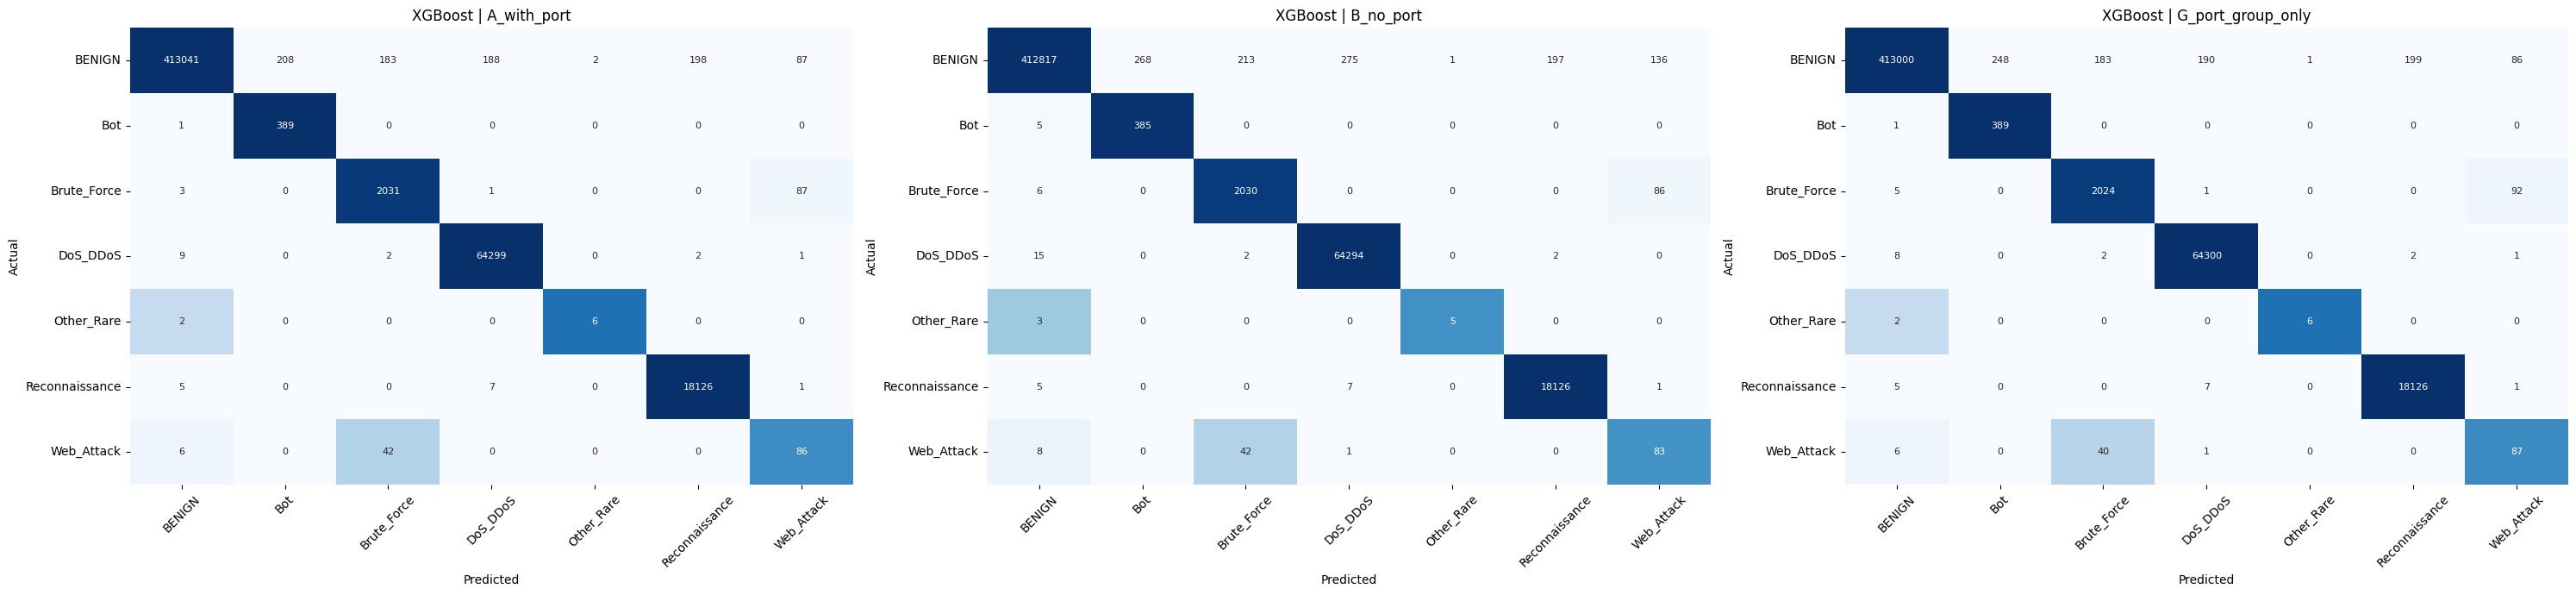


=== Neural net | A_with_port ===
Macro-F1: 0.7388   (accuracy, reference only: 0.9963)


,precision,recall,f1,support
BENIGN,0.9996,0.9963,0.9979,413907
Bot,0.5223,0.6897,0.5945,390
Brute_Force,0.7828,0.9953,0.8763,2122
DoS_DDoS,0.9901,0.9995,0.9948,64313
Other_Rare,0.8333,0.6250,0.7143,8
Reconnaissance,0.9883,0.9992,0.9937,18139
Web_Attack,0.0000,0.0000,0.0000,134



=== Neural net | B_no_port ===
Macro-F1: 0.6628   (accuracy, reference only: 0.9945)


,precision,recall,f1,support
BENIGN,0.9989,0.9947,0.9968,413907
Bot,0.5096,0.8205,0.6287,390
Brute_Force,0.7624,0.9599,0.8498,2122
DoS_DDoS,0.9823,0.9958,0.9890,64313
Other_Rare,0.3333,0.1250,0.1818,8
Reconnaissance,0.9882,0.9991,0.9936,18139
Web_Attack,0.0000,0.0000,0.0000,134



=== Neural net | G_port_group_only ===
Macro-F1: 0.7227   (accuracy, reference only: 0.9961)


,precision,recall,f1,support
BENIGN,0.9995,0.9961,0.9978,413907
Bot,0.5320,0.6615,0.5897,390
Brute_Force,0.7689,0.9958,0.8678,2122
DoS_DDoS,0.9893,0.9994,0.9944,64313
Other_Rare,0.8000,0.5000,0.6154,8
Reconnaissance,0.9882,0.9991,0.9936,18139
Web_Attack,0.0000,0.0000,0.0000,134


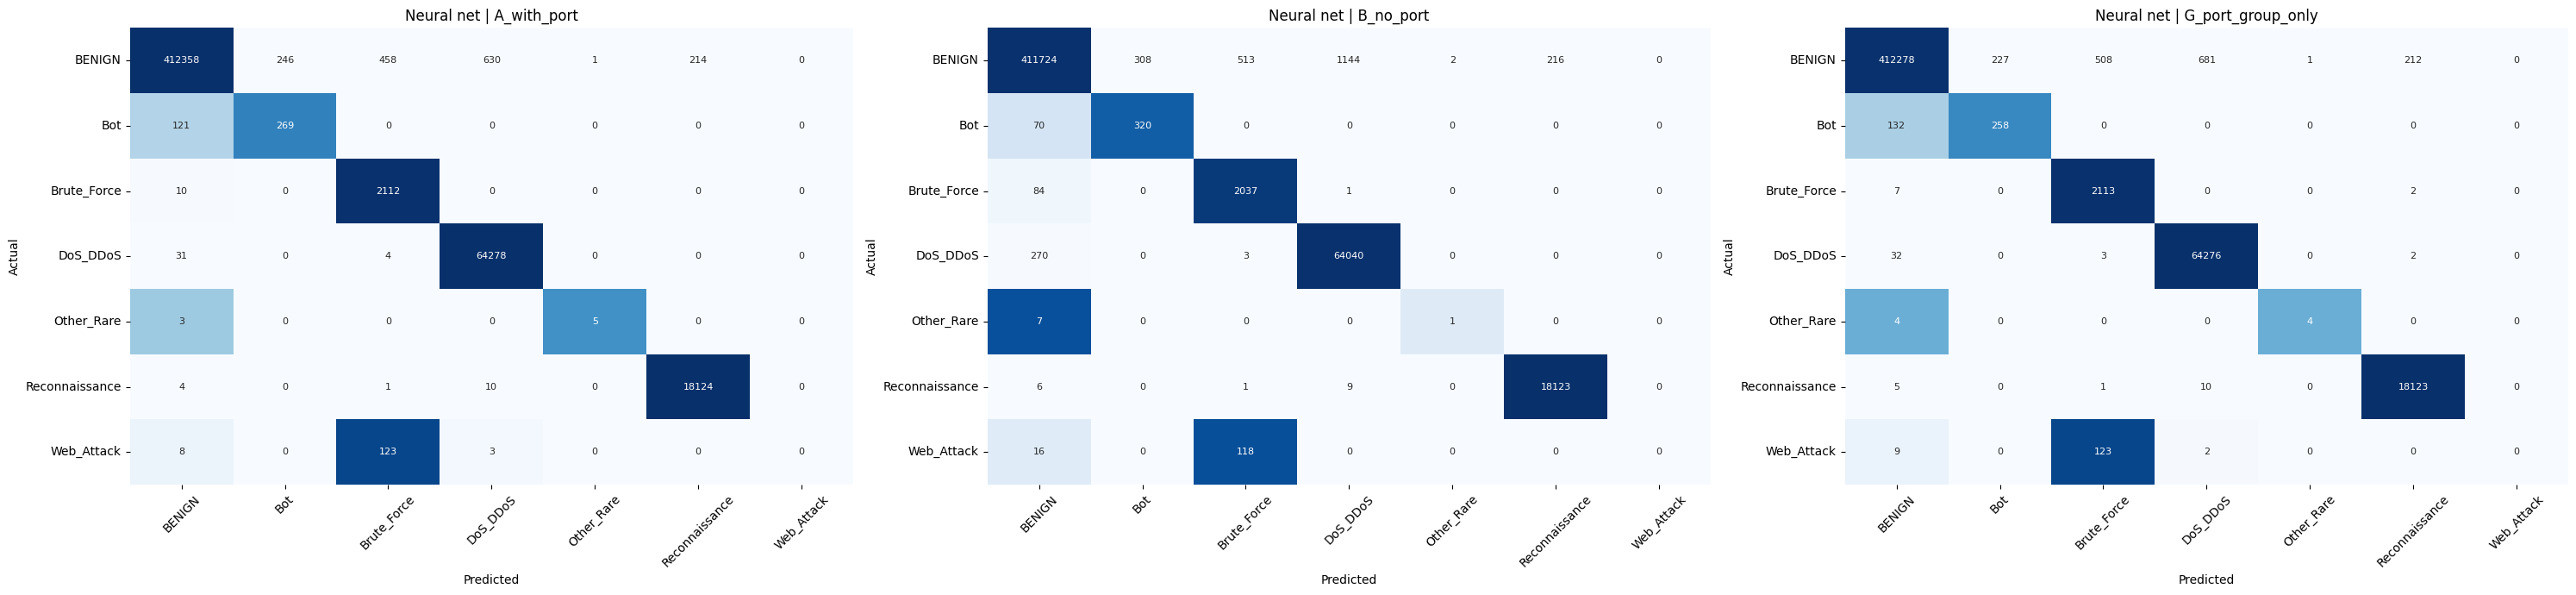


=== Ensemble | A_with_port ===
Macro-F1: 0.8512   (accuracy, reference only: 0.9980)


,precision,recall,f1,support
BENIGN,0.9999,0.9980,0.9990,413907
Bot,0.6638,0.9974,0.7971,390
Brute_Force,0.8952,0.9656,0.9290,2122
DoS_DDoS,0.9971,0.9998,0.9984,64313
Other_Rare,0.8571,0.7500,0.8000,8
Reconnaissance,0.9892,0.9993,0.9942,18139
Web_Attack,0.3545,0.5821,0.4407,134



=== Ensemble | B_no_port ===
Macro-F1: 0.8343   (accuracy, reference only: 0.9975)


,precision,recall,f1,support
BENIGN,0.9999,0.9975,0.9987,413907
Bot,0.6006,0.9872,0.7468,390
Brute_Force,0.8825,0.9623,0.9206,2122
DoS_DDoS,0.9954,0.9997,0.9975,64313
Other_Rare,1.0000,0.6250,0.7692,8
Reconnaissance,0.9891,0.9993,0.9942,18139
Web_Attack,0.3222,0.5746,0.4129,134



=== Ensemble | G_port_group_only ===
Macro-F1: 0.8441   (accuracy, reference only: 0.9978)


,precision,recall,f1,support
BENIGN,0.9999,0.9978,0.9989,413907
Bot,0.6107,0.9974,0.7575,390
Brute_Force,0.9000,0.9538,0.9261,2122
DoS_DDoS,0.9969,0.9998,0.9984,64313
Other_Rare,0.8571,0.7500,0.8000,8
Reconnaissance,0.9890,0.9993,0.9941,18139
Web_Attack,0.3258,0.6493,0.4339,134


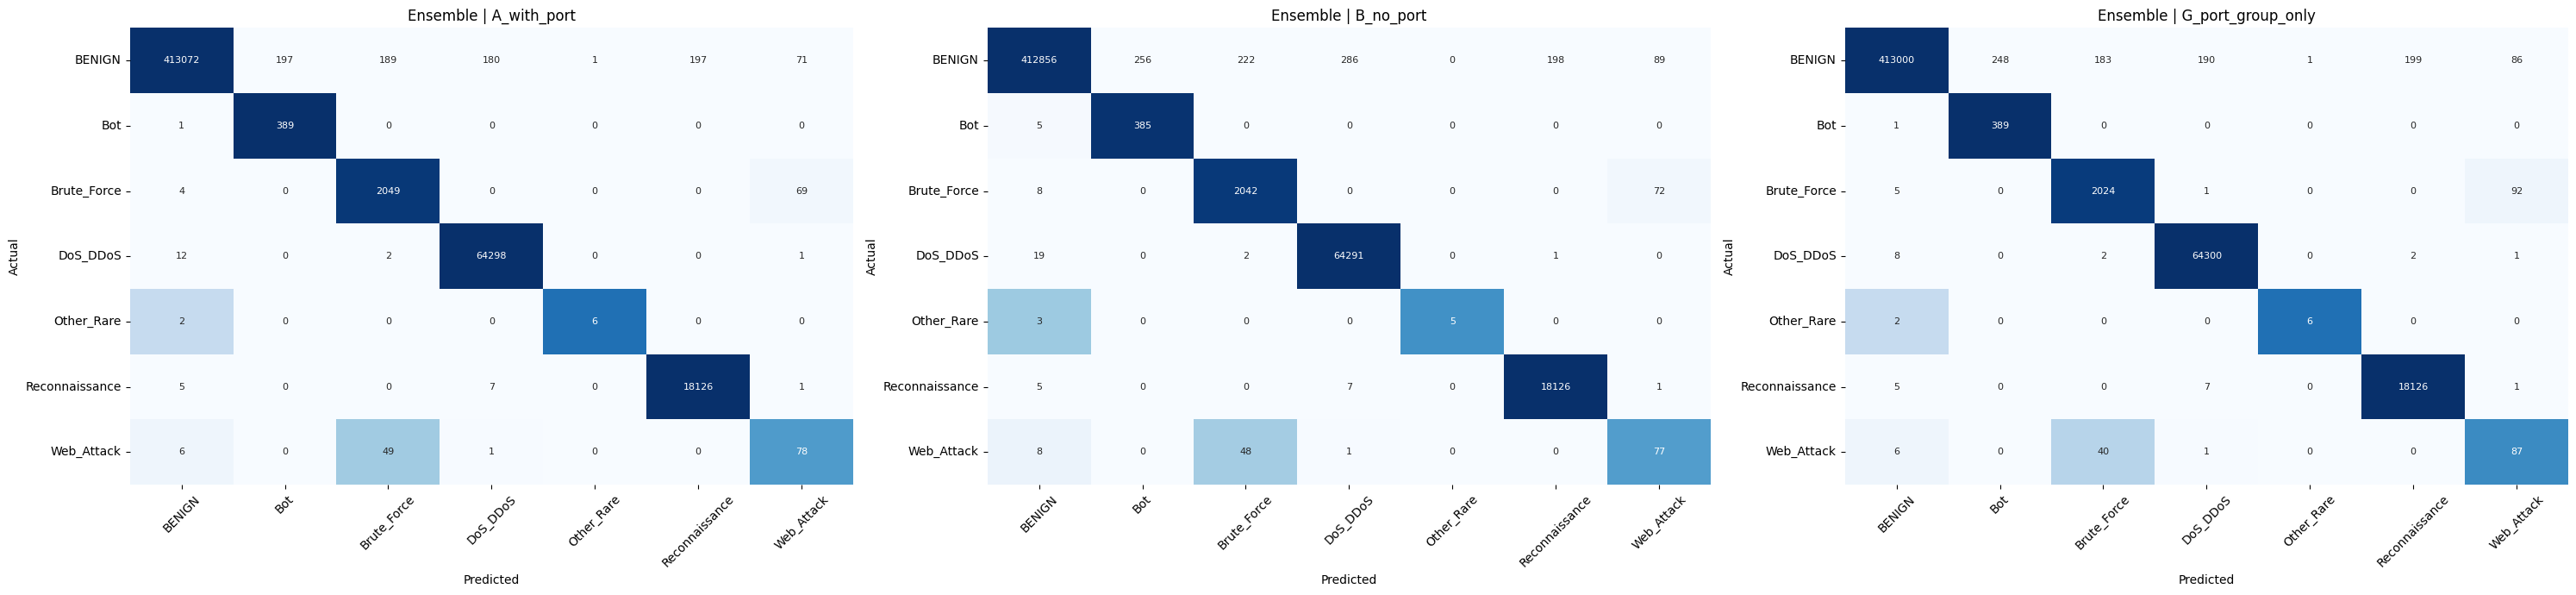


=== Ensemble + class thresholds | A_with_port ===
Macro-F1: 0.8577   (accuracy, reference only: 0.9982)


,precision,recall,f1,support
BENIGN,0.9999,0.9984,0.9991,413907
Bot,0.6783,0.9949,0.8067,390
Brute_Force,0.9661,0.9265,0.9459,2122
DoS_DDoS,0.9978,0.9996,0.9987,64313
Other_Rare,0.8571,0.7500,0.8000,8
Reconnaissance,0.9892,0.9992,0.9942,18139
Web_Attack,0.3223,0.7985,0.4592,134



=== Ensemble + class thresholds | B_no_port ===
Macro-F1: 0.8462   (accuracy, reference only: 0.9979)


,precision,recall,f1,support
BENIGN,0.9996,0.9983,0.9989,413907
Bot,0.6845,0.9513,0.7961,390
Brute_Force,0.9630,0.8963,0.9285,2122
DoS_DDoS,0.9969,0.9993,0.9981,64313
Other_Rare,1.0000,0.6250,0.7692,8
Reconnaissance,0.9892,0.9992,0.9942,18139
Web_Attack,0.3106,0.7463,0.4386,134



=== Ensemble + class thresholds | G_port_group_only ===
Macro-F1: 0.8470   (accuracy, reference only: 0.9983)


,precision,recall,f1,support
BENIGN,0.9997,0.9987,0.9992,413907
Bot,0.7243,0.9231,0.8117,390
Brute_Force,0.9585,0.9359,0.9471,2122
DoS_DDoS,0.9984,0.9991,0.9988,64313
Other_Rare,0.8333,0.6250,0.7143,8
Reconnaissance,0.9890,0.9992,0.9941,18139
Web_Attack,0.3415,0.7239,0.4641,134


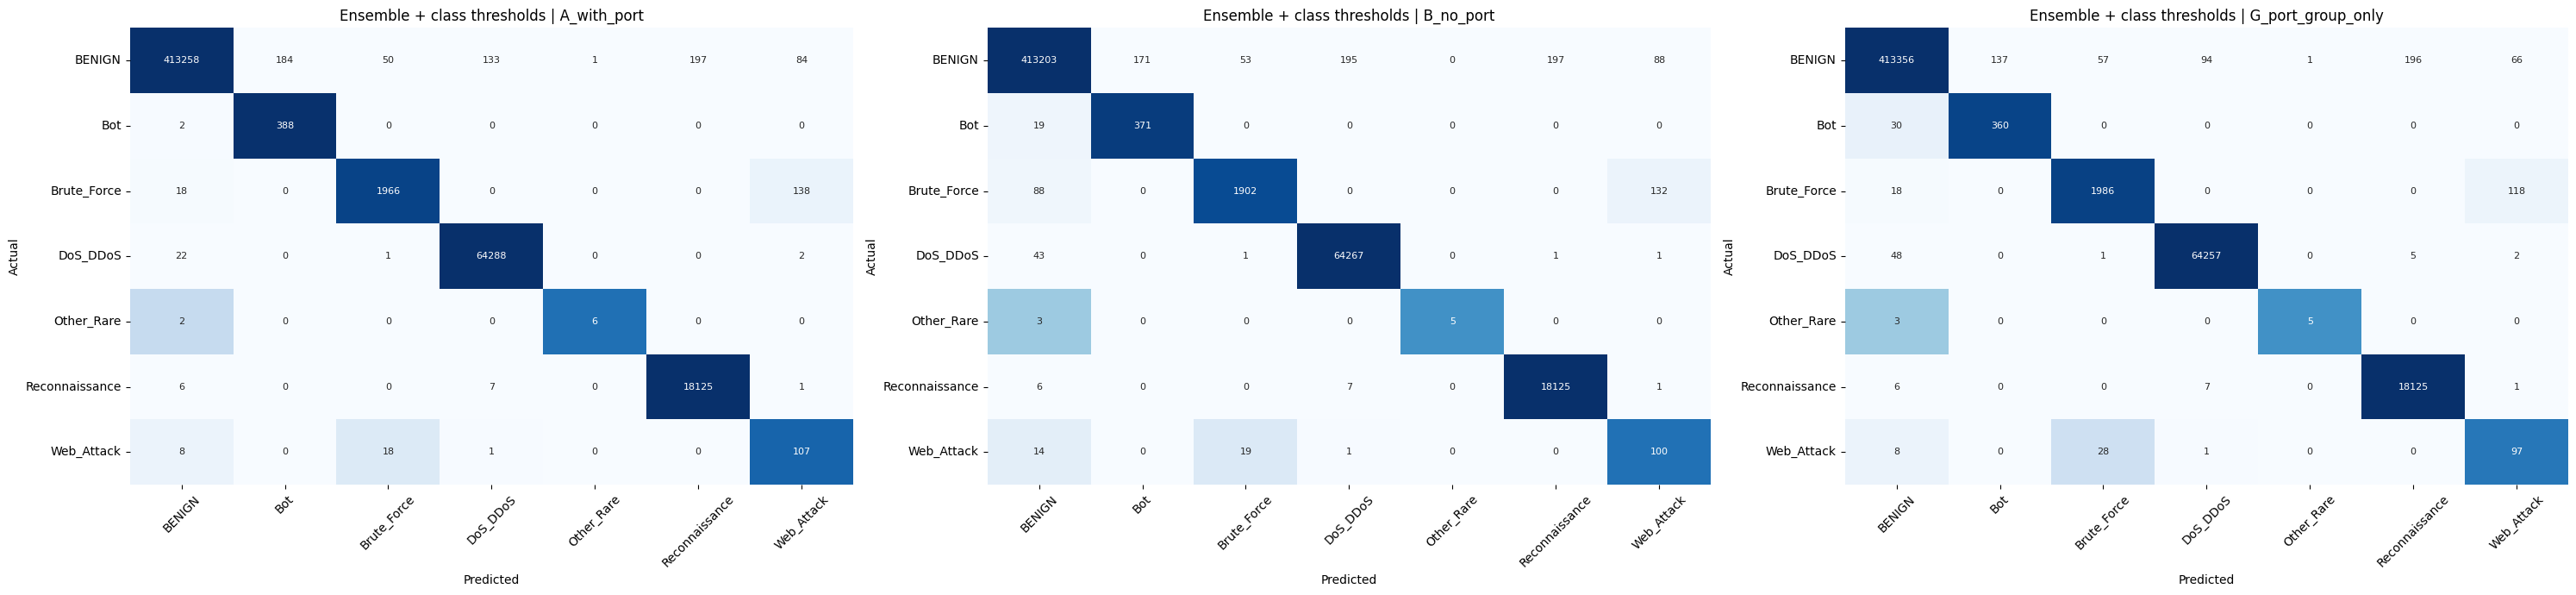

In [ ]:
# per-class precision / recall / F1, Macro-F1 and confusion matrices for every model and setup
model_variants = ["XGBoost", "Neural net", "Ensemble", "Ensemble + class thresholds"]
for model_label in model_variants:
    for setup_label in ALL_SETUPS:
        show_model_report(model_label, setup_label)
    plot_confusions(model_label)

In [ ]:
# headline model: picked on setup-B out-of-fold Macro-F1 only (the test set plays no part in this choice)
oof_candidates = {m_: results[(m_, SETUP_B)]["oof_macro_f1"] for m_ in model_variants}
gain_thr = oof_candidates["Ensemble + class thresholds"] - oof_candidates["Ensemble"]
if gain_thr < MIN_OOF_GAIN:                        # thresholds must earn their place on OOF data
    oof_candidates.pop("Ensemble + class thresholds")
HEADLINE = max(oof_candidates, key=oof_candidates.get)
print("OOF Macro-F1 (setup B, natural-mix weighted):", {k_: round(v_, 4) for k_, v_ in oof_candidates.items()})
print(f"Threshold gain on OOF: {gain_thr:+.4f} (needs >= {MIN_OOF_GAIN}).  Headline model: {HEADLINE}")

OOF Macro-F1 (setup B, natural-mix weighted): {'XGBoost': 0.8015, 'Neural net': 0.6815, 'Ensemble': 0.8244, 'Ensemble + class thresholds': 0.8414}
Threshold gain on OOF: +0.0169 (needs >= 0.003).  Headline model: Ensemble + class thresholds


## Port shortcut test (A with port vs B without port)

In [ ]:
# Macro-F1 and per-class recall, A vs B, for every variant
rows_port_test = []
for model_label in model_variants:
    for setup_label in (SETUP_A, SETUP_B):
        res_ = results[(model_label, setup_label)]
        rows_port_test.append({"model": model_label, "setup": setup_label, "Macro-F1": res_["macro_f1"],
                               **{f"recall {name_cls}": res_["per_class"].loc[name_cls, "recall"] for name_cls in class_names_all}})
port_test_table = pd.DataFrame(rows_port_test).set_index(["model", "setup"])
display(port_test_table.round(4))

# change caused by removing the port (B minus A)
port_delta_table = pd.DataFrame(
    [port_test_table.loc[(m_, SETUP_B)] - port_test_table.loc[(m_, SETUP_A)] for m_ in model_variants],
    index=pd.Index(model_variants, name="model (B - A)"))
display(port_delta_table.round(4))

# spread over seeds for the single models (setup A vs B)
display(pd.DataFrame({(m_, s_): {"mean Macro-F1": np.mean(results[(m_, s_)]["seed_macro_f1"]),
                                 "std": np.std(results[(m_, s_)]["seed_macro_f1"]),
                                 "min": np.min(results[(m_, s_)]["seed_macro_f1"]),
                                 "max": np.max(results[(m_, s_)]["seed_macro_f1"])}
                      for m_ in ("XGBoost", "Neural net") for s_ in (SETUP_A, SETUP_B)}).T.round(4)
        .rename_axis(["model (single seeds)", "setup"]))

# which classes lose most recall without port (text is generated from the numbers above)
support_test = results[("XGBoost", SETUP_A)]["per_class"]["support"]
for model_label in [HEADLINE] + [m_ for m_ in ("XGBoost", "Neural net") if m_ != HEADLINE]:
    recall_change = port_delta_table.loc[model_label].drop("Macro-F1")
    recall_change.index = [idx_.replace("recall ", "") for idx_ in recall_change.index]
    worst_three = recall_change.sort_values().head(3)
    f1_a, f1_b = port_test_table.loc[(model_label, SETUP_A), "Macro-F1"], port_test_table.loc[(model_label, SETUP_B), "Macro-F1"]
    drops_text = ", ".join(f"{name_cls} {chg_:+.3f} (n={int(support_test[name_cls])})" for name_cls, chg_ in worst_three.items())
    print(f"{model_label}: Macro-F1 {f1_a:.4f} -> {f1_b:.4f} ({f1_b - f1_a:+.4f}). Largest recall changes without port: {drops_text}.")
print("n = test-set flows of that class; changes on classes with n < 30 are noisy.")

Macro-F1  recall BENIGN  recall Bot  \
model                       setup                                              
XGBoost                     A_with_port    0.8416         0.9979      0.9974   
                            B_no_port      0.8202         0.9974      0.9872   
Neural net                  A_with_port    0.7388         0.9963      0.6897   
                            B_no_port      0.6628         0.9947      0.8205   
Ensemble                    A_with_port    0.8512         0.9980      0.9974   
                            B_no_port      0.8343         0.9975      0.9872   
Ensemble + class thresholds A_with_port    0.8577         0.9984      0.9949   
                            B_no_port      0.8462         0.9983      0.9513   

                                         recall Brute_Force  recall DoS_DDoS  \
model                       setup                                              
XGBoost                     A_with_port              0.9571           0.9998   
                            B_no_port                0.9566           0.9997   
Neural net                  A_with_port              0.9953           0.9995   
                            B_no_port                0.9599           0.9958   
Ensemble                    A_with_port              0.9656           0.9998   
                            B_no_port                0.9623           0.9997   
Ensemble + class thresholds A_with_port              0.9265           0.9996   
                            B_no_port                0.8963           0.9993   

                                         recall Other_Rare  \
model                       setup                            
XGBoost                     A_with_port              0.750   
                            B_no_port                0.625   
Neural net                  A_with_port              0.625   
                            B_no_port                0.125   
Ensemble                    A_with_port              0.750   
                            B_no_port                0.625   
Ensemble + class thresholds A_with_port              0.750   
                            B_no_port                0.625   

                                         recall Reconnaissance  \
model                       setup                                
XGBoost                     A_with_port                 0.9993   
                            B_no_port                   0.9993   
Neural net                  A_with_port                 0.9992   
                            B_no_port                   0.9991   
Ensemble                    A_with_port                 0.9993   
                            B_no_port                   0.9993   
Ensemble + class thresholds A_with_port                 0.9992   
                            B_no_port                   0.9992   

                                         recall Web_Attack  
model                       setup                           
XGBoost                     A_with_port             0.6418  
                            B_no_port               0.6194  
Neural net                  A_with_port             0.0000  
                            B_no_port               0.0000  
Ensemble                    A_with_port             0.5821  
                            B_no_port               0.5746  
Ensemble + class thresholds A_with_port             0.7985  
                            B_no_port               0.7463

,Macro-F1,recall BENIGN,recall Bot,recall Brute_Force,recall DoS_DDoS,recall Other_Rare,recall Reconnaissance,recall Web_Attack
model (B - A),,,,,,,,
XGBoost,-0.0215,-0.0005,-0.0103,-0.0005,-0.0001,-0.125,0.0000,-0.0224
Neural net,-0.0760,-0.0015,0.1308,-0.0353,-0.0037,-0.500,-0.0001,0.0000
Ensemble,-0.0169,-0.0005,-0.0103,-0.0033,-0.0001,-0.125,0.0000,-0.0075
Ensemble + class thresholds,-0.0115,-0.0001,-0.0436,-0.0302,-0.0003,-0.125,0.0000,-0.0522


mean Macro-F1     std     min     max
model (single seeds) setup                                             
XGBoost              A_with_port         0.8427  0.0082  0.8365  0.8543
                     B_no_port           0.8194  0.0058  0.8116  0.8256
Neural net           A_with_port         0.7328  0.0137  0.7225  0.7522
                     B_no_port           0.6603  0.0060  0.6519  0.6656

Ensemble + class thresholds: Macro-F1 0.8577 -> 0.8462 (-0.0115). Largest recall changes without port: Other_Rare -0.125 (n=8), Web_Attack -0.052 (n=134), Bot -0.044 (n=390).
XGBoost: Macro-F1 0.8416 -> 0.8202 (-0.0215). Largest recall changes without port: Other_Rare -0.125 (n=8), Web_Attack -0.022 (n=134), Bot -0.010 (n=390).
Neural net: Macro-F1 0.7388 -> 0.6628 (-0.0760). Largest recall changes without port: Other_Rare -0.500 (n=8), Brute_Force -0.035 (n=2122), DoS_DDoS -0.004 (n=64313).
n = test-set flows of that class; changes on classes with n < 30 are noisy.


## [ADDED] Port-group ablation: best model with vs without `Destination_Port_Group`

Same headline model, same hyper-parameters, same split. **G** = all columns of the standard pipeline, including `Destination_Port_Group` (no raw port number).
**B** = the same columns minus every port-derived column. The only difference between the two rows is the port information.

Read the result carefully: B removes port information only. It still uses flag counts, header lengths, TCP window sizes, packet-length and inter-arrival-time features and the Active/Idle flags,
so a good B score shows the model does not *need* the port, not that it works from packet-length and timing alone.

In [ ]:
# [ADDED] 2-row port-group ablation for the headline model (test set, scored once)
rows_abl = []
for row_name, setup_label in [("WITH Destination_Port_Group (G)", SETUP_G), ("WITHOUT Destination_Port_Group (B)", SETUP_B)]:
    res_ = results[(HEADLINE, setup_label)]
    pc_ = res_["per_class"]
    rows_abl.append({"setup": row_name, "Macro-F1": res_["macro_f1"], "accuracy": res_["accuracy"],
                     **{f"F1 {k}": pc_.loc[k, "f1"] for k in class_names_all}})
ablation_table = pd.DataFrame(rows_abl).set_index("setup")
display(ablation_table.round(4))

gap_g_b = ablation_table.iloc[1]["Macro-F1"] - ablation_table.iloc[0]["Macro-F1"]
sd_g = np.std(results[("XGBoost", SETUP_G)]["seed_macro_f1"]); sd_b = np.std(results[("XGBoost", SETUP_B)]["seed_macro_f1"])
print(f"Headline model: {HEADLINE}")
print(f"Macro-F1 with port group {ablation_table.iloc[0]['Macro-F1']:.4f} -> without {ablation_table.iloc[1]['Macro-F1']:.4f}  (change {gap_g_b:+.4f}).")
print(f"For scale: seed-to-seed std of single XGBoost test Macro-F1 is {sd_g:.4f} (G) and {sd_b:.4f} (B); changes of that size are noise.")
print("Removing the port group " + ("does NOT collapse the detector" if gap_g_b > -COLLAPSE_DROP else "COLLAPSES the detector") + f" (collapse = drop of more than {COLLAPSE_DROP}).")
print("Classes with very few test flows (Other_Rare) change by whole flows; read them with care.")

,Macro-F1,accuracy,F1 BENIGN,F1 Bot,F1 Brute_Force,F1 DoS_DDoS,F1 Other_Rare,F1 Reconnaissance,F1 Web_Attack
setup,,,,,,,,,
WITH Destination_Port_Group (G),0.8470,0.9983,0.9992,0.8117,0.9471,0.9988,0.7143,0.9941,0.4641
WITHOUT Destination_Port_Group (B),0.8462,0.9979,0.9989,0.7961,0.9285,0.9981,0.7692,0.9942,0.4386


Headline model: Ensemble + class thresholds
Macro-F1 with port group 0.8470 -> without 0.8462  (change -0.0008).
For scale: seed-to-seed std of single XGBoost test Macro-F1 is 0.0037 (G) and 0.0058 (B); changes of that size are noise.
Removing the port group does NOT collapse the detector (collapse = drop of more than 0.1).
Classes with very few test flows (Other_Rare) change by whole flows; read them with care.


## Anomaly detector for ultra-rare flows

Isolation Forest fitted on 70% of the BENIGN pool rows only; the alert threshold is set on the other 30% so that about `ANOM_FPR_TARGET` of BENIGN is flagged. Evaluation is BENIGN vs attack on the shared test set.

In [ ]:
def run_isolation_forest(mat_pool_in, mat_test_in):
    # fit on BENIGN only; threshold from held-out BENIGN scores
    benign_ix = np.where(y_pool_codes == class_to_code["BENIGN"])[0]
    benign_ix = np.random.default_rng(SEED).permutation(benign_ix)
    n_fit_benign = int(0.7 * len(benign_ix))
    fit_ix, cal_ix = benign_ix[:n_fit_benign][:ANOM_FIT_ROWS], benign_ix[n_fit_benign:]
    iso_obj = IsolationForest(n_estimators=300, max_samples=2048, contamination="auto",
                              n_jobs=-1, random_state=SEED).fit(mat_pool_in[fit_ix])
    score_cal = iso_obj.score_samples(mat_pool_in[cal_ix])                       # higher = more normal
    return iso_obj.score_samples(mat_test_in), float(np.quantile(score_cal, ANOM_FPR_TARGET))

def record_anomaly(setup_label, score_test_all, cutoff_score):
    is_attack_true = y_true_test != "BENIGN"
    flagged_arr = score_test_all < cutoff_score
    tp_ = int((flagged_arr & is_attack_true).sum()); fp_ = int((flagged_arr & ~is_attack_true).sum())
    fn_ = int((~flagged_arr & is_attack_true).sum())
    prec_ = tp_ / max(tp_ + fp_, 1); rec_ = tp_ / max(tp_ + fn_, 1)
    results[("Isolation Forest", setup_label)] = {
        "kind": "anomaly", "flagged": flagged_arr, "cutoff": cutoff_score,
        "attack_precision": prec_, "attack_recall": rec_,
        "attack_f1": 2 * prec_ * rec_ / max(prec_ + rec_, 1e-12),
        "binary_macro_f1": float(f1_score(is_attack_true, flagged_arr, average="macro")),
        "roc_auc": float(roc_auc_score(is_attack_true, -score_test_all)),
        "pr_auc": float(average_precision_score(is_attack_true, -score_test_all)),
        "benign_flagged": fp_, "benign_total": int((~is_attack_true).sum()),
        "y_pred": np.where(flagged_arr, "ANOMALY", "BENIGN"),
    }

t0_iso = time.time()
for setup_label in (SETUP_A, SETUP_B):
    record_anomaly(setup_label, *run_isolation_forest(mat_pool_by_setup[setup_label], mat_test_by_setup[setup_label]))
print(f"Isolation Forest done in {(time.time()-t0_iso)/60:.1f} min")

# attack-side precision / recall (BENIGN vs attack)
display(pd.DataFrame({setup_label: {k_: results[("Isolation Forest", setup_label)][k_]
                                    for k_ in ["attack_precision", "attack_recall", "attack_f1", "binary_macro_f1",
                                               "roc_auc", "pr_auc", "benign_flagged", "benign_total"]}
                      for setup_label in (SETUP_A, SETUP_B)}).round(4))

# share of each class flagged as anomalous
display(pd.DataFrame({setup_label: pd.Series(results[("Isolation Forest", setup_label)]["flagged"]).groupby(y_true_test).mean()
                      for setup_label in (SETUP_A, SETUP_B)}).round(4).rename_axis("class (share flagged)"))

# rare classes: detector vs the headline model and the single models
rows_rare = []
for setup_label in (SETUP_A, SETUP_B):
    flagged_s = results[("Isolation Forest", setup_label)]["flagged"]
    pred_h = results[(HEADLINE, setup_label)]["y_pred"]
    pred_x = results[("XGBoost", setup_label)]["y_pred"]; pred_n = results[("Neural net", setup_label)]["y_pred"]
    for name_cls in RARE_CLASSES_MODEL:
        mask_cls = y_true_test == name_cls
        missed_h = mask_cls & (pred_h == "BENIGN")
        rows_rare.append({
            "setup": setup_label, "class": name_cls, "n_test": int(mask_cls.sum()),
            "IsoForest detected": flagged_s[mask_cls].mean(),
            "headline detected": (pred_h[mask_cls] != "BENIGN").mean(),
            "XGBoost detected": (pred_x[mask_cls] != "BENIGN").mean(),
            "NeuralNet detected": (pred_n[mask_cls] != "BENIGN").mean(),
            "headline missed": int(missed_h.sum()), "  of which IsoForest flags": int(flagged_s[missed_h].sum())})
display(pd.DataFrame(rows_rare).set_index(["setup", "class"]).round(3))

# all attack flows that the headline model calls BENIGN
rows_missed_all = []
for setup_label in (SETUP_A, SETUP_B):
    flagged_s = results[("Isolation Forest", setup_label)]["flagged"]
    missed_all = (y_true_test != "BENIGN") & (results[(HEADLINE, setup_label)]["y_pred"] == "BENIGN")
    rows_missed_all.append({"setup": setup_label, "attacks headline calls BENIGN": int(missed_all.sum()),
                            "IsoForest flags": int(flagged_s[missed_all].sum()),
                            "BENIGN flows IsoForest flags (cost)": results[("Isolation Forest", setup_label)]["benign_flagged"]})
display(pd.DataFrame(rows_missed_all).set_index("setup"))

Isolation Forest done in 0.4 min


,A_with_port,B_no_port
attack_precision,0.6652,0.6567
attack_recall,0.4948,0.4804
attack_f1,0.5675,0.5549
binary_macro_f1,0.7459,0.7389
roc_auc,0.9234,0.9193
pr_auc,0.5717,0.5554
benign_flagged,21197.0000,21374.0000
benign_total,413907.0000,413907.0000


,A_with_port,B_no_port
class (share flagged),,
BENIGN,0.0512,0.0516
Bot,0.2513,0.2513
Brute_Force,0.3648,0.0019
DoS_DDoS,0.6335,0.6269
Other_Rare,0.8750,0.8750
Reconnaissance,0.0269,0.0252
Web_Attack,0.0075,0.0075


n_test  IsoForest detected  headline detected  \
setup       class                                                       
A_with_port Other_Rare       8               0.875              0.750   
            Web_Attack     134               0.007              0.940   
            Bot            390               0.251              0.995   
B_no_port   Other_Rare       8               0.875              0.625   
            Web_Attack     134               0.007              0.896   
            Bot            390               0.251              0.951   

                        XGBoost detected  NeuralNet detected  headline missed  \
setup       class                                                               
A_with_port Other_Rare             0.750               0.625                2   
            Web_Attack             0.955               0.940                8   
            Bot                    0.997               0.690                2   
B_no_port   Other_Rare             0.625               0.125                3   
            Web_Attack             0.940               0.881               14   
            Bot                    0.987               0.821               19   

                          of which IsoForest flags  
setup       class                                   
A_with_port Other_Rare                           1  
            Web_Attack                           1  
            Bot                                  1  
B_no_port   Other_Rare                           2  
            Web_Attack                           1  
            Bot                                  3

,attacks headline calls BENIGN,IsoForest flags,BENIGN flows IsoForest flags (cost)
setup,,,
A_with_port,58,7,21197
B_no_port,173,11,21374


## Comparison and conclusion

In [ ]:
# reference row: the existing custom-weighted logistic regression (read-only use of y_pred_custom)
if "y_pred_custom" in globals():
    record_multiclass("LogReg (existing, custom weights)", SETUP_REF, y_pred_custom)

def binary_view(pred_labels):
    # collapse any model to BENIGN vs attack
    is_attack_true = y_true_test != "BENIGN"; is_attack_pred = np.asarray(pred_labels) != "BENIGN"
    tp_ = int((is_attack_true & is_attack_pred).sum()); fp_ = int((~is_attack_true & is_attack_pred).sum())
    fn_ = int((is_attack_true & ~is_attack_pred).sum())
    return (float(f1_score(is_attack_true, is_attack_pred, average="macro")),
            tp_ / max(tp_ + fp_, 1), tp_ / max(tp_ + fn_, 1))

# one summary table: every model x (with port / without port)
rows_summary = []
for model_label in model_variants + ["Isolation Forest"]:
    row_s = {"model": model_label + (" (HEADLINE)" if model_label == HEADLINE else "")}
    for tag_s, setup_label in (("A", SETUP_A), ("B", SETUP_B)):
        res_ = results[(model_label, setup_label)]
        row_s[f"7-class Macro-F1 {tag_s}"] = res_["macro_f1"] if res_["kind"] == "multiclass" else np.nan
        row_s[f"binary Macro-F1 {tag_s}"], row_s[f"attack precision {tag_s}"], row_s[f"attack recall {tag_s}"] = binary_view(res_["y_pred"])
    row_s["7-class delta (B-A)"] = row_s["7-class Macro-F1 B"] - row_s["7-class Macro-F1 A"]
    row_s["binary delta (B-A)"] = row_s["binary Macro-F1 B"] - row_s["binary Macro-F1 A"]
    rows_summary.append(row_s)
summary_table = pd.DataFrame(rows_summary).set_index("model")
display(summary_table.round(4))
print("Isolation Forest is a BENIGN-vs-attack detector, so only its binary columns apply (7-class = NaN).")
if ("LogReg (existing, custom weights)", SETUP_REF) in results:
    res_ref = results[("LogReg (existing, custom weights)", SETUP_REF)]
    print(f"Reference, existing LogReg (port group only, no raw port): 7-class Macro-F1 {res_ref['macro_f1']:.4f}")

# rare-class precision / recall / F1 for every model and setup (precision shows whether recall is bought by over-flagging)
rows_rare_pr = []
for (model_label, setup_label), res_ in results.items():
    if res_["kind"] == "multiclass":
        rows_rare_pr.append({"model": model_label, "setup": setup_label,
                             **{f"{metric_} {name_cls}": res_["per_class"].loc[name_cls, metric_]
                                for name_cls in RARE_CLASSES_MODEL for metric_ in ("precision", "recall", "f1")}})
rare_table = pd.DataFrame(rows_rare_pr).set_index(["model", "setup"])
rare_table["mean F1 (rare)"] = rare_table[[f"f1 {name_cls}" for name_cls in RARE_CLASSES_MODEL]].mean(axis=1)
display(rare_table.round(4))

,7-class Macro-F1 A,binary Macro-F1 A,attack precision A,attack recall A,7-class Macro-F1 B,binary Macro-F1 B,attack precision B,attack recall B,7-class delta (B-A),binary delta (B-A)
model,,,,,,,,,,
XGBoost,0.8416,0.9969,0.9899,0.9997,0.8202,0.9960,0.9873,0.9995,-0.0215,-0.0008
Neural net,0.7388,0.9939,0.9821,0.9979,0.6628,0.9907,0.9749,0.9947,-0.0760,-0.0032
Ensemble,0.8512,0.9969,0.9903,0.9996,0.8343,0.9961,0.9878,0.9994,-0.0169,-0.0008
Ensemble + class thresholds (HEADLINE),0.8577,0.9975,0.9924,0.9993,0.8462,0.9969,0.9918,0.9980,-0.0115,-0.0006
Isolation Forest,NaN,0.7459,0.6652,0.4948,NaN,0.7389,0.6567,0.4804,NaN,-0.0071


Isolation Forest is a BENIGN-vs-attack detector, so only its binary columns apply (7-class = NaN).
Reference, existing LogReg (port group only, no raw port): 7-class Macro-F1 0.6771


,,precision Other_Rare,recall Other_Rare,f1 Other_Rare,precision Web_Attack,recall Web_Attack,f1 Web_Attack,precision Bot,recall Bot,f1 Bot,mean F1 (rare)
model,setup,,,,,,,,,,
XGBoost,A_with_port,0.7500,0.750,0.7500,0.3282,0.6418,0.4343,0.6516,0.9974,0.7882,0.6575
Neural net,A_with_port,0.8333,0.625,0.7143,0.0000,0.0000,0.0000,0.5223,0.6897,0.5945,0.4363
Ensemble,A_with_port,0.8571,0.750,0.8000,0.3545,0.5821,0.4407,0.6638,0.9974,0.7971,0.6793
Ensemble + class thresholds,A_with_port,0.8571,0.750,0.8000,0.3223,0.7985,0.4592,0.6783,0.9949,0.8067,0.6886
XGBoost,B_no_port,0.8333,0.625,0.7143,0.2712,0.6194,0.3773,0.5896,0.9872,0.7383,0.6099
Neural net,B_no_port,0.3333,0.125,0.1818,0.0000,0.0000,0.0000,0.5096,0.8205,0.6287,0.2702
Ensemble,B_no_port,1.0000,0.625,0.7692,0.3222,0.5746,0.4129,0.6006,0.9872,0.7468,0.6430
Ensemble + class thresholds,B_no_port,1.0000,0.625,0.7692,0.3106,0.7463,0.4386,0.6845,0.9513,0.7961,0.6680
XGBoost,G_port_group_only,0.8571,0.750,0.8000,0.3258,0.6493,0.4339,0.6107,0.9974,0.7575,0.6638


## [ADDED] Progression: logistic regression baseline -> tree ensemble

Every model row uses the same columns (setup G: port group, no raw port) and the same held-out test set.
The logistic row is the custom-weighted logistic regression above, with weights chosen on the validation split.

,Macro-F1,accuracy,Web_Attack precision,Web_Attack recall,Web_Attack F1,Bot F1,Macro-F1 gain vs first row
model,,,,,,,
"Logistic regression (baseline, validated weights)",0.6771,0.9950,0.0000,0.0000,0.0000,0.5333,0.0000
XGBoost,0.8441,0.9978,0.3258,0.6493,0.4339,0.7575,0.1671
Neural net,0.7227,0.9961,0.0000,0.0000,0.0000,0.5897,0.0456
Ensemble,0.8441,0.9978,0.3258,0.6493,0.4339,0.7575,0.1671
Ensemble + class thresholds (HEADLINE),0.8470,0.9983,0.3415,0.7239,0.4641,0.8117,0.1700


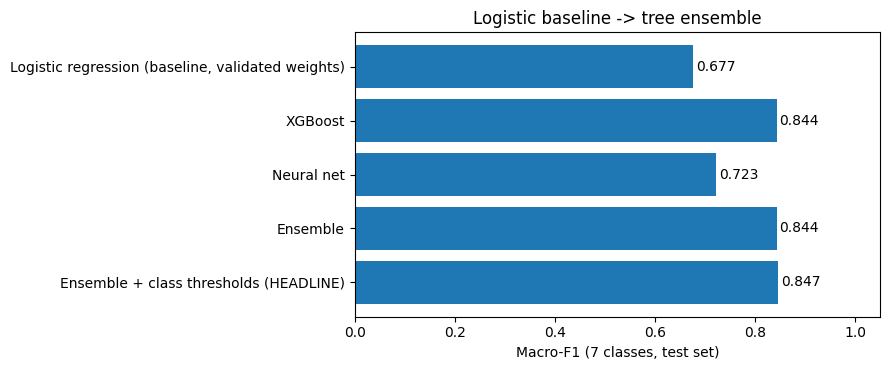

Best Macro-F1 in this table: 0.8470. The 0.90 target from the brief is NOT reached; report the number as it is.


In [ ]:
# [ADDED] Baseline -> non-linear models progression table (same split, same columns)
prog_entries = []
if ("LogReg (existing, custom weights)", SETUP_REF) in results:
    prog_entries.append(("Logistic regression (baseline, validated weights)", ("LogReg (existing, custom weights)", SETUP_REF)))
for m_ in model_variants:
    prog_entries.append((m_ + (" (HEADLINE)" if m_ == HEADLINE else ""), (m_, SETUP_G)))

rows_prog = []
for label_p, key_p in prog_entries:
    res_ = results[key_p]; pc_ = res_["per_class"]
    rows_prog.append({"model": label_p, "Macro-F1": res_["macro_f1"], "accuracy": res_["accuracy"],
                      "Web_Attack precision": pc_.loc["Web_Attack", "precision"], "Web_Attack recall": pc_.loc["Web_Attack", "recall"],
                      "Web_Attack F1": pc_.loc["Web_Attack", "f1"], "Bot F1": pc_.loc["Bot", "f1"]})
progression_table = pd.DataFrame(rows_prog).set_index("model")
progression_table["Macro-F1 gain vs first row"] = progression_table["Macro-F1"] - progression_table["Macro-F1"].iloc[0]
display(progression_table.round(4))

fig_p, ax_p = plt.subplots(figsize=(9, 3.8))
ax_p.barh(progression_table.index[::-1], progression_table["Macro-F1"].iloc[::-1])
for y_i, v_i in enumerate(progression_table["Macro-F1"].iloc[::-1]):
    ax_p.text(v_i + 0.005, y_i, f"{v_i:.3f}", va="center")
ax_p.set_xlim(0, 1.05); ax_p.set_xlabel("Macro-F1 (7 classes, test set)"); ax_p.set_title("Logistic baseline -> tree ensemble")
plt.tight_layout(); plt.show()

best_f1_prog = progression_table["Macro-F1"].max()
print(f"Best Macro-F1 in this table: {best_f1_prog:.4f}. The 0.90 target from the brief is " + ("reached." if best_f1_prog >= 0.90 else "NOT reached; report the number as it is."))

## [REV2-ADDED] Session-grouped evaluation (leave-one-session-out)

The random stratified split puts flows from the same capture session into both train and test. Here each of the 8 capture files is held out in turn: the model is trained on the other 7 sessions and scored on the held-out one.

**How to read it.** In CIC-IDS2017 most attack classes occur in only one session (for example `Web_Attack` only on Thursday morning, `Reconnaissance` only on Friday afternoon). When such a session is held out, the class is *absent from training*, so a class-level recall is not meaningful there. For these classes the table reports the **attack-detection rate** (flow not called BENIGN) instead. Classes that occur in several sessions (BENIGN, DoS_DDoS, Brute_Force, Other_Rare) give a genuine unseen-session generalisation score.

Model: XGBoost with the tuned settings and number of rounds of the main run, setup B (no port information), one seed, up to `SESSION_TRAIN_CAP` flows per class; preprocessing is fitted on the training sessions only. The random-split XGBoost B result is shown beside it for comparison.

In [ ]:
# [REV2-ADDED] Leave-one-session-out evaluation
RUN_SESSION_EVAL = True
SESSION_TRAIN_CAP = 50_000          # flows per class used for training in every fold (lower = faster)
SESSION_SETUP = SETUP_B

session_table = pd.crosstab(df["session"], df["Label_grouped"])
print("Rows per session and grouped class:")
display(session_table)
sessions_per_class = (session_table > 0).sum(axis=0)
print("Number of sessions in which each class occurs:", sessions_per_class.to_dict())

session_summary = None
if RUN_SESSION_EVAL:
    t0_sess = time.time()
    X_sess = X[num_cols_noport + cat_cols_noport]
    y_sess = df["Label_grouped"].to_numpy()
    sess_vec = df["session"].to_numpy()
    n_rounds_sess = int(stage_store[SESSION_SETUP]["n_rounds"])
    xgb_params_sess = dict(XGB_BASE_PARAMS, max_depth=xgb_cfg_best["max_depth"], min_child_weight=xgb_cfg_best["mcw"],
                           learning_rate=xgb_cfg_best["lr"], random_state=SEED)
    rng_sess = np.random.default_rng(SEED)
    pred_oos = np.empty(len(df), dtype=object)
    fold_rows, seen_in_training = [], {}

    for held in sorted(np.unique(sess_vec)):
        te_pos = np.where(sess_vec == held)[0]
        tr_pos = np.where(sess_vec != held)[0]
        present = np.array(sorted(np.unique(y_sess[tr_pos])))
        seen_in_training[held] = set(present)
        code_of = {c_: k_ for k_, c_ in enumerate(present)}

        parts = []
        for c_ in present:
            pos_c = tr_pos[y_sess[tr_pos] == c_]
            parts.append(rng_sess.choice(pos_c, size=min(len(pos_c), SESSION_TRAIN_CAP), replace=False))
        fit_pos = rng_sess.permutation(np.concatenate(parts))
        y_fit = np.array([code_of[c_] for c_ in y_sess[fit_pos]], dtype=np.int64)

        pre_s = build_preproc_setup(num_cols_noport, cat_cols_noport)          # fitted on the training sessions only
        M_fit = np.asarray(pre_s.fit_transform(X_sess.iloc[fit_pos]), dtype=np.float32)
        cnt = np.bincount(y_fit, minlength=len(present)).astype(np.float64)
        w_cls = ((cnt.max() / cnt) ** xgb_cfg_best["wpow"]).astype(np.float32)
        mdl = xgb.XGBClassifier(n_estimators=n_rounds_sess, **xgb_params_sess)
        mdl.fit(M_fit, y_fit, sample_weight=w_cls[y_fit], verbose=False)
        del M_fit

        out_labels = []
        for s0 in range(0, len(te_pos), 200_000):
            blk = te_pos[s0:s0 + 200_000]
            M_te = np.asarray(pre_s.transform(X_sess.iloc[blk]), dtype=np.float32)
            out_labels.append(present[mdl.predict_proba(M_te).argmax(axis=1)])
        pred_oos[te_pos] = np.concatenate(out_labels)

        yt, yp = y_sess[te_pos], pred_oos[te_pos]
        is_ben, is_att = yt == "BENIGN", yt != "BENIGN"
        seen_att = is_att & np.isin(yt, present)
        unseen_att = is_att & ~np.isin(yt, present)
        fold_rows.append({
            "held-out session": held, "flows": len(te_pos),
            "classes in session": ", ".join(f"{k_}:{v_}" for k_, v_ in pd.Series(yt).value_counts().items()),
            "BENIGN false-alarm rate": float((yp[is_ben] != "BENIGN").mean()) if is_ben.any() else np.nan,
            "attack detection rate (not BENIGN)": float((yp[is_att] != "BENIGN").mean()) if is_att.any() else np.nan,
            "exact-class recall, attack classes seen in training": float((yp[seen_att] == yt[seen_att]).mean()) if seen_att.any() else np.nan,
            "detection rate, attack classes NOT in training": float((yp[unseen_att] != "BENIGN").mean()) if unseen_att.any() else np.nan,
            "unseen attack classes": ", ".join(sorted(set(yt[unseen_att]))) or "-"})
        print(f"  held out {held:<45} done ({(time.time() - t0_sess) / 60:.1f} min)")

    session_fold_table = pd.DataFrame(fold_rows).set_index("held-out session")
    print("\nPer held-out session:")
    display(session_fold_table.round(4))

    # pooled over all held-out sessions, per class, next to the random-split XGBoost (setup B) result
    rs_pc = results[("XGBoost", SETUP_B)]["per_class"]
    rows_cmp = []
    for c_ in class_names_all:
        m_c = y_sess == c_
        rows_cmp.append({"class": c_, "flows": int(m_c.sum()), "sessions containing class": int(sessions_per_class.get(c_, 0)),
                         "session-held-out: exact-class recall": float((pred_oos[m_c] == c_).mean()),
                         "session-held-out: flagged as attack": (float((pred_oos[m_c] != "BENIGN").mean()) if c_ != "BENIGN" else np.nan),
                         "random split: recall (XGBoost B)": float(rs_pc.loc[c_, "recall"])})
    session_cmp_table = pd.DataFrame(rows_cmp).set_index("class")
    print("Pooled over the 8 held-out sessions vs the random stratified split:")
    display(session_cmp_table.round(4))

    multi_sess = [c_ for c_ in class_names_all if sessions_per_class.get(c_, 0) >= 2]
    p_, r_, f_, s_ = precision_recall_fscore_support(y_sess, pred_oos.astype(str), labels=multi_sess, zero_division=0)
    f1_session = float(np.mean(f_))
    f1_random_same = float(results[("XGBoost", SETUP_B)]["per_class"].loc[multi_sess, "f1"].mean())
    y_bin, p_bin = y_sess != "BENIGN", pred_oos != "BENIGN"
    bin_f1_session = float(f1_score(y_bin, p_bin, average="macro"))
    session_summary = {"classes_in_2plus_sessions": multi_sess,
                       "macro_f1_session_held_out_on_those_classes": f1_session,
                       "macro_f1_random_split_same_classes_xgb_B": f1_random_same,
                       "binary_macro_f1_session_held_out": bin_f1_session,
                       "binary_macro_f1_random_split_xgb_B": binary_view(results[("XGBoost", SETUP_B)]["y_pred"])[0],
                       "attack_detection_rate_pooled": float(p_bin[y_bin].mean()),
                       "benign_false_alarm_rate_pooled": float(p_bin[~y_bin].mean())}
    display(pd.Series(session_summary, name="value").to_frame())
    print("Macro-F1 here is over the classes that occur in at least 2 sessions only; classes confined to one session cannot be classified when their session is held out.")
    print(f"Session evaluation finished in {(time.time() - t0_sess) / 60:.1f} min")

Rows per session and grouped class:


Label_grouped,BENIGN,Bot,Brute_Force,DoS_DDoS,Other_Rare,Reconnaissance,Web_Attack
session,,,,,,,
Friday-WorkingHours-Afternoon-DDos,94979,0,0,127995,0,0,0
Friday-WorkingHours-Afternoon-PortScan,121385,0,0,0,0,90694,0
Friday-WorkingHours-Morning,177911,1948,0,0,0,0,0
Monday-WorkingHours,492073,0,0,0,0,0,0
Thursday-WorkingHours-Afternoon-Infilteration,242054,0,0,0,35,0,0
Thursday-WorkingHours-Morning-WebAttacks,152051,0,1470,0,0,0,673
Tuesday-WorkingHours,396809,0,9144,0,0,0,0
Wednesday-workingHours,392270,0,0,193567,7,0,0


Number of sessions in which each class occurs: {'BENIGN': 8, 'Bot': 1, 'Brute_Force': 2, 'DoS_DDoS': 2, 'Other_Rare': 2, 'Reconnaissance': 1, 'Web_Attack': 1}
  held out Friday-WorkingHours-Afternoon-DDos            done (0.3 min)
  held out Friday-WorkingHours-Afternoon-PortScan        done (0.6 min)
  held out Friday-WorkingHours-Morning                   done (0.9 min)
  held out Monday-WorkingHours                           done (1.2 min)
  held out Thursday-WorkingHours-Afternoon-Infilteration done (1.6 min)
  held out Thursday-WorkingHours-Morning-WebAttacks      done (1.8 min)
  held out Tuesday-WorkingHours                          done (2.2 min)
  held out Wednesday-workingHours                        done (2.6 min)

Per held-out session:


,flows,classes in session,BENIGN false-alarm rate,attack detection rate (not BENIGN),"exact-class recall, attack classes seen in training","detection rate, attack classes NOT in training",unseen attack classes
held-out session,,,,,,,
Friday-WorkingHours-Afternoon-DDos,222974,"DoS_DDoS:127995, BENIGN:94979",0.0047,0.5811,0.5805,NaN,-
Friday-WorkingHours-Afternoon-PortScan,212079,"BENIGN:121385, Reconnaissance:90694",0.0070,0.0037,NaN,0.0037,Reconnaissance
Friday-WorkingHours-Morning,179859,"BENIGN:177911, Bot:1948",0.0021,0.0000,NaN,0.0000,Bot
Monday-WorkingHours,492073,BENIGN:492073,0.0021,NaN,NaN,NaN,-
Thursday-WorkingHours-Afternoon-Infilteration,242089,"BENIGN:242054, Other_Rare:35",0.1321,0.0286,0.0000,NaN,-
Thursday-WorkingHours-Morning-WebAttacks,154194,"BENIGN:152051, Brute_Force:1470, Web_Attack:673",0.0014,0.0285,0.0000,0.0253,Web_Attack
Tuesday-WorkingHours,405953,"BENIGN:396809, Brute_Force:9144",0.0026,0.0052,0.0001,NaN,-
Wednesday-workingHours,585844,"BENIGN:392270, DoS_DDoS:193567, Other_Rare:7",0.0023,0.0226,0.0009,NaN,-


Pooled over the 8 held-out sessions vs the random stratified split:


,flows,sessions containing class,session-held-out: exact-class recall,session-held-out: flagged as attack,random split: recall (XGBoost B)
class,,,,,
BENIGN,2069532,8,0.9822,NaN,0.9974
Bot,1948,1,0.0000,0.0000,0.9872
Brute_Force,10614,2,0.0001,0.0087,0.9566
DoS_DDoS,321562,2,0.2316,0.2449,0.9997
Other_Rare,42,2,0.0000,0.0238,0.6250
Reconnaissance,90694,1,0.0000,0.0037,0.9993
Web_Attack,673,1,0.0000,0.0253,0.6194


,value
classes_in_2plus_sessions,"[BENIGN, Brute_Force, DoS_DDoS, Other_Rare]"
macro_f1_session_held_out_on_those_classes,0.322027
macro_f1_random_split_same_classes_xgb_B,0.907854
binary_macro_f1_session_held_out,0.603148
binary_macro_f1_random_split_xgb_B,0.99601
attack_detection_rate_pooled,0.186094
benign_false_alarm_rate_pooled,0.017809


Macro-F1 here is over the classes that occur in at least 2 sessions only; classes confined to one session cannot be classified when their session is held out.
Session evaluation finished in 2.6 min


In [ ]:
# [REV2-CHANGED] two lines appended (session-grouped result, metric key)
# conclusion
n_rare_test = {name_cls: int((y_true_test == name_cls).sum()) for name_cls in RARE_CLASSES_MODEL}
res_hb, res_ha = results[(HEADLINE, SETUP_B)], results[(HEADLINE, SETUP_A)]
concl_lines = []

# 1. headline result and A-B gap
gap_ = res_hb["macro_f1"] - res_ha["macro_f1"]
concl_lines.append(f"1. Headline model ({HEADLINE}, chosen on out-of-fold data): Macro-F1 {res_ha['macro_f1']:.3f} with port, {res_hb['macro_f1']:.3f} without port "
                   f"(gap {gap_:+.3f}). " + (f"A drop beyond {COLLAPSE_DROP} would count as a collapse; this does not." if gap_ > -COLLAPSE_DROP
                                             else f"That is a drop beyond {COLLAPSE_DROP}: the model relies on port information."))

# 2. all variants, A -> B
parts_ = [f"{m_} {summary_table.loc[[i_ for i_ in summary_table.index if i_.startswith(m_)][0], '7-class Macro-F1 A']:.3f} -> "
          f"{summary_table.loc[[i_ for i_ in summary_table.index if i_.startswith(m_)][0], '7-class Macro-F1 B']:.3f}" for m_ in model_variants]
concl_lines.append("2. Macro-F1 with port -> without port, all variants: " + "; ".join(parts_) + ".")

# 3. seed spread (how much of a difference is noise)
sd_ = {(m_, s_): np.std(results[(m_, s_)]["seed_macro_f1"]) for m_ in ("XGBoost", "Neural net") for s_ in (SETUP_A, SETUP_B)}
concl_lines.append(f"3. Spread of single-model test Macro-F1 over {N_SEEDS} seeds (std): "
                   + "; ".join(f"{m_} {s_[0]} {v_:.4f}" for (m_, s_), v_ in sd_.items()) + ". Differences smaller than this are noise.")

# 4. did the tuning help? (OOF is where it was optimised; test is the honest check)
parts_ = []
for m_ in model_variants:
    parts_.append(f"{m_}: OOF {results[(m_, SETUP_B)]['oof_macro_f1']:.3f}, test {results[(m_, SETUP_B)]['macro_f1']:.3f}")
concl_lines.append("4. Setup B, out-of-fold vs test Macro-F1 (OOF is natural-mix weighted): " + "; ".join(parts_)
                   + f". Threshold gain on OOF was {gain_thr:+.4f}; on test it is "
                   + f"{results[('Ensemble + class thresholds', SETUP_B)]['macro_f1'] - results[('Ensemble', SETUP_B)]['macro_f1']:+.4f} vs the plain ensemble.")

# 5. rare classes: recall AND precision for the headline model in B
parts_ = []
for name_cls in RARE_CLASSES_MODEL:
    pc_ = res_hb["per_class"].loc[name_cls]
    parts_.append(f"{name_cls} recall {pc_['recall']:.2f}, precision {pc_['precision']:.2f} (n={int(pc_['support'])})")
concl_lines.append(f"5. Rare classes, {HEADLINE}, without port: " + "; ".join(parts_) + ".")

# 6. Brute_Force / Web_Attack overlap, read from the headline confusion matrix in B
cm_h = res_hb["confusion"]; ix_bf, ix_wa = class_to_code["Brute_Force"], class_to_code["Web_Attack"]
concl_lines.append(f"6. Web_Attack vs Brute_Force overlap (headline, B): {int(cm_h[ix_bf, ix_wa])} Brute_Force flows predicted Web_Attack, "
                   f"{int(cm_h[ix_wa, ix_bf])} Web_Attack flows predicted Brute_Force; Web_Attack F1 is {res_hb['per_class'].loc['Web_Attack', 'f1']:.3f}.")

# 7. anomaly detector
parts_ = []; adds_ = []
for setup_label in (SETUP_A, SETUP_B):
    r_if = results[("Isolation Forest", setup_label)]
    flagged_s = r_if["flagged"]
    miss_rare = np.isin(y_true_test, RARE_CLASSES_MODEL) & (results[(HEADLINE, setup_label)]["y_pred"] == "BENIGN")
    share_rare = flagged_s[miss_rare].mean() if miss_rare.any() else np.nan
    adds_.append(bool(miss_rare.any() and share_rare >= ADD_VALUE_MIN_CATCH))
    parts_.append(f"{setup_label[0]}: attack precision {r_if['attack_precision']:.3f}, recall {r_if['attack_recall']:.3f}, ROC-AUC {r_if['roc_auc']:.3f}; "
                  f"of {int(miss_rare.sum())} rare-class flows the headline calls BENIGN it flags {int(flagged_s[miss_rare].sum())}, "
                  f"at the cost of {r_if['benign_flagged']:,} of {r_if['benign_total']:,} BENIGN flows flagged")
concl_lines.append("7. Isolation Forest - " + "; ".join(parts_) + ". "
                   + (f"It reaches the {ADD_VALUE_MIN_CATCH:.0%} bar in at least one setup, but with that false-alarm load."
                      if any(adds_) else f"It does not reach {ADD_VALUE_MIN_CATCH:.0%} of the rare-class flows the headline model misses, so it adds little."))

# 8. reliability caveat
concl_lines.append("8. Caveats: test support is " + ", ".join(f"{k_}={v_}" for k_, v_ in n_rare_test.items())
                   + " flows, so one flow moves these percentages a lot; Other_Rare scores are close to luck. "
                   + f"Settings used: USE_SAMPLING={USE_SAMPLING}, cap {TRAIN_CAP_PER_CLASS:,}/class, {N_SEEDS} seeds; hyperparameters were tuned on setup B and reused for A.")

# 9. [REV2] session-grouped result
if session_summary is not None:
    concl_lines.append("9. Session-grouped (leave-one-session-out, XGBoost, setup B): "
                       f"binary attack-vs-benign Macro-F1 {session_summary['binary_macro_f1_session_held_out']:.3f} vs {session_summary['binary_macro_f1_random_split_xgb_B']:.3f} on the random split; "
                       f"7-class Macro-F1 over the classes seen in 2+ sessions {session_summary['macro_f1_session_held_out_on_those_classes']:.3f} vs "
                       f"{session_summary['macro_f1_random_split_same_classes_xgb_B']:.3f} on the random split. "
                       "Classes that occur in only one session cannot be classified when that session is held out, so for them only the attack-detection rate is meaningful. "
                       "The random-split scores are therefore likely optimistic for traffic from unseen capture sessions; report both.")

# 10. [REV2] how the metrics must be read (so that numbers are not mixed)
concl_lines.append("10. Metric key: '7-class Macro-F1' = mean F1 over the 7 grouped classes on the held-out random-split test set; 'binary Macro-F1' = BENIGN vs attack after collapsing predictions; "
                   "'OOF Macro-F1' = out-of-fold on the training pool, re-weighted to the natural class mix, preprocessing fitted per fold (used for choices only); "
                   "accuracy is shown for reference and is dominated by BENIGN. Feature rankings are reported separately for the binary and the 15-class target and are descriptive; the model inputs come from Spearman + VIF on the training rows.")

print("\n".join(concl_lines))

1. Headline model (Ensemble + class thresholds, chosen on out-of-fold data): Macro-F1 0.858 with port, 0.846 without port (gap -0.011). A drop beyond 0.1 would count as a collapse; this does not.
2. Macro-F1 with port -> without port, all variants: XGBoost 0.842 -> 0.820; Neural net 0.739 -> 0.663; Ensemble 0.851 -> 0.834; Ensemble + class thresholds 0.858 -> 0.846.
3. Spread of single-model test Macro-F1 over 3 seeds (std): XGBoost A 0.0082; XGBoost B 0.0058; Neural net A 0.0137; Neural net B 0.0060. Differences smaller than this are noise.
4. Setup B, out-of-fold vs test Macro-F1 (OOF is natural-mix weighted): XGBoost: OOF 0.801, test 0.820; Neural net: OOF 0.681, test 0.663; Ensemble: OOF 0.824, test 0.834; Ensemble + class thresholds: OOF 0.841, test 0.846. Threshold gain on OOF was +0.0169; on test it is +0.0119 vs the plain ensemble.
5. Rare classes, Ensemble + class thresholds, without port: Other_Rare recall 0.62, precision 1.00 (n=8); Web_Attack recall 0.75, precision 0.31 (n=

## [ADDED] Live demo support (notebook version; the Streamlit app is not part of this notebook)

1. Export the fitted preprocessing pipeline and the best model with `joblib`.
2. A repeatable demo function: feed in a batch of flows and get, per flow, the verdict, the attack family, a threat-confidence score and the top 3 features behind the verdict.

`DEMO_SETUP` picks which fitted setup is exported. Default is B (no port information at all); set it to `SETUP_G` to include `Destination_Port_Group`.
Top-3 features come from XGBoost's built-in TreeSHAP values (`pred_contribs`), averaged over the seeds, for the class that was predicted.
If the headline ensemble gives weight to the neural net, the explanation covers the XGBoost part only.

In [ ]:
# [ADDED] Export preprocessing pipeline + best model with joblib
import joblib

DEMO_SETUP = SETUP_B            # SETUP_B = no port information | SETUP_G = with Destination_Port_Group
assert DEMO_SETUP in (SETUP_B, SETUP_G)

demo_preproc, demo_cols_num, demo_cols_cat = {
    SETUP_B: (preproc_noport, num_cols_noport, cat_cols_noport),
    SETUP_G: (preproc_group,  num_cols_group,  cat_cols_group),
}[DEMO_SETUP]
store_demo = stage_store[DEMO_SETUP]

# readable names of the preprocessed columns (numeric first, then one-hot columns), same order as the model input
demo_feature_names = list(demo_cols_num)
if demo_cols_cat:
    enc_ = demo_preproc.named_transformers_["categorical"].named_steps["encoder"]
    demo_feature_names += list(enc_.get_feature_names_out(demo_cols_cat))
assert len(demo_feature_names) == mat_pool_by_setup[DEMO_SETUP].shape[1], "feature-name list does not match the model input width"

# how the headline variant combines the models
w_xgb_demo = {"XGBoost": 1.0, "Neural net": 0.0}.get(HEADLINE, store_demo["ens_w"])
scales_demo = np.asarray(store_demo["scales"], dtype=np.float32) if "thresholds" in HEADLINE else np.ones(n_classes_all, dtype=np.float32)

demo_bundle = {
    "setup": DEMO_SETUP, "headline": HEADLINE, "class_names": list(class_names_all),
    "input_columns": list(demo_cols_num) + list(demo_cols_cat), "preprocessor": demo_preproc,
    "feature_names": demo_feature_names, "xgb_models": store_demo["xgb_models"], "nn_models": store_demo["nn_models"],
    "xgb_weight": float(w_xgb_demo), "class_scales": scales_demo,
}
joblib.dump(demo_bundle, "ids_demo_bundle.joblib", compress=3)
print("Saved ids_demo_bundle.joblib | setup:", DEMO_SETUP, "| model:", HEADLINE, "| input columns:", len(demo_bundle["input_columns"]))
print("Loading it in a fresh session needs the definitions of signed_log1p (and MLPNumpyClassifier if the NN weight is > 0), which live in this notebook.")

Saved ids_demo_bundle.joblib | setup: B_no_port | model: Ensemble + class thresholds | input columns: 38
Loading it in a fresh session needs the definitions of signed_log1p (and MLPNumpyClassifier if the NN weight is > 0), which live in this notebook.


In [ ]:
# [ADDED] Demo function: verdict, attack family, threat confidence, top-3 features
def predict_flows(batch_df, bundle, top_k=3):
    """batch_df: engineered flow features (the columns of X_test). Returns one row per flow."""
    mat = np.asarray(bundle["preprocessor"].transform(batch_df[bundle["input_columns"]]), dtype=np.float32)

    prob = np.mean([m.predict_proba(mat) for m in bundle["xgb_models"]], axis=0)
    if bundle["xgb_weight"] < 1.0:
        prob_nn = np.mean([m.predict_proba(clip_nn_input(mat)) for m in bundle["nn_models"]], axis=0)
        prob = bundle["xgb_weight"] * prob + (1.0 - bundle["xgb_weight"]) * prob_nn
    prob = prob * bundle["class_scales"]
    prob = prob / prob.sum(axis=1, keepdims=True)                     # renormalised, so the confidence is a probability

    classes = np.array(bundle["class_names"])
    pred_idx = prob.argmax(axis=1)
    family = classes[pred_idx]

    # TreeSHAP contributions of the predicted class, averaged over the XGBoost seeds
    contrib = np.mean([m.get_booster().predict(xgb.DMatrix(mat), pred_contribs=True) for m in bundle["xgb_models"]], axis=0)
    contrib_pred = contrib[np.arange(len(mat)), pred_idx, :-1]       # drop the bias column
    names = np.array(bundle["feature_names"])
    top = np.argsort(-contrib_pred, axis=1)[:, :top_k]
    top_text = [", ".join(f"{names[j]} ({contrib_pred[r, j]:+.2f})" for j in top[r]) for r in range(len(mat))]

    benign_col = list(classes).index("BENIGN")
    return pd.DataFrame({
        "verdict": np.where(family == "BENIGN", "BENIGN", "ALERT"),
        "attack_family": family,
        "confidence": prob[np.arange(len(mat)), pred_idx].round(4),
        "attack_probability": (1.0 - prob[:, benign_col]).round(4),
        "top_3_features (SHAP)": top_text,
    }, index=batch_df.index)

# a small, repeatable test batch: up to 2 flows of every class from the held-out test set
demo_batch = (pd.concat([X_test.loc[y_test[y_test == c_].index].sample(min(2, int((y_test == c_).sum())), random_state=7) for c_ in class_names_all])
              .sample(frac=1, random_state=7))
demo_out = predict_flows(demo_batch, demo_bundle)
demo_out.insert(0, "true_label", y_test.loc[demo_batch.index].values)
pd.set_option("display.max_colwidth", 200)
display(demo_out)
print("Demo batch accuracy:", f"{(demo_out['true_label'] == demo_out['attack_family']).mean():.0%}", f"({len(demo_out)} flows)")

,true_label,verdict,attack_family,confidence,attack_probability,top_3_features (SHAP)
1423487,Web_Attack,ALERT,Web_Attack,0.6742,0.8572,"Init_Win_bytes_backward (+2.55), Average Packet Size (+1.10), Flow IAT Min (+0.57)"
309774,Reconnaissance,ALERT,Reconnaissance,0.9955,0.9956,"Init_Win_bytes_backward (+2.94), Bwd Packets/s (+0.61), Subflow Fwd Bytes (+0.49)"
538879,Bot,ALERT,Bot,0.5637,0.5645,"Init_Win_bytes_backward (+2.64), Fwd Header Length (+1.10), Flow Bytes/s (+1.03)"
1536894,Brute_Force,ALERT,Brute_Force,0.9983,0.9990,"Bwd Header Length (+3.25), act_data_pkt_fwd (+1.03), Fwd Packet Length Max (+0.65)"
398446,BENIGN,BENIGN,BENIGN,1.0000,0.0000,"Bwd Packet Length Min (+2.97), forward_unknown (+0.55), Fwd Packet Length Min (+0.49)"
1351637,BENIGN,BENIGN,BENIGN,1.0000,0.0000,"Bwd Packet Length Min (+2.85), forward_unknown (+0.54), Fwd Packet Length Max (+0.46)"
1414943,Web_Attack,BENIGN,BENIGN,0.9318,0.0682,"Init_Win_bytes_backward (+1.57), Fwd Packet Length Max (+0.45), Bwd Header Length (+0.26)"
1182080,Other_Rare,ALERT,Other_Rare,0.9742,0.9743,"act_data_pkt_fwd (+3.25), Subflow Fwd Bytes (+1.47), Fwd Packet Length Max (+1.36)"
1974682,DoS_DDoS,ALERT,DoS_DDoS,0.9820,0.9834,"Init_Win_bytes_backward (+1.86), Bwd Packets/s (+1.21), backward_unknown (+0.76)"
382658,Reconnaissance,ALERT,Reconnaissance,0.9999,1.0000,"Init_Win_bytes_backward (+3.16), min_seg_size_forward (+0.76), Bwd Packets/s (+0.71)"


Demo batch accuracy: 93% (14 flows)


In [ ]:
# [ADDED] Reload check: the exported file reproduces the in-memory predictions
demo_bundle_loaded = joblib.load("ids_demo_bundle.joblib")
demo_out_loaded = predict_flows(demo_batch, demo_bundle_loaded)
assert (demo_out_loaded["attack_family"].values == demo_out["attack_family"].values).all()
assert np.allclose(demo_out_loaded["confidence"].values, demo_out["confidence"].values)
print("joblib reload OK - identical verdicts and confidences.")

try:                                         # optional: download the file when running in Colab
    from google.colab import files as colab_files
    colab_files.download("ids_demo_bundle.joblib")
except Exception as e_dl:
    print("Download skipped:", type(e_dl).__name__)

joblib reload OK - identical verdicts and confidences.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## [REV2-ADDED] Run record: configuration, library versions and result summaries
Writes `run_config.json` (seeds, split sizes, selected features, tuned settings, headline model, library versions, integrity and leakage checks) and CSV files with the result tables.
Keep these files together with the previous version's results so the two runs can be compared.

In [ ]:
# [REV2-ADDED] Save the run record
import json, xgboost as _xgb_mod, statsmodels as _sm_mod
ENV_VERSIONS["xgboost"] = _xgb_mod.__version__; ENV_VERSIONS["statsmodels"] = _sm_mod.__version__

def _plain(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (set, tuple)): return list(o)
    return str(o)

run_config = {
    "seed": SEED, "versions": ENV_VERSIONS,
    "split": {"test_size": 0.20, "stratified_on": "Label", "n_train": int(len(train_idx)), "n_test": int(len(test_idx))},
    "feature_selection": {"spearman_threshold": 0.95, "vif_threshold": 10, "n_selected_numeric": len(selected_features),
                          "selected_numeric_features": selected_features, "categorical_features": categorical_features,
                          "engineered_numeric": [c for c in engineered_numeric if c in numeric_features]},
    "sampling": {"USE_SAMPLING": USE_SAMPLING, "TRAIN_CAP_PER_CLASS": TRAIN_CAP_PER_CLASS, "TUNE_CAP_PER_CLASS": TUNE_CAP_PER_CLASS,
                 "CV_FOLDS": CV_FOLDS, "TUNE_FOLDS": TUNE_FOLDS, "N_SEEDS": N_SEEDS, "SESSION_TRAIN_CAP": SESSION_TRAIN_CAP},
    "cv_preprocessing": "fitted inside every training fold (cv_oof_probs)",
    "tuned": {"xgb": xgb_cfg_best, "nn": nn_cfg_best, "logistic_class_weights": custom_weights, "headline": HEADLINE},
    "integrity_checks": integrity, "leakage_checks": leakage_check_summary, "session_evaluation": session_summary,
}
with open("run_config.json", "w") as fh:
    json.dump(run_config, fh, indent=2, default=_plain)
summary_table.to_csv("results_summary_revised.csv")
progression_table.to_csv("results_progression_revised.csv")
if session_summary is not None:
    session_fold_table.to_csv("results_session_folds_revised.csv"); session_cmp_table.to_csv("results_session_vs_random_revised.csv")
print("Saved: run_config.json, results_summary_revised.csv, results_progression_revised.csv" + (", results_session_*.csv" if session_summary is not None else ""))
try:
    from google.colab import files as colab_files
    for f_ in ["run_config.json", "results_summary_revised.csv", "results_progression_revised.csv"]:
        colab_files.download(f_)
except Exception as e_dl:
    print("Download skipped:", type(e_dl).__name__)

Saved: run_config.json, results_summary_revised.csv, results_progression_revised.csv, results_session_*.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>